# Setup and imports

In [1]:
print('hello')

hello


In [2]:
from pathlib import Path
import getpass
import importlib
import os
import pandas as pd
import sys
from matplotlib import pyplot as plt
import mermaid as md
import seaborn as sns
import rasterio
from rasterio.errors import RasterioIOError
from rasterio.mask import mask
# from rasterio.shutil import exists
from rasterio.errors import RasterioIOError
from typing import Any
from pyproj import CRS
from os import PathLike
from contextlib import nullcontext
import dask
import rasterio
import rioxarray
import xarray as xr
from dask.distributed import Client, as_completed
from rasterio import shutil as rio_shutil
from rasterio.windows import Window

from urllib.parse import urlparse

import hatfield_funcs as hf

# project root = one level up from notebooks but could be higher from here
project_root = Path("../..").resolve()
sys.path.insert(0, str(project_root / "src"))

from biofilm_spectra.processing.spectral_matrix import to_spectral_matrix

from biofilm_spectra.processing.micasense import *
from my_extra_to_hatfield_funcs.io_funcs import *
import image_processor
from image_processor import core_calcs, dask_ops, processor, raster_io, tile_utils

# Pick up library edits without restarting the kernel.
for _module in (core_calcs, dask_ops, raster_io, tile_utils, processor):
    importlib.reload(_module)


In [3]:
plt.style.use("default")
%config InlineBackend.figure_format = 'retina'

In [4]:
CONTAINER_NAME = "wesa-fup-restricted-027817p"

if os.getenv("GA_STORAGE_ACCOUNT_NAME") is not None:
    # this is what gets used when using Azure cloud storage (GeoAnalytics)
    hf.config.configure_azure()
    hf.config.configure_data_root_path(CONTAINER_NAME)
else:
    # root path defined for local data
    raise Exception(
        "This notebook is configured to run in the cloud. Please set up your Azure storage account and container name."
    )
    hf.config.configure_data_root_path(
        r"C:\Users\username\Documents"
    )  # local data folder


# Diagram of worflow

In [5]:
# import ipynbname
# notebook_name = ipynbname.name()

diagram = md.Mermaid("""
flowchart TD
    %% Define the reusable style class
    classDef inputStyle fill:#e8f7ff,stroke:#1c7ed6,stroke-width:2px;
    classDef outputStyle fill:#e6fcf5,stroke:#0ca678,stroke-width:2px;

    %% Define the inputs and apply class
    GNSS[/GNSS Polygons/]
    Lab[/Lab Data/]
    Spectrometer[/Station Spectra from Spectrometer/]
    Imagery[/Imagery Data/]
    AOI[/AOI Polygons/]
    class GNSS,Lab,Spectrometer,Imagery,AOI inputStyle;

    %% Mean spectrum, SA, NDVI
    Spectrometer -.->|Route S| AllSpec["All Station Spectra"]
    Imagery & GNSS --> StationSpec_i[Imagery Station Spectra]
    StationSpec_i -.->|Route I| AllSpec
    AllSpec --> BiofilmMeanSpec[Mean Biofilm Spectrum]
    AllSpec --> SA_s[Station SA]
    SA_s --> SAT[SA Threshold]
    AllSpec --> NDVI_s[Station NDVI]
    NDVI_s --> NDVIT[NDVI Thresholds]

    %% Calibration curve
    NDVI_s --> CalCurve[Calibration Curve]
    Lab --> CalCurve

    %% Mapping
    Imagery --> NDVI_m[NDVI Map]
    Imagery --> SA_m[Spectral Angle Map]
    BiofilmMeanSpec --> SA_m
    SA_m & SAT --> SAmask[SA Mask]
    NDVI_m & NDVIT --> NDVImask[NDVI Mask]
    NDVImask & SAmask & AOI --> BiofilmMap[Biofilm Extent/Exclusion Map]
    BiofilmMap & NDVI_m --> NDVImean[Mean NDVI within Biofilm Extent]
    BiofilmMap --> TotalArea[Total Biofilm Area]

    %% Prediction
    PredMean[Mean Prediction + CI]
    NDVImean --> PredMean
    CalCurve --> PredMean

    PredMean & TotalArea --> PredTotal[/Total Predicted Value over Area/]
    class PredTotal outputStyle;
""")

diagram

## Parameters

In [6]:
SITES = ["brunswick", "westham"]
ROUNDS = [1, 2]
ROUND_BY_DATE = {
    pd.Timestamp("2026-05-04"): 1,
    pd.Timestamp("2026-05-18"): 2,
}
DLS_MODES = ['DLS', 'NoDLS']
DATE_BY_ROUND = {round_number: date for date, round_number in ROUND_BY_DATE.items()}
STATIONS_SAMPLED_AFTER_FLIGHT = {
    ("westham", 1): [f"W{i}" for i in range(24, 31)],
    ("brunswick", 1): [f"B{i}" for i in range(24, 31)],
    ("westham", 2): [
        "W24", "W25", "W26", "W27", "W28", "W29", "W30",
        "W16", "W17", "W18", "W19", "W23",
    ],
    ("brunswick", 2): [
        "B24", "B25", "B26", "B27", "B28", "B29", "B30",
        "B17", "B20", "B21", "B22", "B23",
    ],
}

# Container-scoped SAS URL: read from the environment, else prompt (never hard-code it).
SAS_URL = os.getenv("WESA_SAS_URL", SAS_URL) or getpass.getpass("Azure container SAS URL: ")

# Script choices

route = 'S' # or 'I', for spectrometer vs. imagery

include_trampled_station_for_route_I = False

# False: report only site-round calibration. True: also the round calibration (sites pooled).
INCLUDE_ROUND_CALIBRATION = False

variables_to_predict = [
    'Chla + allomers (mg/m2)',
    'Total FA (mg/m2)',
    'Total PUFA (mg/m2)',
    'Total Carbs (mg/m2)',
    'Proteins (mg/m2)',
    'Caloric (kJ/m2)',
]
variables_to_predict_labels_without_unit = {
    'Chla + allomers (mg/m2)': 'Chlorophyll-a (incl. allomers)',
    'Total FA (mg/m2)': 'Total FA',
    'Total PUFA (mg/m2)': 'Total PUFA',
    'Total Carbs (mg/m2)': 'Total Carbohydrates',
    'Proteins (mg/m2)': 'Proteins',
    'Caloric (kJ/m2)': 'Caloric Content',
}
variables_to_predict_unit = {}
for var in variables_to_predict:
    unit_start = var.find("(")
    unit_end = var.find(")")
    if unit_start != -1 and unit_end != -1:
        variables_to_predict_unit[var] = var[unit_start + 1:unit_end]
    else:
        variables_to_predict_unit[var] = ""

SITE_COLORS = {
    "brunswick": "#0455FE",
    "westham": "#56E00A",
}
SITE_LABELS = {
    "brunswick": "Impact Area",
    "westham": "Westham Control Area",
}

In [7]:
# Input and output paths

# Lab data (part of a combined dataframe)
path_to_combined_dataset = Path("data/processed/full_dataset_combined_grouped.csv")

# Processed spectra
path_spectra_processed_folder = Path("data/processed/spectra/")

# GNSS polygons
path_station_polygons = Path(
    "data/raw_clean/gnss/"
    "biofilm_2x2m_and_3x3m_quadrat_polygons.geojson"
)

# Imagery
# Dataframe with date as index and site as columns. Paths are relative to the
# configured container root.

# df_paths_11b_images = pd.DataFrame(
#     index=list(ROUND_BY_DATE.keys()),
#     columns=list(SITES),
#     dtype="object",
# )
# for _date in df_paths_11b_images.index:
#     for sub_area in df_paths_11b_images.columns:
#         path_within_container = (
#             "aerial_v3_COG/"
#             f"RTB2_10Band_{sub_area.title().replace('_', '')}_"
#             f"{_date.strftime('%Y%m%d')}_DLS_v3.tif"
#         )
#         df_paths_11b_images.loc[_date, sub_area] = path_within_container

df_paths_11b_images = pd.DataFrame()
rows = []
for site in SITES:
    for _round in DATE_BY_ROUND.keys():
        _date = DATE_BY_ROUND[_round]
        for dls_mode in DLS_MODES:
            if dls_mode == 'DLS':
                path_within_container = (
                    "aerial_v3_COG/"
                    f"RTB2_10Band_{site.title().replace('_', '')}_"
                    f"{_date.strftime('%Y%m%d')}_DLS_v3.tif"
                )
            else:
                path_within_container = (
                    f"airborne_data_{_date.strftime('%Y%m%d')}_v2_COG/"
                    f"RTB2_10Band_{site.title().replace('_', '')}_"
                    f"{_date.strftime('%Y%m%d')}_NoDLS_v2.tif"
                )
            # Append all to row
            rows.append(
                {
                    "site": site,
                    "round": _round,
                    "date": _date,
                    "dls_mode": dls_mode,
                    "path": path_within_container,
                }
            )
df_paths_11b_images = pd.DataFrame(rows).set_index(["site", "round", "dls_mode"])


# Output paths
path_processed_imagery = Path("data/processed/imagery/v3")



# Function to externalize

In [8]:
# Working on dataframe of spectra

def compute_spectral_angle_of_dataframe_vs_series(
    df: pd.DataFrame,
    reference_series: pd.Series,
    *,
    degrees: bool = False,
) -> pd.Series:
    """
    Compute the spectral angle between each DataFrame column and a reference.

    Each column of ``df`` is treated as a vector. The reference Series is
    aligned to ``df.index`` before the angles are calculated.

    Parameters
    ----------
    df : pandas.DataFrame
        Input vectors arranged as columns. Rows represent the vector
        dimensions, such as spectral bands.

    reference_series : pandas.Series
        Reference vector. Its index must contain all labels in ``df.index``.

    degrees : bool, default False
        If True, return angles in degrees. Otherwise, return radians.

    Returns
    -------
    pandas.Series
        Spectral angle for each column of ``df``, indexed by ``df.columns``.
        Zero-length vectors produce ``NaN``.

    Raises
    ------
    TypeError
        If ``df`` is not a DataFrame or ``reference_series`` is not a Series.

    ValueError
        If the reference is missing values required by ``df.index``.

    Notes
    -----
    The spectral angle between vectors ``x`` and ``y`` is:

    ``arccos((x · y) / (||x|| ||y||))``

    Examples
    --------
    >>> df = pd.DataFrame(
    ...     {"sample_1": [1, 0], "sample_2": [1, 1]},
    ...     index=["band_1", "band_2"],
    ... )
    >>> reference = pd.Series(
    ...     [1, 0],
    ...     index=["band_1", "band_2"],
    ... )
    >>> compute_spectral_angle_of_dataframe_vs_series(
    ...     df, reference, degrees=True
    ... )
    sample_1     0.0
    sample_2    45.0
    Name: spectral_angle, dtype: float64
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame.")

    if not isinstance(reference_series, pd.Series):
        raise TypeError("reference_series must be a pandas Series.")

    aligned_reference = reference_series.reindex(df.index)

    if aligned_reference.isna().any():
        missing_rows = aligned_reference.index[
            aligned_reference.isna()
        ].tolist()

        raise ValueError(
            f"Reference is missing values for rows: {missing_rows}"
        )

    data = df.to_numpy(dtype=float)
    reference = aligned_reference.to_numpy(dtype=float)

    dot_products = data.T @ reference
    column_norms = np.linalg.norm(data, axis=0)
    reference_norm = np.linalg.norm(reference)
    denominators = column_norms * reference_norm

    cosine = np.divide(
        dot_products,
        denominators,
        out=np.full(df.shape[1], np.nan, dtype=float),
        where=denominators != 0,
    )

    # Account for minor floating-point errors before calling arccos.
    cosine = np.clip(cosine, -1.0, 1.0)
    angles = np.arccos(cosine)

    if degrees:
        angles = np.degrees(angles)

    return pd.Series(
        angles,
        index=df.columns,
        name="spectral_angle",
    )

In [9]:
# Container path

def build_vsiaz_path(
    blob_path: str | Path,
    *,
    container: str = CONTAINER_NAME,
) -> str:
    """
    Build a GDAL ``/vsiaz/`` path for a blob in Azure Storage.

    Backslashes are converted to forward slashes, and leading or trailing
    slashes are removed from the container and blob path.

    Parameters
    ----------
    blob_path : str or pathlib.Path
        Path to the blob within the Azure Storage container.

    container : str, default CONTAINER_NAME
        Name of the Azure Storage container.

    Returns
    -------
    str
        Path in the form ``/vsiaz/<container>/<blob_path>``.

    Raises
    ------
    ValueError
        If ``container`` or ``blob_path`` is empty.

    Examples
    --------
    >>> build_vsiaz_path("rasters/image.tif", container="imagery")
    '/vsiaz/imagery/rasters/image.tif'

    >>> build_vsiaz_path(Path("rasters/image.tif"), container="imagery")
    '/vsiaz/imagery/rasters/image.tif'
    """
    container = container.strip("/")
    normalized_path = str(blob_path).replace("\\", "/").strip("/")

    if not container:
        raise ValueError("container must not be empty.")

    if not normalized_path:
        raise ValueError("blob_path must not be empty.")

    return f"/vsiaz/{container}/{normalized_path}"



def vsiaz_raster_is_accessible(
    path: str | PathLike[str],
) -> bool:
    """
    Return whether Rasterio can currently open a ``/vsiaz/`` raster.

    GDAL caching is disabled for the specified path so that files created
    during the current process can be detected.

    Parameters
    ----------
    path : str or path-like
        GDAL ``/vsiaz/`` path to check.

    Returns
    -------
    bool
        True if Rasterio can open the raster; otherwise False.
    """
    path = str(path)

    with rasterio.Env(CPL_VSIL_CURL_NON_CACHED=path):
        try:
            with rasterio.open(path, sharing=False):
                return True
        except RasterioIOError:
            return False


In [10]:
# Imagery

def extract_horizontal_crs(crs: Any) -> CRS:
    """
    Return the horizontal component of a coordinate reference system.

    If the input is a compound CRS, its projected or geographic component
    is returned. Otherwise, the parsed CRS is returned unchanged.

    Parameters
    ----------
    crs : Any
        Any CRS representation accepted by ``pyproj.CRS.from_user_input``.

    Returns
    -------
    pyproj.CRS
        The horizontal CRS, or the original CRS if it is not compound.

    Raises
    ------
    ValueError
        If a compound CRS does not have exactly one projected or geographic
        component.
    """
    parsed_crs = CRS.from_user_input(crs)

    if not parsed_crs.is_compound:
        return parsed_crs

    horizontal_components = [
        component
        for component in parsed_crs.sub_crs_list
        if component.is_projected or component.is_geographic
    ]

    if len(horizontal_components) != 1:
        raise ValueError(
            "Expected exactly one horizontal component in compound CRS, "
            f"but found {len(horizontal_components)}: {parsed_crs}"
        )

    return horizontal_components[0]

def compact_crs_label(crs: Any) -> str:
    """
    Return a compact, human-readable label for a CRS.

    A recognized authority identifier, such as ``"EPSG:4326"``, is
    preferred. If no authority identifier is available, the CRS name
    is returned.

    Parameters
    ----------
    crs : Any
        Any CRS representation accepted by ``pyproj.CRS.from_user_input``.

    Returns
    -------
    str
        The CRS authority identifier or, if unavailable, its name.
    """
    parsed_crs = CRS.from_user_input(crs)
    authority = parsed_crs.to_authority()

    if authority is not None:
        authority_name, authority_code = authority
        return f"{authority_name}:{authority_code}"

    return parsed_crs.name

def extract_spectra_in_polygon(
    raster: str | PathLike[str] | Any,
    geometry: Any,
    *,
    band_indexes: tuple[int, ...],
    wavelengths_nm: tuple[int | float, ...],
    all_touched: bool = False,
) -> pd.DataFrame:
    """
    Extract valid pixel spectra from within a polygon.

    Each returned row represents one raster pixel, and each column represents
    one selected band labelled by its wavelength. A pixel is included only
    when all selected bands are unmasked and finite.

    Parameters
    ----------
    raster : path-like or open Rasterio dataset
        Raster to read. If an open dataset is supplied, it is not closed by
        this function.

    geometry : GeoJSON-like geometry or object with ``__geo_interface__``
        Polygon used to select pixels. The geometry must be in the same
        coordinate reference system as the raster.

    band_indexes : tuple of int
        One-based raster band indexes to read.

    wavelengths_nm : tuple of int or float
        Wavelength label for each selected band. Must have the same length as
        ``band_indexes``.

    all_touched : bool, default False
        If True, include every pixel touched by the polygon. If False, use
        Rasterio's default pixel-centre selection behaviour.

    Returns
    -------
    pandas.DataFrame
        Extracted spectra with one row per valid pixel and wavelengths as
        column labels. An empty DataFrame is returned when the selected area
        contains no pixels that are valid across all selected bands.

    Raises
    ------
    ValueError
        If no bands are requested, the number of bands and wavelengths
        differs, a band index is outside the raster, or the geometry does
        not overlap the raster.
    """
    if not band_indexes:
        raise ValueError("At least one band index must be provided.")

    if len(band_indexes) != len(wavelengths_nm):
        raise ValueError(
            "band_indexes and wavelengths_nm must have equal length."
        )

    def empty_result() -> pd.DataFrame:
        result = pd.DataFrame(
            columns=wavelengths_nm,
            dtype="float64",
        )
        result.index.name = "pixel_id"
        return result

    raster_context = (
        rasterio.open(raster)
        if isinstance(raster, (str, PathLike))
        else nullcontext(raster)
    )

    with raster_context as src:
        invalid_indexes = [
            index
            for index in band_indexes
            if index < 1 or index > src.count
        ]

        if invalid_indexes:
            raise ValueError(
                f"Band indexes {invalid_indexes} are outside the valid "
                f"range 1–{src.count}."
            )

        data, _ = mask(
            src,
            [geometry],
            indexes=list(band_indexes),
            crop=True,
            filled=False,
            all_touched=all_touched,
        )

    masked_values = np.ma.getmaskarray(data)
    finite_values = np.isfinite(data.data)

    valid_pixels = (
        ~masked_values.any(axis=0)
        & finite_values.all(axis=0)
    )

    if not valid_pixels.any():
        return empty_result()

    spectra = data.data[:, valid_pixels].T.astype(
        "float64",
        copy=False,
    )

    return pd.DataFrame(
        spectra,
        columns=wavelengths_nm,
    ).rename_axis("pixel_id")

# Read and process data

In [11]:
# Lab data

df_combined_grouped = df_test = read_df_from_csv(
    path_to_combined_dataset,
    index_col=[0, 1, 2, 3],
    header=[0, 1, 2],
)

df_combined_grouped_R = df_combined_grouped.xs("R", level="sample_type")
df_combined_R = df_combined_grouped_R.copy()
df_combined_R.columns = df_combined_grouped_R.columns.get_level_values(2)

In [12]:
# Station polygons

def parse_bool(series: pd.Series, field_name: str) -> pd.Series:
    mapping_bool = {
        "true": True,
        "false": False,
        "yes": True,
        "no": False,
        "1": True,
        "0": False,
    }
    result = (
        series.astype("string")
        .str.strip()
        .str.lower()
        .map(mapping_bool)
        .astype("boolean")
    )
    if result.isna().any():
        bad = series[result.isna()].unique().tolist()
        raise ValueError(f"Could not parse {field_name}: {bad}")
    return result


def validate_geometries(
    gdf: gpd.GeoDataFrame,
    label: str,
) -> gpd.GeoDataFrame:
    if gdf.crs is None:
        raise ValueError(
            f"{label} has no CRS metadata. The source CRS must be defined "
            "in the source vector file."
        )

    if gdf.geometry.isna().any():
        raise ValueError(f"{label} contains missing geometries.")

    if gdf.geometry.is_empty.any():
        raise ValueError(f"{label} contains empty geometries.")

    invalid = ~gdf.geometry.is_valid
    if invalid.any():
        warnings.warn(
            f"{label}: repairing {invalid.sum()} invalid geometries "
            "with shapely.make_valid()."
        )
        gdf = gdf.copy()
        gdf.loc[invalid, "geometry"] = (
            gdf.loc[invalid, "geometry"]
            .map(make_valid)
        )

    if (~gdf.geometry.is_valid).any():
        raise ValueError(
            f"{label} still contains invalid geometries after repair."
        )
    if gdf.geometry.is_empty.any():
        raise ValueError(
            f"{label} contains empty geometries after repair."
        )
    return gdf


def load_2x2_station_polygons(path_station_polygons) -> gpd.GeoDataFrame:
    gdf = gpd.read_file(build_vsiaz_path(path_station_polygons))
    print("Station polygon CRS from GeoJSON:", gdf.crs)
    gdf = validate_geometries(gdf, "station polygons").copy()

    required = {"station_name", "round", "is_3x3m", "geometry"}
    missing = required.difference(gdf.columns)
    if missing:
        raise ValueError(
            f"Station polygons are missing columns: {sorted(missing)}"
        )

    gdf["station_id"] = (
        gdf["station_name"]
        .astype("string")
        .str.strip()
    )
    gdf["round"] = pd.to_numeric(
        gdf["round"],
        errors="raise",
    ).astype("int64")
    gdf["is_3x3m"] = parse_bool(gdf["is_3x3m"], "is_3x3m")

    site_map = {"B": "brunswick", "W": "westham"}
    gdf["site"] = gdf["station_id"].str[0].map(site_map)
    if gdf["site"].isna().any():
        bad = (
            gdf.loc[gdf["site"].isna(), "station_id"]
            .unique()
            .tolist()
        )
        raise ValueError(f"Unknown station prefixes: {bad}")

    # Retain the 2 x 2 m station polygons used for imagery comparison.
    gdf = gdf.loc[~gdf["is_3x3m"]].copy()

    duplicate = gdf.duplicated(
        ["site", "round", "station_id"],
        keep=False,
    )
    if duplicate.any():
        raise ValueError(
            "Duplicate 2 x 2 m station polygon keys:\n"
            + gdf.loc[
                duplicate,
                ["site", "round", "station_id"],
            ].to_string(index=False)
        )

    gdf["sampled_after_flight"] = [
        station_id in STATIONS_SAMPLED_AFTER_FLIGHT.get(
            (site, int(round_number)),
            [],
        )
        for site, round_number, station_id in zip(
            gdf["site"],
            gdf["round"],
            gdf["station_id"],
        )
    ]
    gdf["sampling_status"] = np.where(
        gdf["sampled_after_flight"],
        "sampled_after_flight",
        "sampled_before_flight_potentially_trampled",
    )
    return gdf.sort_values(
        ["site", "round", "station_id"]
    ).reset_index(drop=True)


stations = load_2x2_station_polygons(path_station_polygons)
stations.head()

Station polygon CRS from GeoJSON: EPSG:6339


,station_name,round,is_3x3m,extended_protocol,side_m,geometry,station_id,site,sampled_after_flight,sampling_status
0,B1,1,False,No,2.0,"POLYGON ((488833.82 5434224.912, 488835.82 543...",B1,brunswick,False,sampled_before_flight_potentially_trampled
1,B10,1,False,No,2.0,"POLYGON ((488875.848 5433865.401, 488877.848 5...",B10,brunswick,False,sampled_before_flight_potentially_trampled
2,B11,1,False,No,2.0,"POLYGON ((489056.793 5433627.776, 489058.793 5...",B11,brunswick,False,sampled_before_flight_potentially_trampled
3,B12,1,False,No,2.0,"POLYGON ((488897.659 5433305.857, 488899.659 5...",B12,brunswick,False,sampled_before_flight_potentially_trampled
4,B13,1,False,No,2.0,"POLYGON ((488555.946 5433166.387, 488557.946 5...",B13,brunswick,False,sampled_before_flight_potentially_trampled


# Workflow

## Mean Biofilm Spectrum + Station SA to it + Station NDVI
Main outputs:
- df_mean_biofilm_spectra (index as band wavelength, multicolumns as site, round; including 'all')
- df_spectral_angle_thresholds (multiindex as site, round; including 'all')
- df_ndvi_thresholds (same multiindex, and columns: 'ndvi_lower_bound', 'ndvi_upper_bound')

Either coming from the spectrometer data or imagery

### Route S (from Spectrometer)

In [13]:
SCAN_COLUMNS = [
    "station_id",
    "round",
    "sample_type",
    "scan_id",
    "pair_id",
]
frames = []
for site in SITES:
    parquet_path = (
        Path(path_spectra_processed_folder)
        / f"{site}_reflectance_common_wavelengths_scans.parquet"
    )
    frames.append(read_df_from_parquet(parquet_path))

df_spectra_with_metadata = pd.concat(frames, ignore_index=True)

df_reflectance_spectra_R = to_spectral_matrix(
    df_spectra_with_metadata,
    scan_cols=SCAN_COLUMNS,
).xs('R', level='sample_type', axis=1)

# # Keep only real stations
# station_ids = df_reflectance_spectra.columns.get_level_values("station_id").astype(str)
# keep = station_ids.str.startswith(tuple(site[0].upper() for site in SITES))
# df_reflectance_spectra = df_reflectance_spectra.loc[:, keep]

# Add a first level giving the site name (from SITES depending on the first letter appearing in station_id: 'brunswick' for 'B', etc.)
sites = df_reflectance_spectra_R.columns.get_level_values("station_id").str[0].str.upper().map(lambda x: next(site for site in SITES if site[0].upper() == x))
df_reflectance_spectra_R.columns = pd.MultiIndex.from_tuples(
    [(site,) + col for site, col in zip(sites, df_reflectance_spectra_R.columns)],
    names=["site"] + df_reflectance_spectra_R.columns.names,
)

# df_reflectance_spectra_R.head()

In [14]:
df_reflectance_spectra_R_micasense_10B = resample_spectra_to_micasense_10B(df_reflectance_spectra_R)
# df_reflectance_spectra_R_micasense_10B.head()

# # Create a datarframe to hold the mean spectrum over site-round and global scope and a 2 level columns: site and round
# df_mean_spectra_R_micasense_10B = pd.DataFrame(
#     index=df_reflectance_spectra_R_micasense_10B.index,
#     columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
# )
# dict_df_spectral_angle_stats = {}
# for site in SITES + ['all']:
#     for _round in ROUNDS + ['all']:
#         if site in SITES and _round in ROUNDS:
#             df_reflectance_spectra_R_micasense_10B_subset = df_reflectance_spectra_R_micasense_10B.xs((site, _round), level=('site', 'round'), drop_level=False, axis=1)
#         elif site in SITES and _round == 'all':
#             df_reflectance_spectra_R_micasense_10B_subset = df_reflectance_spectra_R_micasense_10B.xs(site, level='site', drop_level=False, axis=1)
#         elif site == 'all' and _round in ROUNDS:
#             df_reflectance_spectra_R_micasense_10B_subset = df_reflectance_spectra_R_micasense_10B.xs(_round, level='round', drop_level=False, axis=1)
#         else:
#             df_reflectance_spectra_R_micasense_10B_subset = df_reflectance_spectra_R_micasense_10B

#         df_mean_spectrum_subset = df_reflectance_spectra_R_micasense_10B_subset.mean(axis=1)
#         df_mean_spectra_R_micasense_10B[(site, _round)] = df_mean_spectrum_subset

#         df_spectral_angles_subset = compute_spectral_angle_of_dataframe_vs_series(
#             df_reflectance_spectra_R_micasense_10B_subset,
#             reference_series=df_mean_spectrum_subset,
#             degrees=True
#         )

#         df_spectral_angle_stats_subset = df_spectral_angles_subset.groupby(['site', 'station_id', 'round']).agg(['mean', 'std'])
#         dict_df_spectral_angle_stats[(site, _round)] = df_spectral_angle_stats_subset

# # Create a dataframe to hold the mean and std of the mean spectral angles for each site-round combination, as well as mean + 3*std
# df_spectral_angle_stats_summary = pd.DataFrame(
#     index=['mean', 'std', 'mean_plus_3std'],
#     columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
# )

# for key, df_spectral_angle_stats in dict_df_spectral_angle_stats.items():
#     mean_val = df_spectral_angle_stats['mean'].mean()
#     std_val = df_spectral_angle_stats['mean'].std()
#     df_spectral_angle_stats_summary[(key[0], key[1])] = [mean_val, std_val, mean_val + 3 * std_val]

# df_mean_spectra_R_micasense_10B.head()
# df_spectral_angle_stats_summary.head()
# df_spectral_angle_thresholds_spectrometer = df_spectral_angle_stats_summary.loc['mean_plus_3std']

In [15]:
def compute_mean_spectra_and_spectral_angle_stats_for_all_site_round_combination_from_all_spectra(df_reflectance_spectra):
    df_reflectance_spectra = df_reflectance_spectra.copy()
    # Create a datarframe to hold the mean spectrum over site-round and global scope and a 2 level columns: site and round
    df_mean_spectra = pd.DataFrame(
        index=df_reflectance_spectra.index,
        columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
    )
    dict_df_spectral_angle_stats = {}
    for site in SITES + ['all']:
        for _round in ROUNDS + ['all']:
            if site in SITES and _round in ROUNDS:
                df_reflectance_spectra_subset = df_reflectance_spectra.xs((site, _round), level=('site', 'round'), drop_level=False, axis=1)
            elif site in SITES and _round == 'all':
                df_reflectance_spectra_subset = df_reflectance_spectra.xs(site, level='site', drop_level=False, axis=1)
            elif site == 'all' and _round in ROUNDS:
                df_reflectance_spectra_subset = df_reflectance_spectra.xs(_round, level='round', drop_level=False, axis=1)
            else:
                df_reflectance_spectra_subset = df_reflectance_spectra

            if len(df_reflectance_spectra_subset.columns) == 0:
                continue

            df_mean_spectrum_subset = df_reflectance_spectra_subset.mean(axis=1)



            df_mean_spectra[(site, _round)] = df_mean_spectrum_subset

            df_spectral_angles_subset = compute_spectral_angle_of_dataframe_vs_series(
                df_reflectance_spectra_subset,
                reference_series=df_mean_spectrum_subset,
                degrees=True
            )

            df_spectral_angle_stats_subset = df_spectral_angles_subset.groupby(['site', 'station_id', 'round']).agg(['mean', 'std'])
            dict_df_spectral_angle_stats[(site, _round)] = df_spectral_angle_stats_subset

    # Create a dataframe to hold the mean and std of the mean spectral angles for each site-round combination, as well as mean + 3*std
    df_spectral_angle_stats_summary = pd.DataFrame(
        index=['mean', 'std', 'mean_plus_3std'],
        columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
    )

    for key, df_spectral_angle_stats in dict_df_spectral_angle_stats.items():
        mean_val = df_spectral_angle_stats['mean'].mean()
        std_val = df_spectral_angle_stats['mean'].std()
        df_spectral_angle_stats_summary[(key[0], key[1])] = [mean_val, std_val, mean_val + 3 * std_val]

    df_spectral_angle_thresholds = df_spectral_angle_stats_summary.loc['mean_plus_3std']

    return df_mean_spectra, dict_df_spectral_angle_stats, df_spectral_angle_stats_summary, df_spectral_angle_thresholds


df_mean_spectra_R_micasense_10B, dict_df_spectral_angle_stats_R_micasense_10B, df_spectral_angle_stats_summary_R_micasense_10B, df_spectral_angle_thresholds_R_micasense_10B = compute_mean_spectra_and_spectral_angle_stats_for_all_site_round_combination_from_all_spectra(df_reflectance_spectra_R_micasense_10B)

<Axes: xlabel='wavelength_nm'>

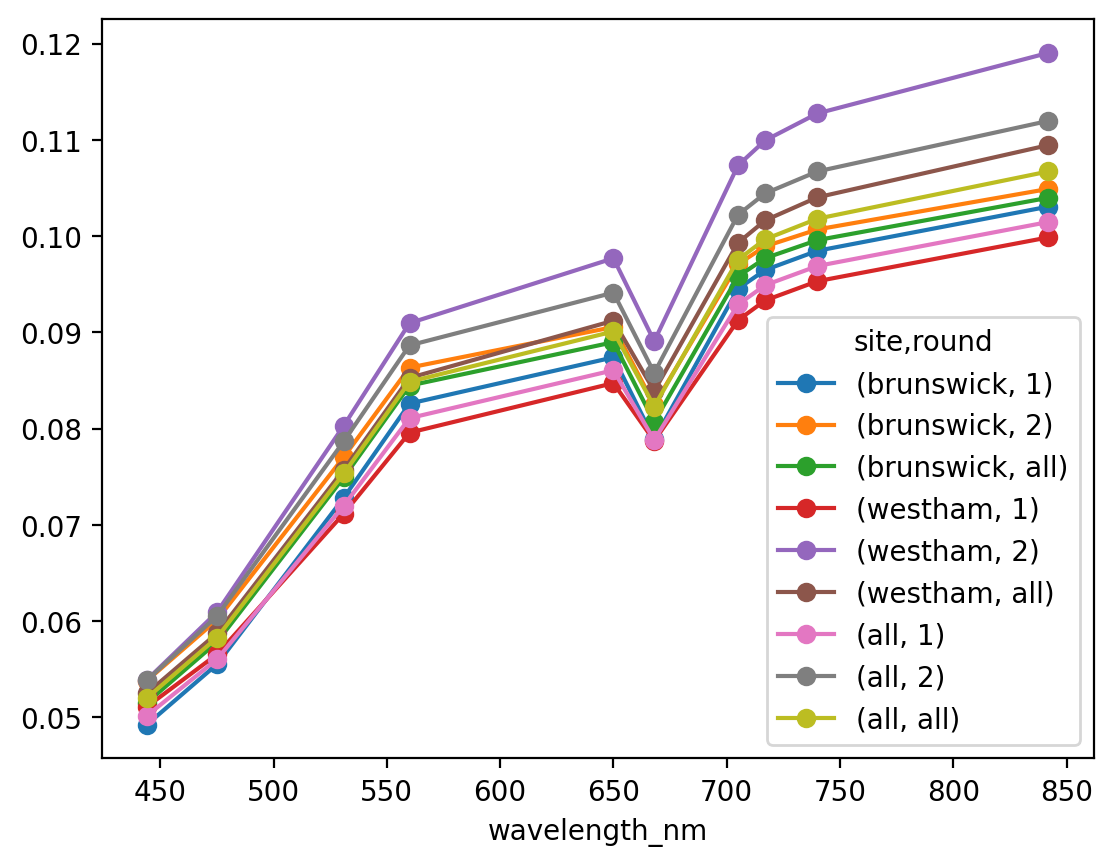

In [16]:
df_mean_spectra_R_micasense_10B.plot(marker='o')

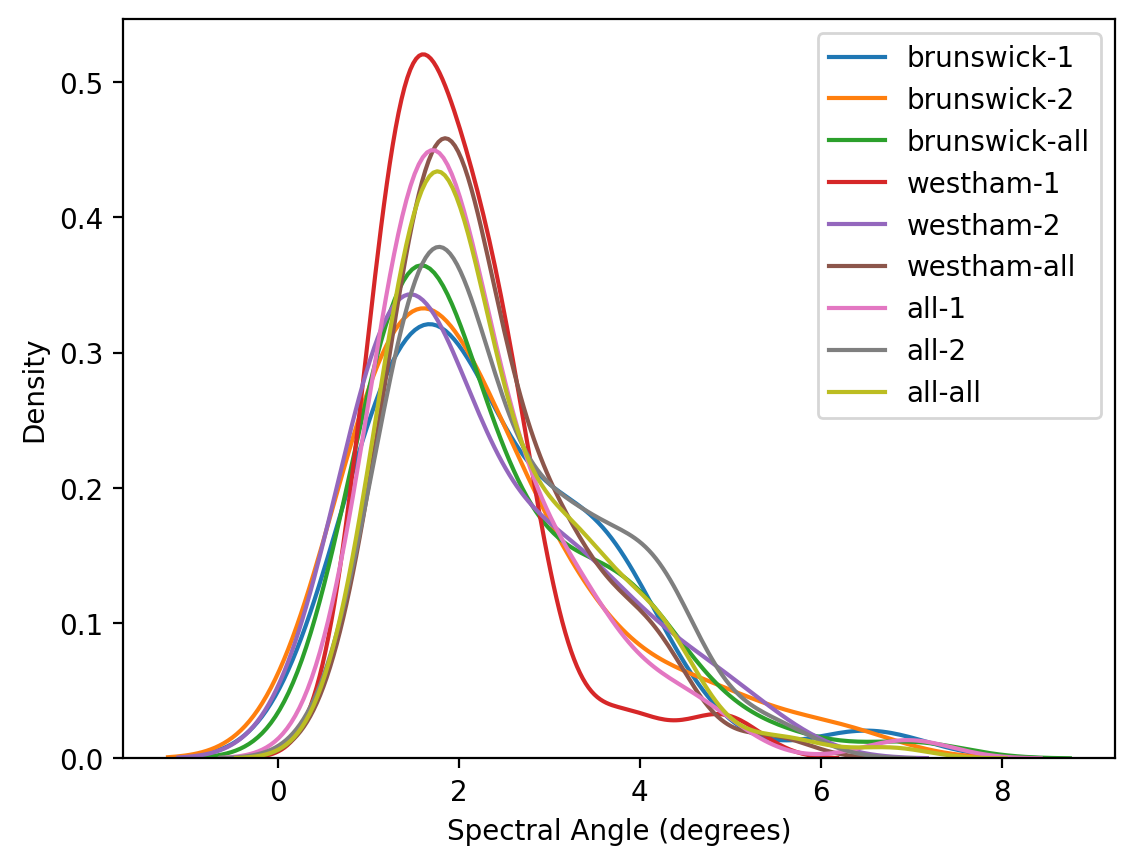

In [17]:
# Plot kernel density of spectral angles for each combination

fig, ax = plt.subplots()
for key, df_spectral_angle_stats in dict_df_spectral_angle_stats_R_micasense_10B.items():
    sns.kdeplot(data=df_spectral_angle_stats['mean'], ax=ax, label=f"{key[0]}-{key[1]}")
ax.set_xlabel("Spectral Angle (degrees)")
ax.set_ylabel("Density")
ax.legend()
plt.show()


In [18]:
# # Compute NDVI of each spectrum, and get mean and max NDVI per station
# # df_indices = pd.DataFrame(index=df_reflectance_spectra_R_micasense_10B.columns)
# df_ndvi = compute_ndvi740(df_reflectance_spectra_R_micasense_10B)

# df_ndvi_stats = df_ndvi.groupby(['site', 'station_id', 'round']).agg(['mean', 'min', 'max'])

# df_ndvi_stats.head() #describe()

# # Get lowest min, mean mean, and max max for each site-round combination
# df_ndvi_stats_site_round_combination = pd.DataFrame(
#     index=['min_min', 'mean_mean', 'max_max'],
#     columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
# )

# results = {}

# for site in SITES + ['all']:
#     for _round in ROUNDS + ['all']:
#         # Handle combinations including marginal totals (None)
#         if site != 'all' and _round != 'all':
#             df_subset = df_ndvi_stats.xs((site, _round), level=('site', 'round'))
#         elif site != 'all' and _round == 'all':
#             df_subset = df_ndvi_stats.xs(site, level='site')
#         elif site == 'all' and _round != 'all':
#             df_subset = df_ndvi_stats.xs(_round, level='round')
#         else:
#             df_subset = df_ndvi_stats

#         # Store stats in a dictionary keyed by the (site, round) tuple
#         results[(site, _round)] = {
#             'min_min': df_subset['min'].min(),
#             'mean_mean': df_subset['mean'].mean(),
#             'max_max': df_subset['max'].max()
#         }

# # Create the DataFrame from the dictionary and set MultiIndex column names
# df_ndvi_stats_site_round_combination = pd.DataFrame(results)
# df_ndvi_stats_site_round_combination.columns.names = ["site", "round"]

# # Ensure the row order matches your desired index order
# df_ndvi_stats_site_round_combination = df_ndvi_stats_site_round_combination.reindex(
#     ['min_min', 'mean_mean', 'max_max']
# )

# df_ndvi_stats_site_round_combination.head()

In [19]:
# # Keep min_min as lower bound and max_max as upper bound
# df_ndvi_thresholds_spectrometer = df_ndvi_stats_site_round_combination.loc[['min_min', 'max_max']].rename(index={'min_min': 'ndvi_lower_bound', 'max_max': 'ndvi_upper_bound'}).T
# df_ndvi_thresholds_spectrometer

In [20]:
def compute_representative_ndvi_values_and_bounds_for_all_site_round_combinations(df_reflectance_spectra):
    df_ndvi = compute_ndvi740(df_reflectance_spectra)
    df_ndvi_stats = df_ndvi.groupby(['site', 'station_id', 'round']).agg(['mean', 'min', 'max'])
    # Get lowest min, mean mean, and max max for each site-round combination
    df_ndvi_stats_site_round_combination = pd.DataFrame(
        index=['min_min', 'mean_mean', 'max_max'],
        columns=pd.MultiIndex.from_tuples([], names=["site", "round"]),
    )
    results = {}
    for site in SITES + ['all']:
        for _round in ROUNDS + ['all']:
            # Handle combinations including marginal totals (None)
            if site != 'all' and _round != 'all':
                df_subset = df_ndvi_stats.xs((site, _round), level=('site', 'round'))
            elif site != 'all' and _round == 'all':
                df_subset = df_ndvi_stats.xs(site, level='site')
            elif site == 'all' and _round != 'all':
                df_subset = df_ndvi_stats.xs(_round, level='round')
            else:
                df_subset = df_ndvi_stats
            # Store stats in a dictionary keyed by the (site, round) tuple
            results[(site, _round)] = {
                'min_min': df_subset['min'].min(),
                'mean_mean': df_subset['mean'].mean(),
                'max_max': df_subset['max'].max()
            }
    # Create the DataFrame from the dictionary and set MultiIndex column names
    df_ndvi_stats_site_round_combination = pd.DataFrame(results)
    df_ndvi_stats_site_round_combination.columns.names = ["site", "round"]
    # Ensure the row order matches desired index order
    df_ndvi_stats_site_round_combination = df_ndvi_stats_site_round_combination.reindex(
        ['min_min', 'mean_mean', 'max_max']
    )
    # Keep min_min as lower bound and max_max as upper bound
    df_ndvi_thresholds = df_ndvi_stats_site_round_combination.loc[['min_min', 'max_max']].rename(index={'min_min': 'ndvi_lower_bound', 'max_max': 'ndvi_upper_bound'}).T
    return df_ndvi_stats_site_round_combination, df_ndvi_thresholds

df_ndvi_stats_site_round_combination, df_ndvi_thresholds_spectrometer = compute_representative_ndvi_values_and_bounds_for_all_site_round_combinations(df_reflectance_spectra_R_micasense_10B)

df_ndvi_thresholds_spectrometer

ndvi_lower_bound  ndvi_upper_bound
site      round                                    
brunswick 1              0.026998          0.298427
          2              0.038185          0.251005
          all            0.026998          0.298427
westham   1              0.016231          0.255767
          2              0.035320          0.239719
          all            0.016231          0.255767
all       1              0.016231          0.298427
          2              0.035320          0.251005
          all            0.016231          0.298427

In [21]:
df_ndvi_stats_site_round_combination

site      brunswick                       westham                      \
round             1         2       all         1         2       all   
min_min    0.026998  0.038185  0.026998  0.016231  0.035320  0.016231   
mean_mean  0.109928  0.099152  0.104540  0.095002  0.115778  0.105390   
max_max    0.298427  0.251005  0.298427  0.255767  0.239719  0.255767   

site            all                      
round             1         2       all  
min_min    0.016231  0.035320  0.016231  
mean_mean  0.102465  0.107465  0.104965  
max_max    0.298427  0.251005  0.298427

### Route I (from Imagery)

In [22]:
def analysis_band_indices(raster_band_count: int) -> tuple[int, ...]:
    """
    Return the 1-based raster band indices used in the analysis.

    All bands are used for a 10-band raster. For an 11-band raster,
    band 5 is excluded.

    Parameters
    ----------
    raster_band_count : int
        Total number of bands in the raster. Must be 10 or 11.

    Returns
    -------
    tuple of int
        One-based band indices to include in the analysis.

    Raises
    ------
    ValueError
        If the raster does not contain 10 or 11 bands.
    """
    if raster_band_count == 10:
        return tuple(range(1, 11))

    if raster_band_count == 11:
        return (1, 2, 3, 4, 6, 7, 8, 9, 10, 11)

    raise ValueError(
        "Expected a 10- or 11-band raster, "
        f"but found {raster_band_count} bands."
    )


def build_imagery_catalog(
    paths: pd.DataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    available_records = []
    audit_records = []

    for (site, round_number, dls_mode), row in paths.iterrows():
        _date = row['date']
        raster_path = build_vsiaz_path(row["path"])

        audit = {
            "site": site,
            "round": round_number,
            "date": pd.Timestamp(_date),
            "dls_mode": dls_mode,
            "relative_path": row["path"],
            "raster_path": raster_path,
        }

        try:
            with rasterio.open(raster_path) as src:
                indexes = analysis_band_indices(src.count)
                horizontal = extract_horizontal_crs(src.crs)

                audit.update(
                    status="available",
                    error="",
                    raster_crs=src.crs.to_string() if src.crs else None,
                    horizontal_crs=compact_crs_label(horizontal),
                    count=src.count,
                    width=src.width,
                    height=src.height,
                    dtype=src.dtypes[0],
                    descriptions=src.descriptions,
                    selected_band_indexes=indexes,
                    bounds=tuple(src.bounds),
                )
                available_records.append(audit.copy())

        except Exception as exc:
            audit.update(
                status="missing_or_unreadable",
                error=f"{type(exc).__name__}: {exc}",
            )

        audit_records.append(audit)
        print(audit)

    audit_df = pd.DataFrame(audit_records)
    available_df = pd.DataFrame(available_records)

    if available_df.empty:
        raise RuntimeError("No imagery rasters could be opened.")

    catalog = (
        available_df
        .set_index(["site", "round"])
        .sort_index()
    )
    return catalog, audit_df

imagery_catalog, imagery_audit = build_imagery_catalog(df_paths_11b_images)

{'site': 'brunswick', 'round': 1, 'date': Timestamp('2026-05-04 00:00:00'), 'dls_mode': 'DLS', 'relative_path': 'aerial_v3_COG/RTB2_10Band_Brunswick_20260504_DLS_v3.tif', 'raster_path': '/vsiaz/wesa-fup-restricted-027817p/aerial_v3_COG/RTB2_10Band_Brunswick_20260504_DLS_v3.tif', 'status': 'available', 'error': '', 'raster_crs': 'EPSG:3157', 'horizontal_crs': 'EPSG:3157', 'count': 11, 'width': 20812, 'height': 14196, 'dtype': 'float32', 'descriptions': (None, None, None, None, None, None, None, None, None, None, None), 'selected_band_indexes': (1, 2, 3, 4, 6, 7, 8, 9, 10, 11), 'bounds': (485298.3820550483, 5431224.926187557, 491541.9820550483, 5435483.726187557)}
{'site': 'brunswick', 'round': 1, 'date': Timestamp('2026-05-04 00:00:00'), 'dls_mode': 'NoDLS', 'relative_path': 'airborne_data_20260504_v2_COG/RTB2_10Band_Brunswick_20260504_NoDLS_v2.tif', 'raster_path': '/vsiaz/wesa-fup-restricted-027817p/airborne_data_20260504_v2_COG/RTB2_10Band_Brunswick_20260504_NoDLS_v2.tif', 'status': '

In [23]:
def safe_normalized_difference(
    band_a: pd.Series,
    band_b: pd.Series,
    *,
    zero_tolerance: float = 1e-8,
) -> pd.Series:
    """
    Calculate a normalized difference while avoiding unstable division.

    The normalized difference is calculated as:

    ``(band_a - band_b) / (band_a + band_b)``

    Results are ``NaN`` where either input is non-finite or where the
    denominator is within ``zero_tolerance`` of zero.

    Parameters
    ----------
    band_a, band_b : pandas.Series
        Numeric bands with matching indices.

    zero_tolerance : float, default 1e-8
        Absolute tolerance used to identify denominators near zero.

    Returns
    -------
    pandas.Series
        Normalized difference with the same index as the input Series.

    Raises
    ------
    ValueError
        If the input indices differ or ``zero_tolerance`` is invalid.
    """
    if not band_a.index.equals(band_b.index):
        raise ValueError("band_a and band_b must have matching indices.")

    if not np.isfinite(zero_tolerance) or zero_tolerance < 0:
        raise ValueError(
            "zero_tolerance must be a finite, non-negative number."
        )

    band_a = band_a.astype("float64")
    band_b = band_b.astype("float64")

    numerator = band_a - band_b
    denominator = band_a + band_b

    valid = (
        np.isfinite(band_a)
        & np.isfinite(band_b)
        & ~np.isclose(
            denominator,
            0.0,
            rtol=0.0,
            atol=zero_tolerance,
        )
    )

    return numerator.div(denominator.where(valid))

def extract_station_imagery(
    catalog: pd.DataFrame,
    station_polygons: gpd.GeoDataFrame,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Extract raster spectra for station polygons.

    Station polygons are matched to each catalog entry by site and round,
    then reprojected to the raster's horizontal CRS when necessary.

    Parameters
    ----------
    catalog : pandas.DataFrame
        Raster catalog indexed by ``(site, round)``. Must contain a
        ``raster_path`` column.

    station_polygons : geopandas.GeoDataFrame
        Station polygons containing ``site``, ``round``, ``station_id``,
        ``sampled_after_flight``, and ``sampling_status`` columns.

    Returns
    -------
    pixels : pandas.DataFrame
        Extracted pixel spectra with station metadata and NDVI740.

    audit : pandas.DataFrame
        Extraction status and pixel count for each station.
    """
    if not isinstance(catalog.index, pd.MultiIndex):
        raise ValueError(
            "catalog must have a MultiIndex containing site and round."
        )

    if catalog.index.nlevels != 2:
        raise ValueError(
            "catalog must have exactly two index levels: site and round."
        )

    if "raster_path" not in catalog.columns:
        raise ValueError(
            "catalog is missing required column 'raster_path'."
        )

    required_station_columns = {
        "site",
        "round",
        "station_id",
        "sampled_after_flight",
        "sampling_status",
        "geometry",
    }
    missing_columns = required_station_columns.difference(
        station_polygons.columns
    )

    if missing_columns:
        raise ValueError(
            "station_polygons is missing required columns: "
            f"{sorted(missing_columns)}"
        )

    if station_polygons.crs is None:
        raise ValueError("station_polygons does not have a CRS.")

    frames: list[pd.DataFrame] = []
    audit_records: list[dict[str, object]] = []

    source_crs = CRS.from_user_input(station_polygons.crs)
    source_crs_name = compact_crs_label(source_crs)

    for (site, round_number), raster_row in catalog.iterrows():
        round_number = int(round_number)

        if round_number not in DATE_BY_ROUND:
            raise ValueError(
                f"No date is configured for round {round_number}."
            )

        subset = station_polygons.loc[
            station_polygons["site"].eq(site)
            & station_polygons["round"].eq(round_number)
        ].copy()

        if subset.empty:
            warnings.warn(
                f"No station polygons for {site}, "
                f"round {round_number}.",
                stacklevel=2,
            )
            continue

        raster_path = raster_row["raster_path"]

        if pd.isna(raster_path):
            raise ValueError(
                f"Raster path is missing for {site}, "
                f"round {round_number}."
            )

        print(
            f"Extracting {site}, round {round_number}, "
            f"{len(subset)} stations"
        )

        with rasterio.open(raster_path) as src:
            if src.crs is None:
                raise ValueError(
                    f"Raster has no CRS: {raster_path}"
                )

            raster_crs = extract_horizontal_crs(src.crs)
            raster_crs_name = compact_crs_label(raster_crs)
            band_indexes = analysis_band_indices(src.count)

            polygons_reprojected = not source_crs.equals(raster_crs)

            if polygons_reprojected:
                stations = subset.to_crs(raster_crs)
            else:
                stations = subset

            for _, station in stations.iterrows():
                station_id = station["station_id"]
                sampled_after_flight = station[
                    "sampled_after_flight"
                ]

                if pd.isna(sampled_after_flight):
                    raise ValueError(
                        "sampled_after_flight is missing for "
                        f"station {station_id!r}."
                    )

                sampled_after_flight = bool(
                    sampled_after_flight
                )

                audit_record = {
                    "site": site,
                    "round": round_number,
                    "date": DATE_BY_ROUND[round_number],
                    "station_id": station_id,
                    "sampled_after_flight": sampled_after_flight,
                    "sampling_status": station["sampling_status"],
                    "source_polygon_crs": source_crs_name,
                    "raster_horizontal_crs": raster_crs_name,
                    "polygons_reprojected": polygons_reprojected,
                }

                try:
                    spectra = extract_spectra_in_polygon(
                        src,
                        station.geometry,
                        wavelengths_nm=MICASENSE_10B_CENTER_WAVELENGTHS,
                        band_indexes=band_indexes,
                    )
                except ValueError as exc:
                    audit_record.update(
                        n_valid_pixels=0,
                        status="mask_error",
                        error=str(exc),
                    )
                    audit_records.append(audit_record)
                    continue

                if spectra.empty:
                    audit_record.update(
                        n_valid_pixels=0,
                        status="no_valid_pixels",
                        error=None,
                    )
                    audit_records.append(audit_record)
                    continue

                spectra = spectra.reset_index()

                spectra.insert(
                    0,
                    "station_id",
                    station_id,
                )
                spectra.insert(
                    0,
                    "date",
                    DATE_BY_ROUND[round_number],
                )
                spectra.insert(
                    0,
                    "round",
                    round_number,
                )
                spectra.insert(
                    0,
                    "site",
                    site,
                )

                spectra["sampled_after_flight"] = (
                    sampled_after_flight
                )
                spectra["sampling_status"] = station[
                    "sampling_status"
                ]

                frames.append(spectra)

                audit_record.update(
                    n_valid_pixels=len(spectra),
                    status="ok",
                    error=None,
                )
                audit_records.append(audit_record)

    audit = pd.DataFrame.from_records(audit_records)

    if not frames:
        raise RuntimeError(
            "No station imagery spectra were extracted."
        )

    pixels = pd.concat(frames, ignore_index=True)

    required_ndvi_bands = {668, 740}
    missing_ndvi_bands = required_ndvi_bands.difference(
        pixels.columns
    )

    if missing_ndvi_bands:
        raise ValueError(
            "Cannot calculate NDVI740 because wavelength columns "
            f"are missing: {sorted(missing_ndvi_bands)}"
        )

    pixels["NDVI740"] = safe_normalized_difference(
        pixels[740],
        pixels[668],
    )

    return pixels, audit

station_imagery_pixels, station_extraction_audit = (
    extract_station_imagery(
        imagery_catalog,
        stations,
    )
)

station_imagery_pixels.head()

Extracting brunswick, round 1, 30 stations
Extracting brunswick, round 1, 30 stations
Extracting brunswick, round 2, 30 stations
Extracting brunswick, round 2, 30 stations
Extracting westham, round 1, 30 stations
Extracting westham, round 1, 30 stations
Extracting westham, round 2, 30 stations
Extracting westham, round 2, 30 stations


,site,round,date,station_id,pixel_id,444,475,531,560,650,668,705,717,740,842,sampled_after_flight,sampling_status,NDVI740
0,brunswick,1,2026-05-04,B1,0,0.017075,0.017751,0.021272,0.022419,0.021982,0.019171,0.024605,0.025037,0.024921,0.027368,False,sampled_before_flight_potentially_trampled,0.130395
1,brunswick,1,2026-05-04,B1,1,0.017032,0.018213,0.021640,0.022827,0.022568,0.019297,0.024982,0.026219,0.025828,0.028528,False,sampled_before_flight_potentially_trampled,0.144722
2,brunswick,1,2026-05-04,B1,2,0.017847,0.018470,0.021825,0.022974,0.022243,0.019713,0.025264,0.025732,0.026053,0.028439,False,sampled_before_flight_potentially_trampled,0.138521
3,brunswick,1,2026-05-04,B1,3,0.018169,0.018502,0.021951,0.023288,0.022484,0.019688,0.025573,0.025204,0.025663,0.027688,False,sampled_before_flight_potentially_trampled,0.131756
4,brunswick,1,2026-05-04,B1,4,0.017853,0.018755,0.022539,0.023384,0.023219,0.020461,0.025947,0.025494,0.026100,0.028234,False,sampled_before_flight_potentially_trampled,0.121112


In [24]:
include_trampled_station_for_route_I = False

In [25]:
if include_trampled_station_for_route_I:
    station_imagery_pixels_subset = station_imagery_pixels.copy()
else:
    station_imagery_pixels_subset = station_imagery_pixels[
        station_imagery_pixels["sampled_after_flight"] == True
    ].copy()
df_reflectance_spectra_imagery_10B = station_imagery_pixels_subset.filter(['site', 'station_id', 'round', 'pixel_id'] + [col for col in MICASENSE_10B_CENTER_WAVELENGTHS])
df_reflectance_spectra_imagery_10B = df_reflectance_spectra_imagery_10B.set_index(["site", "station_id", "round", "pixel_id"]).T

df_mean_spectra_imagery, dict_df_spectral_angle_stats_imagery, df_spectral_angle_stats_summary_imagery, df_spectral_angle_thresholds_imagery = compute_mean_spectra_and_spectral_angle_stats_for_all_site_round_combination_from_all_spectra(df_reflectance_spectra_imagery_10B)


In [26]:
df_ndvi_stats_site_round_combination, df_ndvi_thresholds_imagery = compute_representative_ndvi_values_and_bounds_for_all_site_round_combinations(df_reflectance_spectra_imagery_10B)
df_ndvi_thresholds_imagery

ndvi_lower_bound  ndvi_upper_bound
site      round                                    
brunswick 1              0.059575          0.209074
          2              0.034691          0.229638
          all            0.034691          0.229638
westham   1              0.030546          0.160348
          2              0.030286          0.164662
          all            0.030286          0.164662
all       1              0.030546          0.209074
          2              0.030286          0.229638
          all            0.030286          0.229638

### Route choice

In [27]:
df_mean_spectra_imagery.columns

MultiIndex([('brunswick',     1),
            ('brunswick',     2),
            ('brunswick', 'all'),
            (  'westham',     1),
            (  'westham',     2),
            (  'westham', 'all'),
            (      'all',     1),
            (      'all',     2),
            (      'all', 'all')],
           names=['site', 'round'])

In [28]:
if route == 'S':
    df_mean_biofilm_spectra = df_mean_spectra_R_micasense_10B
    df_spectral_angle_thresholds = df_spectral_angle_thresholds_R_micasense_10B
    df_ndvi_thresholds = df_ndvi_thresholds_spectrometer
elif route == 'I':
    df_mean_biofilm_spectra = df_mean_spectra_imagery
    df_spectral_angle_thresholds = df_spectral_angle_thresholds_imagery
    df_ndvi_thresholds = df_ndvi_thresholds_imagery
else:
    raise ValueError("Invalid route specified. Must be 'S' or 'I'.")

## New imagery

### Setup

In [29]:
import shutil
import tempfile

DASK_SCHEDULER_ADDRESS = os.getenv(
    "DASK_SCHEDULER_ADDRESS",
    "tcp://dask-wesa-fup-jchampion-scheduler:8786",
)

client = Client(DASK_SCHEDULER_ADDRESS)
print(client)

# Workers keep old copies of image_processor in memory; restart to drop them.
client.restart()
print("Workers:", len(client.scheduler_info()["workers"]))

# Workers do not share this filesystem, so ship image_processor to them as a zip.
_zip_dir = tempfile.mkdtemp()
_zip_path = shutil.make_archive(
    str(Path(_zip_dir) / "image_processor"),
    "zip",
    root_dir=project_root / "src",
    base_dir="image_processor",
)
client.upload_file(_zip_path)


def _check_image_processor():
    from image_processor import processor
    return processor.__file__


print(client.run(_check_image_processor))

parsed_sas = urlparse(SAS_URL)
AZURE_STORAGE_ACCOUNT = parsed_sas.netloc.split(".")[0]
SAS_CONTAINER_NAME = parsed_sas.path.lstrip("/")
SAS_TOKEN = parsed_sas.query

if not SAS_CONTAINER_NAME or not SAS_TOKEN:
    raise ValueError("SAS_URL is not a valid container SAS URL.")


def bootstrap_worker_storage():
    """Configure GDAL Azure access inside each Dask worker."""
    import os

    os.environ["AZURE_STORAGE_ACCOUNT"] = AZURE_STORAGE_ACCOUNT
    os.environ["AZURE_STORAGE_SAS_TOKEN"] = SAS_TOKEN
    os.environ["CPL_VSIL_USE_TEMP_FILE_FOR_RANDOM_WRITE"] = "YES"
    os.environ["IGNORE_COG_LAYOUT_BREAK"] = "YES"
    os.environ["GDAL_CACHEMAX"] = "512"


bootstrap_worker_storage()
client.run(bootstrap_worker_storage)
client.register_worker_callbacks(setup=bootstrap_worker_storage)

# Client, scheduler, and workers should use compatible Dask/NumPy versions.
versions = client.get_versions(check=False)
print("Dask version information collected.")


/home/coder/jchampion/Biofilm_LEG13553/confidential-leg13553-biofilm/.venv/lib/python3.10/site-packages/distributed/client.py:1595: VersionMismatchWarning: Mismatched versions found

+-------------+----------+-----------+---------+
| Package     | Client   | Scheduler | Workers |
+-------------+----------+-----------+---------+
| dask        | 2026.8.0 | 2025.9.0  | None    |
| distributed | 2026.8.0 | 2025.9.0  | None    |
| lz4         | None     | 4.4.5     | None    |
| msgpack     | 1.2.2    | 1.2.1     | None    |
| tornado     | 6.5.10   | 6.5.8     | None    |
+-------------+----------+-----------+---------+
  warnings.warn(version_module.VersionMismatchWarning(msg[0]["warning"]))


<Client: 'tcp://100.112.3.207:8786' processes=0 threads=0, memory=0 B>
Workers: 0
{}
Dask version information collected.


### Functions

### NDVI images

In [30]:
df_paths_ndvi_outputs = pd.DataFrame(
    index=pd.MultiIndex.from_tuples(df_paths_11b_images.index, names=["site", "round", "dls_mode"]),
    columns=["path"],
)

for (site, _round, dls_mode), row in df_paths_11b_images.iterrows():
    # Output path (relative to container root)
    path = f"{path_processed_imagery}/ndvi_{row['date']:%Y%m%d}_{site}_{dls_mode}.tif"
    df_paths_ndvi_outputs.loc[(site, _round, dls_mode), 'path'] = path
# for _date in df_paths_11b_images.index:
#     for sub_area in df_paths_11b_images.columns:
#         # Output path (relative to container root)
#         path = f"{path_processed_imagery}/ndvi_{_date:%Y%m%d}_{sub_area}_DLS.tif"
#         df_paths_ndvi_outputs.loc[_date, sub_area] = path

df_paths_ndvi_outputs

path
site      round dls_mode                                                   
brunswick 1     DLS       data/processed/imagery/v3/ndvi_20260504_brunsw...
                NoDLS     data/processed/imagery/v3/ndvi_20260504_brunsw...
          2     DLS       data/processed/imagery/v3/ndvi_20260518_brunsw...
                NoDLS     data/processed/imagery/v3/ndvi_20260518_brunsw...
westham   1     DLS       data/processed/imagery/v3/ndvi_20260504_westha...
                NoDLS     data/processed/imagery/v3/ndvi_20260504_westha...
          2     DLS       data/processed/imagery/v3/ndvi_20260518_westha...
                NoDLS     data/processed/imagery/v3/ndvi_20260518_westha...

In [31]:
# ============================================================================
# CHECK WHICH OUTPUTS ALREADY EXIST
# ============================================================================

# Build a list of (date, site, input_path, output_path, exists) tuples
processing_plan = []

for (site, _round, dls_mode), row in df_paths_11b_images.iterrows():
    _date = row['date']
    input_rel = df_paths_11b_images.loc[(site, _round, dls_mode), 'path']
    output_rel = df_paths_ndvi_outputs.loc[(site, _round, dls_mode), 'path']

    input_vsiaz = build_vsiaz_path(input_rel)
    output_vsiaz = build_vsiaz_path(output_rel)

    # Check if output already exists
    output_exists = vsiaz_raster_is_accessible(output_vsiaz)

    processing_plan.append({
        "date": _date,
        "site": site,
        "input_path": input_vsiaz,
        "output_path": output_vsiaz,
        "exists": output_exists,
        })

df_processing_plan = pd.DataFrame(processing_plan)
print(df_processing_plan)

# Filter to only those that need processing
df_to_process = df_processing_plan[~df_processing_plan["exists"]].copy()
print(f"\nNeed to process: {len(df_to_process)} out of {len(df_processing_plan)}")
print(df_to_process)

        date       site                                         input_path  \
0 2026-05-04  brunswick  /vsiaz/wesa-fup-restricted-027817p/aerial_v3_C...   
1 2026-05-04  brunswick  /vsiaz/wesa-fup-restricted-027817p/airborne_da...   
2 2026-05-18  brunswick  /vsiaz/wesa-fup-restricted-027817p/aerial_v3_C...   
3 2026-05-18  brunswick  /vsiaz/wesa-fup-restricted-027817p/airborne_da...   
4 2026-05-04    westham  /vsiaz/wesa-fup-restricted-027817p/aerial_v3_C...   
5 2026-05-04    westham  /vsiaz/wesa-fup-restricted-027817p/airborne_da...   
6 2026-05-18    westham  /vsiaz/wesa-fup-restricted-027817p/aerial_v3_C...   
7 2026-05-18    westham  /vsiaz/wesa-fup-restricted-027817p/airborne_da...   

                                         output_path  exists  
0  /vsiaz/wesa-fup-restricted-027817p/data/proces...    True  
1  /vsiaz/wesa-fup-restricted-027817p/data/proces...    True  
2  /vsiaz/wesa-fup-restricted-027817p/data/proces...    True  
3  /vsiaz/wesa-fup-restricted-027817p/data/pr

In [32]:
import tempfile
import uuid
from pathlib import Path
from typing import Any, Callable, Optional, Sequence, Union

import rasterio
from rasterio.windows import Window
from rasterio.windows import transform as window_transform


# ---------------------------------------------------------------------------
# Worker-side functions: self-contained (imports inside), shipped by value.
# ---------------------------------------------------------------------------


def _compute_tile(
    input_specs,
    window_spec,
    tile_spec,
    calculation,
    calculation_kwargs,
    pass_transform,
    out_nodata,
    out_dtype,
):
    """Read the bands of every input for one tile, apply `calculation`, return (1, h, w) `out_dtype`."""
    import numpy as np
    import rasterio
    from rasterio.windows import Window

    tile_row, tile_col, tile_height, tile_width = tile_spec
    window = Window(
        window_spec["col0"] + tile_col,
        window_spec["row0"] + tile_row,
        tile_width,
        tile_height,
    )

    arrays, tile_transform = [], None
    for path, bands in input_specs:
        with rasterio.open(path) as src:
            arrays.append(
                src.read(list(bands), window=window, masked=True, out_dtype="float32")
            )
            if tile_transform is None:
                tile_transform = src.window_transform(window)
    data = np.ma.concatenate(arrays, axis=0) if len(arrays) > 1 else arrays[0]

    kwargs = dict(calculation_kwargs)
    if pass_transform:
        kwargs["transform"] = tile_transform
    result = calculation(data, **kwargs)
    result = np.ma.filled(np.ma.asarray(result, dtype="float32"), np.nan)
    result = np.asarray(result, dtype="float32")

    if result.ndim == 2:
        result = result[np.newaxis]
    if result.shape != (1, tile_height, tile_width):
        raise ValueError(
            f"calculation must return (h, w) or (1, h, w) = "
            f"{(tile_height, tile_width)}; got {result.shape}."
        )

    # Any masked input band, or a non-finite result, becomes nodata.
    invalid = np.ma.getmaskarray(data).any(axis=0)[np.newaxis] | ~np.isfinite(result)

    dtype = np.dtype(out_dtype)
    if dtype.kind in "ui":
        info = np.iinfo(dtype)
        values = result[~invalid]
        if values.size and (values.min() < info.min or values.max() > info.max):
            raise ValueError(f"calculation results do not fit in {dtype.name}.")
        result = np.rint(result)

    return np.where(invalid, out_nodata, result).astype(dtype)


def _create_gtiff(path, profile, band_description):
    import rasterio

    with rasterio.open(path, "w", **profile) as dst:
        dst.set_band_description(1, band_description)
    return path


def _write_tile(previous_write, path, tile_spec, data):
    """Write one tile; `previous_write` only chains tasks so writes are serialized."""
    import rasterio
    from rasterio.windows import Window

    del previous_write
    tile_row, tile_col, tile_height, tile_width = tile_spec
    window = Window(tile_col, tile_row, tile_width, tile_height)

    with rasterio.open(path, "r+") as dst:
        dst.write(data, window=window)
    return tile_spec


def _finalize_to_cog(tmp_path, output_path, compress, blocksize, overviews):
    """Compute stats of the temporary GeoTIFF, then copy it to a COG."""
    import numpy as np
    import rasterio
    from rasterio.shutil import copy as rio_copy

    count, total, v_sum, v_min, v_max = 0, 0, 0.0, np.inf, -np.inf
    with rasterio.open(tmp_path) as src:
        for _, window in src.block_windows(1):
            block = src.read(1, window=window)
            total += block.size
            valid = block[np.isfinite(block) & (block != src.nodata)]
            if valid.size:
                count += valid.size
                v_sum += float(valid.sum(dtype=np.float64))
                v_min = min(v_min, float(valid.min()))
                v_max = max(v_max, float(valid.max()))

    if count == 0:
        raise RuntimeError("No valid pixels in output; check inputs and calculation.")

    rio_copy(
        tmp_path,
        output_path,
        driver="COG",
        compress=compress,
        blocksize=blocksize,
        OVERVIEWS=overviews,
        BIGTIFF="IF_SAFER",
        NUM_THREADS="1",
    )
    return {
        "valid_pixels": count,
        "min": v_min,
        "max": v_max,
        "mean": v_sum / count,
        "fraction_nodata": 1 - count / total,
    }


def _remove_file(path):
    import os

    try:
        os.remove(path)
    except FileNotFoundError:
        pass
    return True


# ---------------------------------------------------------------------------
# Example calculations: (masked array (n_bands, h, w), **kwargs) -> (h, w).
# NaN in the result is written as nodata.
# ---------------------------------------------------------------------------


def ndvi_calculation(data, *, red_index_one_based=1, nir_index_one_based=2, zero_tolerance=1e-8):
    """NDVI; red_index and nir_index are positions along axis 0 of `data`."""
    import numpy as np

    red = np.ma.getdata(data[red_index_one_based - 1]).astype("float32")
    nir = np.ma.getdata(data[nir_index_one_based - 1]).astype("float32")
    numerator = nir - red
    denominator = nir + red

    out = np.full(red.shape, np.nan, dtype="float32")
    ok = np.abs(denominator) > zero_tolerance
    out[ok] = numerator[ok] / denominator[ok]
    return out


def spectral_angle_calculation(data, *, reference, degrees=True):
    """Spectral angle between each pixel and `reference` (one value per band read)."""
    import numpy as np

    values = np.ma.getdata(data).astype("float32")
    reference = np.asarray(reference, dtype="float32")
    if reference.shape != (values.shape[0],):
        raise ValueError(
            f"reference has shape {reference.shape}; expected ({values.shape[0]},)."
        )

    dot = np.einsum("bhw,b->hw", values, reference)
    norm = np.sqrt(np.einsum("bhw,bhw->hw", values, values))
    denominator = norm * np.linalg.norm(reference)

    out = np.full(dot.shape, np.nan, dtype="float32")
    ok = denominator > 0
    angle = np.arccos(np.clip(dot[ok] / denominator[ok], -1, 1))
    out[ok] = np.degrees(angle) if degrees else angle
    return out


def extent_mask(geometries, shape, transform, all_touched=False):
    """True inside any of the GeoJSON-like `geometries` (raster CRS); reusable helper."""
    from rasterio.features import geometry_mask

    return geometry_mask(
        geometries,
        out_shape=shape,
        transform=transform,
        invert=True,
        all_touched=all_touched,
    )


def biofilm_classification_calculation(
    data,
    *,
    ndvi_lower,
    ndvi_upper,
    sa_threshold,
    ndvi_index_one_based=1,
    sa_index_one_based=2,
    extent_geometries=None,
    all_touched=False,
    transform=None,
):
    """
    Class image: 1 * (NDVI < lower) + 2 * (NDVI > upper) + 4 * (SA > threshold).

    0 = possible biofilm. Pixels outside `extent_geometries` (if given) are nodata.
    Needs `pass_transform=True` when `extent_geometries` is given.
    """
    import numpy as np

    ndvi = np.ma.getdata(data[ndvi_index_one_based - 1])
    sa = np.ma.getdata(data[sa_index_one_based - 1])

    out = (
        (ndvi < ndvi_lower) * 1.0
        + (ndvi > ndvi_upper) * 2.0
        + (sa > sa_threshold) * 4.0
    ).astype("float32")

    if extent_geometries is not None:
        out[~extent_mask(extent_geometries, out.shape, transform, all_touched)] = np.nan
    return out


# ---------------------------------------------------------------------------
# Client-side driver
# ---------------------------------------------------------------------------


def process_imagery_in_tiles_with_callable(
    client: Any,
    *,
    calculation: Callable,
    input_path: Union[str, Path, Sequence[Union[str, Path]]],
    output_path: Union[str, Path],
    calculation_kwargs: Optional[dict] = None,
    pass_transform: bool = False,
    read_bands_one_based: Optional[Sequence] = None,
    exclude_bands_one_based: Sequence[int] = (),
    tile_size: int = 1024,
    row0: int = 0,
    col0: int = 0,
    height: Optional[int] = None,
    width: Optional[int] = None,
    compress: str = "LZW",
    blocksize: int = 256,
    overviews: str = "NONE",
    out_dtype: str = "float32",
    out_nodata: Optional[float] = None,
    band_description: str = "result",
    max_in_flight: int = 12,
    max_pending_writes: int = 16,
) -> dict:
    """
    Apply a user-defined function tile by tile on Dask workers and write a
    single-band COG.

    The function is shipped to workers by value, so it must import what it
    needs inside its body and must not rely on notebook globals.

    Parameters
    ----------
    client : dask.distributed.Client
    calculation : callable
        ``calculation(data, **calculation_kwargs)`` where ``data`` is a masked
        float32 array shaped (n_read_bands, tile_h, tile_w), bands in the order
        of ``read_bands_one_based`` (inputs stacked in the order given). Must
        return (tile_h, tile_w) or (1, tile_h, tile_w). Pixels where any read
        band is masked, or where the result is not finite, are written as
        ``out_nodata``.
    input_path : str, Path, or sequence of them
        Raster path(s) (``/vsiaz/...`` or local). Several inputs must share the
        same grid; their bands are stacked along axis 0 in the order given.
    output_path : str or Path
        Output COG path.
    calculation_kwargs : dict, optional
        Extra keyword arguments for ``calculation`` (must be picklable).
    pass_transform : bool, default False
        If True, ``calculation`` also receives ``transform=`` (affine transform
        of the tile, in the raster CRS), e.g. to rasterize a polygon.
    read_bands_one_based : sequence of int, optional
        One-based source bands to read, in the order passed to ``calculation``.
        Default: all bands except ``exclude_bands_one_based``. With several
        inputs, give one such sequence per input (or None for all bands).
    exclude_bands_one_based : sequence of int, default ()
        One-based source bands to skip when ``read_bands_one_based`` is None
        (single input only).
    out_dtype : str, default "float32"
        Output data type, e.g. "float32" or "uint8". Integer outputs are
        rounded and must fit in the type.
    out_nodata : float, optional
        Output nodata value. Default: -9999 for float types, the maximum
        value of the type (e.g. 255 for uint8) for integer types.
    tile_size, row0, col0, height, width, compress, blocksize, overviews,
    band_description, max_in_flight, max_pending_writes
        Same meaning as in ``image_processor``.

    Returns
    -------
    dict
        output_path, total_tiles, valid_pixels, min, max, mean, fraction_nodata.
    """
    import numpy as np
    from dask.distributed import as_completed, wait

    if not callable(calculation):
        raise TypeError("calculation must be callable.")
    if blocksize <= 0 or blocksize % 16 != 0:
        raise ValueError("blocksize must be positive and divisible by 16.")

    dtype = np.dtype(out_dtype)
    if dtype.kind not in "fui":
        raise ValueError(f"out_dtype must be a float or integer type; got {dtype.name}.")
    if out_nodata is None:
        out_nodata = -9999.0 if dtype.kind == "f" else float(np.iinfo(dtype).max)
    if dtype.kind in "ui":
        info = np.iinfo(dtype)
        if not (float(out_nodata).is_integer() and info.min <= out_nodata <= info.max):
            raise ValueError(f"out_nodata={out_nodata} is not valid for {dtype.name}.")

    input_paths = (
        [str(input_path)]
        if isinstance(input_path, (str, Path))
        else [str(p) for p in input_path]
    )
    output_path = str(output_path)
    calculation_kwargs = dict(calculation_kwargs or {})
    multiple = len(input_paths) > 1

    if multiple and exclude_bands_one_based:
        raise ValueError("exclude_bands_one_based is only supported for a single input.")
    if multiple and read_bands_one_based is not None and len(read_bands_one_based) != len(input_paths):
        raise ValueError("read_bands_one_based needs one entry per input raster.")

    input_specs, grid = [], None
    for i, path in enumerate(input_paths):
        with rasterio.open(path) as src:
            this_grid = (src.width, src.height, src.transform, src.crs)
            if grid is None:
                grid = this_grid
                source_profile = src.profile.copy()
            elif this_grid != grid:
                raise ValueError(f"{path} is not on the same grid as {input_paths[0]}.")

            requested = (
                (read_bands_one_based[i] if multiple else read_bands_one_based)
                if read_bands_one_based is not None
                else None
            )
            if requested is None:
                bands = tuple(
                    b for b in range(1, src.count + 1) if b not in set(exclude_bands_one_based)
                )
            else:
                bands = tuple(int(b) for b in requested)
            if not bands or any(b < 1 or b > src.count for b in bands):
                raise ValueError(f"Bands {bands} invalid for {path} ({src.count} bands).")
            input_specs.append((path, bands))

    src_width, src_height, src_transform, _ = grid
    win_height = src_height - row0 if height is None else int(height)
    win_width = src_width - col0 if width is None else int(width)
    if (
        row0 < 0
        or col0 < 0
        or win_height <= 0
        or win_width <= 0
        or row0 + win_height > src_height
        or col0 + win_width > src_width
    ):
        raise ValueError("Processing window is empty or outside the raster.")

    output_profile = source_profile
    output_profile.update(
        driver="GTiff",
        width=win_width,
        height=win_height,
        count=1,
        dtype=dtype.name,
        nodata=float(out_nodata),
        transform=window_transform(Window(col0, row0, win_width, win_height), src_transform),
        tiled=True,
        blockxsize=blocksize,
        blockysize=blocksize,
        compress=compress,
        interleave="band",
        BIGTIFF="IF_SAFER",
    )
    output_profile.pop("photometric", None)

    window_spec = {"row0": row0, "col0": col0, "height": win_height, "width": win_width}
    tile_specs = [
        (r, c, min(tile_size, win_height - r), min(tile_size, win_width - c))
        for r in range(0, win_height, tile_size)
        for c in range(0, win_width, tile_size)
    ]
    total_tiles = len(tile_specs)

    # scheduler_info() can lack "workers" after idle/reconnect; nthreads() queries the scheduler.
    client.wait_for_workers(1, timeout=60)
    workers = list(client.nthreads())
    if not workers:
        raise RuntimeError("No Dask workers available.")
    writer = workers[0]  # Intermediate file lives on this worker's /tmp.

    print(
        f"Region: {win_height} x {win_width}, inputs/bands: {input_specs}, "
        f"output: {dtype.name}, tiles: {total_tiles}"
    )

    tmp_path = str(
        Path(tempfile.gettempdir()) / f"processing_{uuid.uuid4().hex[:10]}.tif"
    )
    client.submit(
        _create_gtiff,
        tmp_path,
        output_profile,
        band_description,
        workers=[writer],
        pure=False,
    ).result()

    tile_iter = iter(tile_specs)
    in_flight = {}

    def submit_compute(tile_spec):
        future = client.submit(
            _compute_tile,
            input_specs,
            window_spec,
            tile_spec,
            calculation,
            calculation_kwargs,
            pass_transform,
            out_nodata,
            dtype.name,
            pure=False,
        )
        in_flight[future] = tile_spec
        return future

    for _ in range(min(max_in_flight, total_tiles)):
        submit_compute(next(tile_iter))

    last_write, pending_writes, done_tiles = None, [], 0
    try:
        completed = as_completed(list(in_flight))
        for compute_future in completed:
            tile_spec = in_flight.pop(compute_future)
            error = compute_future.exception()
            if error is not None:
                raise RuntimeError(
                    f"Compute failed for tile {tile_spec}: "
                    f"{type(error).__name__}: {error}"
                ) from error

            last_write = client.submit(
                _write_tile,
                last_write,
                tmp_path,
                tile_spec,
                compute_future,
                workers=[writer],
                pure=False,
            )
            pending_writes.append(last_write)
            done_tiles += 1
            if done_tiles % max(1, total_tiles // 10) == 0:
                print(f"Computed {done_tiles}/{total_tiles} tiles", flush=True)

            # Backpressure: let half of the queued writes finish.
            if len(pending_writes) >= max_pending_writes:
                half = max_pending_writes // 2
                wait(pending_writes[:half])
                for f in pending_writes[:half]:
                    f.result()
                pending_writes = pending_writes[half:]

            try:
                completed.add(submit_compute(next(tile_iter)))
            except StopIteration:
                pass

        if pending_writes:
            wait(pending_writes)
            for f in pending_writes:
                f.result()

        print("Computing stats and writing COG...", flush=True)
        stats = client.submit(
            _finalize_to_cog,
            tmp_path,
            output_path,
            compress,
            blocksize,
            overviews,
            workers=[writer],
            pure=False,
        ).result()
    finally:
        try:
            client.submit(_remove_file, tmp_path, workers=[writer], pure=False).result()
        except Exception as cleanup_error:
            print(f"Warning: could not remove {tmp_path}: {cleanup_error}")

    return {"output_path": output_path, "total_tiles": total_tiles, **stats}


In [33]:
red_band_index_1_when_11bands = 7
nir_band_index_1_when_11bands = 10

# result = process_imagery_in_tiles_with_callable(
#     client,
#     calculation=ndvi_calculation,
#     input_path=job["input_path"],
#     output_path=job["output_path"],
#     read_bands=[red_band_index_0_when_11bands, nir_band_index_0_when_11bands],
#     calculation_kwargs={
#         "red_index": 0,
#         "nir_index": 1,
#     },
#     band_description="NDVI",
# )

# ============================================================================
# 3. PREPARE BATCH JOBS (without running yet)
# ============================================================================

jobs_to_submit = []

for idx, row in df_to_process.iterrows():
    job_spec = {
        "date": row["date"],
        "site": row["site"],
        "input_path": row["input_path"],
        "output_path": row["output_path"],
    }
    jobs_to_submit.append(job_spec)

print(f"\nPrepared {len(jobs_to_submit)} jobs:")
for i, job in enumerate(jobs_to_submit, 1):
    print(f"{i}. {job['site']} @ {job['date']:%Y-%m-%d}")
    print(f"   Input:  {job['input_path']}")
    print(f"   Output: {job['output_path']}")


# ============================================================================
# 4. SUBMIT ALL JOBS AT ONCE
# ============================================================================

if len(jobs_to_submit) > 0:
    print(f"\n{'=' * 70}")
    print(f"SUBMITTING {len(jobs_to_submit)} JOBS")
    print(f"{'=' * 70}\n")

    results = {}

    for job in jobs_to_submit:
        print(f"\nProcessing: {job['site']} @ {job['date']:%Y-%m-%d}")
        print(f"  Input:  {job['input_path']}")
        print(f"  Output: {job['output_path']}")

        try:
            result = process_imagery_in_tiles_with_callable(
                client,
                calculation=ndvi_calculation,
                input_path=job["input_path"],
                output_path=job["output_path"],
                read_bands_one_based=[
                    red_band_index_1_when_11bands,
                    nir_band_index_1_when_11bands,
                ],
                calculation_kwargs={
                    "red_index_one_based": 1,
                    "nir_index_one_based": 2,
                },
                band_description="NDVI",
            )

            results[f"{job['site']}_{job['date']:%Y%m%d}"] = {
                "status": "success",
                "output_path": result["output_path"],
                "valid_pixels": result["valid_pixels"],
                "ndvi_min": result["min"],
                "ndvi_max": result["max"],
                "ndvi_mean": result["mean"],
            }

            print(
                f"  ✓ Success! NDVI range: {result['min']:.3f} to {result['max']:.3f}"
            )

        except Exception as e:
            results[f"{job['site']}_{job['date']:%Y%m%d}"] = {
                "status": "failed",
                "error": str(e),
            }
            print(f"  ✗ Failed: {e}")

    # Summary
    df_results = pd.DataFrame(results).T
    print(f"\n{'=' * 70}")
    print(f"SUMMARY")
    print(f"{'=' * 70}")
    print(df_results)

else:
    print("\n✓ All NDVI outputs already exist!")



Prepared 0 jobs:

✓ All NDVI outputs already exist!


In [34]:
# # ============================================================================
# # 3. PREPARE BATCH JOBS (without running yet)
# # ============================================================================

# jobs_to_submit = []

# for idx, row in df_to_process.iterrows():
#     job_spec = {
#         "date": row["date"],
#         "site": row["site"],
#         "input_path": row["input_path"],
#         "output_path": row["output_path"],
#         "calculation": "ndvi",
#         "processing_mode": "auto",
#         "drop_band_num": 5,
#         "tile_size": 1024,
#         "compress": "LZW",
#         "blocksize": 256,
#     }
#     jobs_to_submit.append(job_spec)

# print(f"\nPrepared {len(jobs_to_submit)} jobs:")
# for i, job in enumerate(jobs_to_submit, 1):
#     print(f"{i}. {job['site']} @ {job['date']:%Y-%m-%d}")
#     print(f"   Input:  {job['input_path']}")
#     print(f"   Output: {job['output_path']}")


# # ============================================================================
# # 4. SUBMIT ALL JOBS AT ONCE
# # ============================================================================

# if len(jobs_to_submit) > 0:
#     print(f"\n{'='*70}")
#     print(f"SUBMITTING {len(jobs_to_submit)} JOBS")
#     print(f"{'='*70}\n")

#     results = {}

#     for job in jobs_to_submit:
#         print(f"\nProcessing: {job['site']} @ {job['date']:%Y-%m-%d}")
#         print(f"  Input:  {job['input_path']}")
#         print(f"  Output: {job['output_path']}")

#         try:
#             result = processor.process_imagery(
#                 client,
#                 calculation=job["calculation"],
#                 input_path=job["input_path"],
#                 output_path=job["output_path"],
#                 processing_mode=job["processing_mode"],
#                 drop_band_num=job["drop_band_num"],
#                 tile_size=job["tile_size"],
#                 compress=job["compress"],
#                 blocksize=job["blocksize"],
#             )

#             results[f"{job['site']}_{job['date']:%Y%m%d}"] = {
#                 "status": "success",
#                 "output_path": result["output_path"],
#                 "valid_pixels": result["valid_pixels"],
#                 "ndvi_min": result["min"],
#                 "ndvi_max": result["max"],
#                 "ndvi_mean": result["mean"],
#             }

#             print(f"  ✓ Success! NDVI range: {result['min']:.3f} to {result['max']:.3f}")

#         except Exception as e:
#             results[f"{job['site']}_{job['date']:%Y%m%d}"] = {
#                 "status": "failed",
#                 "error": str(e),
#             }
#             print(f"  ✗ Failed: {e}")

#     # Summary
#     df_results = pd.DataFrame(results).T
#     print(f"\n{'='*70}")
#     print(f"SUMMARY")
#     print(f"{'='*70}")
#     print(df_results)

# else:
#     print("\n✓ All NDVI outputs already exist!")

### Spectral angle images

In [35]:
# ============================================================================
# 1. DEFINE SPECTRAL ANGLE CASES AND OUTPUT PATHS
# ============================================================================

# False: only the matching (site, round) reference. True: also the 'all' references.
USE_ALL_REFERENCE_CASES = False
USE_ONLY_ALL_ALL_REFERENCE_FOR_SPECTRAL_ANGLE = True

sa_cases = []
for (site, _round, dls_mode), row in df_paths_11b_images.iterrows():
    _date = row['date']
    site_cases = ["all"] if USE_ONLY_ALL_ALL_REFERENCE_FOR_SPECTRAL_ANGLE else ([site, "all"] if USE_ALL_REFERENCE_CASES else [site])
    round_cases = ["all"] if USE_ONLY_ALL_ALL_REFERENCE_FOR_SPECTRAL_ANGLE else ([_round, "all"] if USE_ALL_REFERENCE_CASES else [_round])

    for site_case in site_cases:
        for round_case in round_cases:
            sa_cases.append({
                "date": _date,
                "round": _round,
                "site": site,
                "dls_mode": dls_mode,
                "site_case": site_case,
                "round_case": round_case,
                "input_rel": df_paths_11b_images.loc[(site, _round, dls_mode), 'path'],
                "output_rel": (
                    f"{path_processed_imagery}/spectral_angle_"
                    f"{_date:%Y%m%d}_{site}_{dls_mode}_"
                    f"ref_from_{site_case}_{round_case}.tif"
                ),
            })

df_sa_cases = pd.DataFrame(sa_cases)
print("Spectral angle cases defined:")
print(df_sa_cases[["date", "site", "dls_mode", "site_case", "round_case", "output_rel"]])


Spectral angle cases defined:
        date       site dls_mode site_case round_case  \
0 2026-05-04  brunswick      DLS       all        all   
1 2026-05-04  brunswick    NoDLS       all        all   
2 2026-05-18  brunswick      DLS       all        all   
3 2026-05-18  brunswick    NoDLS       all        all   
4 2026-05-04    westham      DLS       all        all   
5 2026-05-04    westham    NoDLS       all        all   
6 2026-05-18    westham      DLS       all        all   
7 2026-05-18    westham    NoDLS       all        all   

                                          output_rel  
0  data/processed/imagery/v3/spectral_angle_20260...  
1  data/processed/imagery/v3/spectral_angle_20260...  
2  data/processed/imagery/v3/spectral_angle_20260...  
3  data/processed/imagery/v3/spectral_angle_20260...  
4  data/processed/imagery/v3/spectral_angle_20260...  
5  data/processed/imagery/v3/spectral_angle_20260...  
6  data/processed/imagery/v3/spectral_angle_20260...  
7  data/processe

In [36]:
# ============================================================================
# 2. CHECK INPUTS, EXISTING OUTPUTS AND REFERENCE SPECTRA
# ============================================================================

sa_processing_plan = []
input_exists_cache = {}

for _, case in df_sa_cases.iterrows():
    input_vsiaz = build_vsiaz_path(case["input_rel"])
    output_vsiaz = build_vsiaz_path(case["output_rel"])

    if input_vsiaz not in input_exists_cache:
        input_exists_cache[input_vsiaz] = vsiaz_raster_is_accessible(input_vsiaz)

    output_exists = vsiaz_raster_is_accessible(output_vsiaz)
    print(output_vsiaz, output_exists)

    ref_key = (case["site_case"], case["round_case"])
    ref_spectrum = None

    if not input_exists_cache[input_vsiaz]:
        ref_status = "input_missing"
    elif ref_key not in df_mean_biofilm_spectra.columns:
        ref_status = "reference_missing"
    else:
        ref_spectrum = df_mean_biofilm_spectra[ref_key]
        ref_status = "ok" if ref_spectrum.notna().all() else "reference_has_nan"

    sa_processing_plan.append({
        "date": case["date"],
        "round": case["round"],
        "site": case["site"],
        "input_path": input_vsiaz,
        "output_path": output_vsiaz,
        "exists": output_exists,
        "reference_status": ref_status,
        "reference_info": f"site {ref_key[0]}, round {ref_key[1]}",
        "reference_spectrum": ref_spectrum,
    })

df_sa_processing_plan = pd.DataFrame(sa_processing_plan)

print("\nSpectral angle processing plan:")
print(df_sa_processing_plan[["date", "site", "exists", "reference_status", "reference_info"]])

df_sa_to_process = df_sa_processing_plan[
    (~df_sa_processing_plan["exists"])
    & (df_sa_processing_plan["reference_status"] == "ok")
].copy()

print(f"\nCan process: {len(df_sa_to_process)} out of {len(df_sa_processing_plan)}")
print(df_sa_to_process[["date", "site", "reference_info"]])


/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260504_brunswick_DLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260504_brunswick_NoDLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260518_brunswick_DLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260518_brunswick_NoDLS_ref_from_all_all.tif True


/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260504_westham_DLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260504_westham_NoDLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260518_westham_DLS_ref_from_all_all.tif True
/vsiaz/wesa-fup-restricted-027817p/data/processed/imagery/v3/spectral_angle_20260518_westham_NoDLS_ref_from_all_all.tif True

Spectral angle processing plan:
        date       site  exists reference_status       reference_info
0 2026-05-04  brunswick    True               ok  site all, round all
1 2026-05-04  brunswick    True               ok  site all, round all
2 2026-05-18  brunswick    True               ok  site all, round all
3 2026-05-18  brunswick    True               ok  site all, round all
4 2026-05-04    westham    True               ok  site all, round all
5 2026-05-04    westham    True               ok  s

In [37]:
# ============================================================================
# 3. PREPARE SPECTRAL ANGLE BATCH JOBS
# ============================================================================

sa_jobs_to_submit = []

for _, row in df_sa_to_process.iterrows():
    sa_jobs_to_submit.append({
        "date": row["date"],
        "round": row["round"],
        "site": row["site"],
        "input_path": row["input_path"],
        "output_path": row["output_path"],
        "reference_spectrum": row["reference_spectrum"],
        "reference_info": row["reference_info"],
        "degrees": True,
    })

print(f"\nPrepared {len(sa_jobs_to_submit)} spectral angle jobs:")
for i, job in enumerate(sa_jobs_to_submit, 1):
    print(f"{i}. {job['site']} (round {job['round']}) @ {job['date']:%Y-%m-%d}")
    print(f"   Reference: {job['reference_info']}")
    print(f"   Input:  {job['input_path']}")
    print(f"   Output: {job['output_path']}")



Prepared 0 spectral angle jobs:


In [38]:
# ============================================================================
# 4. SUBMIT SPECTRAL ANGLE JOBS (SEQUENTIALLY; EACH JOB USES THE DASK CLUSTER)
# ============================================================================

if len(sa_jobs_to_submit) > 0:
    print(f"\n{'='*70}")
    print(f"SUBMITTING {len(sa_jobs_to_submit)} SPECTRAL ANGLE JOBS")
    print(f"{'='*70}\n")

    sa_results = {}

    for job in sa_jobs_to_submit:
        job_key = (
            f"{job['site']}_{job['date']:%Y%m%d}_r{job['round']}"
            f"__ref_{job['reference_info']}"
        )
        print(f"\nProcessing: {job['site']} (round {job['round']}) @ {job['date']:%Y-%m-%d}")
        print(f"  Reference spectrum: {job['reference_info']}")
        print(f"  Input:  {job['input_path']}")
        print(f"  Output: {job['output_path']}")

        try:
            # result = processor.process_imagery(
            #     client,
            #     calculation=job["calculation"],
            #     input_path=job["input_path"],
            #     output_path=job["output_path"],
            #     reference=job["reference_spectrum"],
            #     processing_mode=job["processing_mode"],
            #     drop_band_num=job["drop_band_num"],
            #     tile_size=job["tile_size"],
            #     compress=job["compress"],
            #     blocksize=job["blocksize"],
            #     degrees=job["degrees"],
            # )
            result = process_imagery_in_tiles_with_callable(
                client,
                calculation=spectral_angle_calculation,
                input_path=job["input_path"],
                output_path=job["output_path"],
                exclude_bands_one_based=[5],
                calculation_kwargs={
                    "reference": job["reference_spectrum"],
                    "degrees": job["degrees"],
                },
                band_description=f"Spectral Angle ({'degrees' if job['degrees'] else 'radians'})",
            )

            sa_results[job_key] = {
                "status": "success",
                "output_path": result["output_path"],
                "valid_pixels": result["valid_pixels"],
                "sa_min": result["min"],
                "sa_max": result["max"],
                "sa_mean": result["mean"],
            }

            print(f"  ✓ Success! SA range: {result['min']:.2f}° to {result['max']:.2f}°")

        except Exception as e:
            # Show the underlying worker error, not only the wrapper message.
            cause = e.__cause__ or e
            sa_results[job_key] = {
                "status": "failed",
                "error": f"{type(cause).__name__}: {cause}",
            }
            print(f"  ✗ Failed: {type(cause).__name__}: {cause}")

    df_sa_results = pd.DataFrame(sa_results).T
    print(f"\n{'='*70}")
    print("SPECTRAL ANGLE PROCESSING SUMMARY")
    print(f"{'='*70}")
    display(df_sa_results)

else:
    print("\n✓ All spectral angle outputs already exist or references unavailable!")



✓ All spectral angle outputs already exist or references unavailable!


### Mask of biofilm extent

In [39]:
site_geojson_polygon_paths = {
    'brunswick': "data/raw_clean/areas/brunswick_impact_area_epsg3157.geojson",
    'westham': "data/raw_clean/areas/westham_control_area_epsg3157.geojson"
}

sa_threshold_grid = [180] #[4, 8] #[4, 6, 8]
ndvi_range_grid = [
    (0.05, 0.25),
    # (0.01, 0.3),
    (0, 0.3),
]

In [40]:
mask_cases = []
for (site, _round, dls_mode), row in df_paths_11b_images.iterrows():
    _date = row["date"]

    ref_site_cases = (
        ["all"]
        if USE_ONLY_ALL_ALL_REFERENCE_FOR_SPECTRAL_ANGLE
        else ([site, "all"] if USE_ALL_REFERENCE_CASES else [site])
    )
    ref_round_cases = (
        ["all"]
        if USE_ONLY_ALL_ALL_REFERENCE_FOR_SPECTRAL_ANGLE
        else ([_round, "all"] if USE_ALL_REFERENCE_CASES else [_round])
    )

    for sa_threshold in sa_threshold_grid:
        for ndvi_range in ndvi_range_grid:
            for ref_site_case in ref_site_cases:
                for ref_round_case in ref_round_cases:
                    mask_cases.append(
                        {
                            "date": _date,
                            "round": _round,
                            "site": site,
                            "dls_mode": dls_mode,
                            "ref_site_case": ref_site_case,
                            "ref_round_case": ref_round_case,
                            "input_rel_ndvi": df_paths_ndvi_outputs.loc[site, _round, dls_mode]['path'],
                            "input_rel_sa": df_sa_cases.query(
                                "date == @_date and site == @site and dls_mode == @dls_mode and site_case == @ref_site_case and round_case == @ref_round_case"
                            ).iloc[0]["output_rel"],
                            "input_rel_site_polygon": site_geojson_polygon_paths[site],
                            "sa_threshold": sa_threshold,
                            "ndvi_range": ndvi_range,
                            "output_rel": (
                                f"{path_processed_imagery}/biofilm_mask_"
                                f"{_date:%Y%m%d}_{site}_{dls_mode}_"
                                f"ref_from_{ref_site_case}_{ref_round_case}_ndvi_{ndvi_range[0]}_{ndvi_range[1]}_sa_{sa_threshold}.tif"
                            ),
                        }
                    )

df_mask_cases = pd.DataFrame(mask_cases)
print("Mask cases defined:")
print(df_mask_cases[["date", "site", "dls_mode", "ref_site_case", "ref_round_case", "output_rel"]])

mask_processing_plan = []
input_exists_cache = {}

for _, case in df_mask_cases.iterrows():
    input_vsiaz_ndvi = build_vsiaz_path(case["input_rel_ndvi"])
    input_vsiaz_sa = build_vsiaz_path(case["input_rel_sa"])
    output_vsiaz = build_vsiaz_path(case["output_rel"])

    if input_vsiaz_ndvi not in input_exists_cache:
        input_exists_cache[input_vsiaz_ndvi] = vsiaz_raster_is_accessible(input_vsiaz_ndvi)
    if input_vsiaz_sa not in input_exists_cache:
        input_exists_cache[input_vsiaz_sa] = vsiaz_raster_is_accessible(input_vsiaz_sa)

    output_exists = vsiaz_raster_is_accessible(output_vsiaz)

    mask_processing_plan.append({
        "date": case["date"],
        "round": case["round"],
        "site": case["site"],
        "dls_mode": case["dls_mode"],
        "ref_site_case": case["ref_site_case"],
        "ref_round_case": case["ref_round_case"],
        "input_path_ndvi": input_vsiaz_ndvi,
        "input_path_sa": input_vsiaz_sa,
        "input_path_site_polygon": case["input_rel_site_polygon"],
        "ndvi_range": case["ndvi_range"],
        "sa_threshold": case["sa_threshold"],
        "output_path": output_vsiaz,
        "exists": output_exists,
    })

df_mask_processing_plan = pd.DataFrame(mask_processing_plan)

print("\nMask processing plan:")
print(df_mask_processing_plan[["date", "site", "exists"]])

df_mask_to_process = df_mask_processing_plan[
    (~df_mask_processing_plan["exists"])
].copy()

print(f"\nCan process: {len(df_mask_to_process)} out of {len(df_mask_processing_plan)}")
print(df_mask_to_process[["date", "site"]])


mask_jobs_to_submit = []

for _, row in df_mask_to_process.iterrows():
    mask_jobs_to_submit.append(
        {
            "date": row["date"],
            "round": row["round"],
            "site": row["site"],
            "ref_site_case": row["ref_site_case"],
            "ref_round_case": row["ref_round_case"],
            "input_path_ndvi": row["input_path_ndvi"],
            "input_path_sa": row["input_path_sa"],
            "input_path_site_polygon": row["input_path_site_polygon"],
            "output_path": row["output_path"],
            "ndvi_range": row["ndvi_range"],
            "sa_threshold": row["sa_threshold"],
        }
    )

print(f"\nPrepared {len(mask_jobs_to_submit)} mask jobs:")
for i, job in enumerate(mask_jobs_to_submit, 1):
    print(f"{i}. {job['site']} (round {job['round']}) @ {job['date']:%Y-%m-%d}")
    print(f"   Input NDVI:  {job['input_path_ndvi']}")
    print(f"   Input SA:  {job['input_path_sa']}")
    print(f"   NDVI Range: {job['ndvi_range']}")
    print(f"   SA Threshold: {job['sa_threshold']}")
    print(f"   Input Site Polygon: {job['input_path_site_polygon']}")
    print(f"   Output: {job['output_path']}")

Mask cases defined:
         date       site dls_mode ref_site_case ref_round_case  \
0  2026-05-04  brunswick      DLS           all            all   
1  2026-05-04  brunswick      DLS           all            all   
2  2026-05-04  brunswick    NoDLS           all            all   
3  2026-05-04  brunswick    NoDLS           all            all   
4  2026-05-18  brunswick      DLS           all            all   
5  2026-05-18  brunswick      DLS           all            all   
6  2026-05-18  brunswick    NoDLS           all            all   
7  2026-05-18  brunswick    NoDLS           all            all   
8  2026-05-04    westham      DLS           all            all   
9  2026-05-04    westham      DLS           all            all   
10 2026-05-04    westham    NoDLS           all            all   
11 2026-05-04    westham    NoDLS           all            all   
12 2026-05-18    westham      DLS           all            all   
13 2026-05-18    westham      DLS           all         


Mask processing plan:
         date       site  exists
0  2026-05-04  brunswick    True
1  2026-05-04  brunswick    True
2  2026-05-04  brunswick    True
3  2026-05-04  brunswick    True
4  2026-05-18  brunswick    True
5  2026-05-18  brunswick    True
6  2026-05-18  brunswick    True
7  2026-05-18  brunswick    True
8  2026-05-04    westham    True
9  2026-05-04    westham    True
10 2026-05-04    westham    True
11 2026-05-04    westham    True
12 2026-05-18    westham    True
13 2026-05-18    westham    True
14 2026-05-18    westham    True
15 2026-05-18    westham    True

Can process: 0 out of 16
Empty DataFrame
Columns: [date, site]
Index: []

Prepared 0 mask jobs:


In [41]:
if len(mask_jobs_to_submit) > 0:
    print(f"\n{'=' * 70}")
    print(f"SUBMITTING {len(mask_jobs_to_submit)} MASK JOBS")
    print(f"{'=' * 70}\n")

    mask_results = {}

    for job in mask_jobs_to_submit:
        job_key = (
            f"{job['site']}_{job['date']:%Y%m%d}_r{job['round']}"
            f"_ref_{job['ref_site_case']}_{job['ref_round_case']}"
            f"_ndvi_{job['ndvi_range'][0]}_{job['ndvi_range'][1]}_sa_{job['sa_threshold']}"
        )
        print(
            f"\nProcessing: {job['site']} (round {job['round']}) @ {job['date']:%Y-%m-%d}"
        )
        print(f"  Reference site: {job['ref_site_case']} (round {job['ref_round_case']})")
        print(f"  Input NDVI:  {job['input_path_ndvi']}")
        print(f"  NDVI Range: {job['ndvi_range']}")
        print(f"  Input SA:  {job['input_path_sa']}")
        print(f"  SA Threshold: {job['sa_threshold']}")
        print(f"  Input Site Polygon: {job['input_path_site_polygon']}")
        print(f"  Output: {job['output_path']}")

        try:
            extent_geometries = read_geojson(job["input_path_site_polygon"]).geometry

            result = process_imagery_in_tiles_with_callable(
                client,
                calculation=biofilm_classification_calculation,
                input_path=[job["input_path_ndvi"], job["input_path_sa"]],
                output_path=job["output_path"],
                pass_transform=extent_geometries is not None,
                calculation_kwargs={
                    "ndvi_lower": job["ndvi_range"][0],
                    "ndvi_upper": job["ndvi_range"][1],
                    "sa_threshold": job["sa_threshold"],
                    "extent_geometries": extent_geometries,
                },
                out_dtype="uint8",  # nodata defaults to 255
                band_description="Classification",
            )
            mask_results[job_key] = {
                "status": "success",
                "output_path": result["output_path"],
                "valid_pixels": result["valid_pixels"],
                "min": result["min"],
                "max": result["max"],
                "mean": result["mean"],
            }

            print(
                f"  ✓ Success! Mask range: {result['min']:.2f} to {result['max']:.2f}"
            )

        except Exception as e:
            # Show the underlying worker error, not only the wrapper message.
            cause = e.__cause__ or e
            mask_results[job_key] = {
                "status": "failed",
                "error": f"{type(cause).__name__}: {cause}",
            }
            print(f"  ✗ Failed: {type(cause).__name__}: {cause}")

    df_mask_results = pd.DataFrame(mask_results).T
    print(f"\n{'=' * 70}")
    print("MASK PROCESSING SUMMARY")
    print(f"{'=' * 70}")
    display(df_mask_results)

else:
    print("\n✓ All mask outputs already exist or references unavailable!")



✓ All mask outputs already exist or references unavailable!


In [42]:
# # Example: Brunswick, round 2, DLS, spectral angle reference from ("all", "all").
# example_site, example_round, example_dls_mode = "brunswick", 2, "DLS"
# example_date = DATE_BY_ROUND[example_round]

# EXAMPLE_NDVI_LOWER, EXAMPLE_NDVI_UPPER = 0.05, 0.25
# EXAMPLE_SA_THRESHOLD = 5.0  # degrees

# sa_case = df_sa_cases[
#     (df_sa_cases["site"] == example_site)
#     & (df_sa_cases["round"] == example_round)
#     & (df_sa_cases["dls_mode"] == example_dls_mode)
#     & (df_sa_cases["site_case"] == "all")
#     & (df_sa_cases["round_case"] == "all")
# ].iloc[0]

# # df_paths_ndvi_outputs is indexed by (site, round, dls_mode) with a "path" column.
# ndvi_path = build_vsiaz_path(
#     df_paths_ndvi_outputs.loc[(example_site, example_round, example_dls_mode), "path"]
# )
# sa_path = build_vsiaz_path(sa_case["output_rel"])
# mask_path = build_vsiaz_path(
#     f"{path_processed_imagery}/biofilm_class_{example_date:%Y%m%d}_{example_site}"
#     f"_{example_dls_mode}_ref_from_all_all.tif"
# )

# for _path in (ndvi_path, sa_path):
#     if not vsiaz_raster_is_accessible(_path):
#         raise FileNotFoundError(f"Input raster not found: {_path}")

# path_to_area_extent = site_geojson_polygon_paths[example_site]
# extent_geometries = read_geojson(path_to_area_extent).geometry

# print(f"NDVI:  {ndvi_path}\nSA:    {sa_path}\nOutput: {mask_path}\nAOI:   {path_to_area_extent}")

# result_mask = process_imagery_in_tiles_with_callable(
#     client,
#     calculation=biofilm_classification_calculation,
#     input_path=[ndvi_path, sa_path],
#     output_path=mask_path,
#     pass_transform=True,
#     calculation_kwargs={
#         "ndvi_lower": EXAMPLE_NDVI_LOWER,
#         "ndvi_upper": EXAMPLE_NDVI_UPPER,
#         "sa_threshold": EXAMPLE_SA_THRESHOLD,
#         "extent_geometries": extent_geometries,
#     },
#     out_dtype="uint8",  # nodata defaults to 255
#     band_description="Classification",
# )
# result_mask


## Compute biofilm area and mean NDVI

In [43]:
# False: report only site-round calibration. True: also the round calibration (sites pooled).
INCLUDE_ROUND_CALIBRATION = True

# False: plots show DLS only. True: plots show DLS and NoDLS side by side.
INCLUDE_ALL_DLS_MODES_IN_PLOT = False
PLOT_DLS_MODES = DLS_MODES if INCLUDE_ALL_DLS_MODES_IN_PLOT else ["DLS"]

# Plot rows, top to bottom (geographic order); columns follow ROUNDS.
PLOT_SITE_ORDER = [site for site in ("westham", "brunswick") if site in SITES]

SITE_COLORS = {
    "brunswick": "#0455FE",
    "westham": "#56E00A",
}
SITE_LABELS = {
    "brunswick": "Impact Area",
    "westham": "Westham Control Area",
}


In [44]:
# For each mask: count biofilm pixels (class 0), total area, and mean NDVI over them.


def biofilm_pixel_stats(mask_path, ndvi_path, tile=2048):
    """Worker-side: windowed read of a class mask (0 = biofilm) and its NDVI raster."""
    import numpy as np
    import rasterio
    from rasterio.windows import Window

    n_biofilm, n_ndvi, ndvi_sum, ndvi_sumsq = 0, 0, 0.0, 0.0
    # Azure reads fail intermittently ("not recognized as being in a supported file format").
    with rasterio.Env(GDAL_HTTP_MAX_RETRY="5", GDAL_HTTP_RETRY_DELAY="2"), rasterio.open(
        mask_path
    ) as mask_src, rasterio.open(ndvi_path) as ndvi_src:
        if (mask_src.width, mask_src.height, mask_src.transform) != (
            ndvi_src.width,
            ndvi_src.height,
            ndvi_src.transform,
        ):
            raise ValueError("Mask and NDVI rasters are not on the same grid.")

        pixel_area = abs(mask_src.transform.a * mask_src.transform.e)
        for row in range(0, mask_src.height, tile):
            for col in range(0, mask_src.width, tile):
                window = Window(
                    col,
                    row,
                    min(tile, mask_src.width - col),
                    min(tile, mask_src.height - row),
                )
                biofilm = mask_src.read(1, window=window) == 0
                count = int(biofilm.sum())
                if count == 0:
                    continue
                n_biofilm += count

                ndvi = ndvi_src.read(1, window=window, out_dtype="float64")[biofilm]
                ndvi = ndvi[np.isfinite(ndvi) & (ndvi != ndvi_src.nodata)]
                n_ndvi += ndvi.size
                ndvi_sum += float(ndvi.sum())
                ndvi_sumsq += float((ndvi**2).sum())

    mean = ndvi_sum / n_ndvi if n_ndvi else float("nan")
    variance = (ndvi_sumsq - n_ndvi * mean**2) / (n_ndvi - 1) if n_ndvi > 1 else float("nan")
    return {
        "n_biofilm_pixels": n_biofilm,
        "pixel_area_m2": pixel_area,
        "biofilm_area_m2": n_biofilm * pixel_area,
        "n_ndvi_pixels": n_ndvi,
        "mean_ndvi": mean,
        "std_ndvi": max(variance, 0.0) ** 0.5 if n_ndvi > 1 else float("nan"),
    }


futures = {
    idx: client.submit(
        biofilm_pixel_stats,
        case["output_path"],
        case["input_path_ndvi"],
        retries=3,
        pure=False,
    )
    for idx, case in df_mask_processing_plan.iterrows()
}

records = []
for idx, future in futures.items():
    case = df_mask_processing_plan.loc[idx]
    record = {
        "site": case["site"],
        "round": case["round"],
        "dls_mode": case["dls_mode"],
        "date": case["date"],
        "ndvi_range": case["ndvi_range"],
        "sa_threshold": case["sa_threshold"],
    }
    try:
        record.update(future.result(), status="success", error=None)
    except Exception as exc:
        record.update(status="failed", error=f"{type(exc).__name__}: {exc}")
    records.append(record)

df_biofilm_stats = pd.DataFrame(records)
df_biofilm_stats["biofilm_area_ha"] = df_biofilm_stats["biofilm_area_m2"] / 1e4
df_biofilm_stats


,site,round,dls_mode,date,ndvi_range,sa_threshold,n_biofilm_pixels,pixel_area_m2,biofilm_area_m2,n_ndvi_pixels,mean_ndvi,std_ndvi,status,error,biofilm_area_ha
0,brunswick,1,DLS,2026-05-04,"(0.05, 0.25)",180,75621617,0.090000,6.805946e+06,75621617,0.114324,0.044197,success,None,680.594553
1,brunswick,1,DLS,2026-05-04,"(0, 0.3)",180,86371217,0.090000,7.773410e+06,86371217,0.109311,0.053931,success,None,777.340953
2,brunswick,1,NoDLS,2026-05-04,"(0.05, 0.25)",180,73036745,0.090000,6.573307e+06,73036745,0.110430,0.043711,success,None,657.330705
3,brunswick,1,NoDLS,2026-05-04,"(0, 0.3)",180,86136194,0.090000,7.752257e+06,86136194,0.103166,0.053665,success,None,775.225746
4,brunswick,2,DLS,2026-05-18,"(0.05, 0.25)",180,63751263,0.090000,5.737614e+06,63751263,0.106686,0.043315,success,None,573.761367
5,brunswick,2,DLS,2026-05-18,"(0, 0.3)",180,84140292,0.090000,7.572626e+06,84140292,0.092121,0.054421,success,None,757.262628
6,brunswick,2,NoDLS,2026-05-18,"(0.05, 0.25)",180,61954538,0.090000,5.575908e+06,61954538,0.105686,0.043174,success,None,557.590842
7,brunswick,2,NoDLS,2026-05-18,"(0, 0.3)",180,83812643,0.090000,7.543138e+06,83812643,0.089711,0.054365,success,None,754.313787
8,westham,1,DLS,2026-05-04,"(0.05, 0.25)",180,73817800,0.090000,6.643602e+06,73817800,0.105036,0.045506,success,None,664.360200
9,westham,1,DLS,2026-05-04,"(0, 0.3)",180,87664840,0.090000,7.889836e+06,87664840,0.103022,0.058594,success,None,788.983560


## Compute corresponding mean of target variables based on the calibration curves with NDVI

In [45]:
from scipy import stats

CAL_X = "NDVI740_mean"
CONFIDENCE_LEVEL = 0.95
MIN_N = 3

for _variable in variables_to_predict:
    if _variable not in df_combined_R.columns:
        raise KeyError(f"{_variable!r} is not a column of df_combined_R.")
    # if not _variable.endswith("(mg/m2)"):
    #     raise ValueError(f"Total mass assumes mg/m2 units; got {_variable!r}.")

df_calibration = {
    variable: (
        df_combined_R
        # .query('`Sample Date` != "2026-05-19"') # Exclude May 19 data
        .reset_index()[["site", "round", CAL_X, variable]]
        .dropna()
        .astype({"round": int})
    )
    for variable in variables_to_predict
}


def fit_calibration(x, y, confidence_level=CONFIDENCE_LEVEL):
    """Simple linear regression y ~ x with what is needed for mean-response CIs."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    n = len(x)
    if n < MIN_N or np.ptp(x) == 0:
        return None

    x_mean, y_mean = x.mean(), y.mean()
    sxx = float(((x - x_mean) ** 2).sum())
    slope = float(((x - x_mean) * (y - y_mean)).sum() / sxx)
    intercept = float(y_mean - slope * x_mean)
    residual_ss = float(((y - (intercept + slope * x)) ** 2).sum())
    total_ss = float(((y - y_mean) ** 2).sum())
    return {
        "n": n,
        "x_mean": float(x_mean),
        "sxx": sxx,
        "slope": slope,
        "intercept": intercept,
        "s": float(np.sqrt(residual_ss / (n - 2))),
        "t_crit": float(stats.t.ppf(1 - (1 - confidence_level) / 2, n - 2)),
        "r_squared": 1 - residual_ss / total_ss if total_ss > 0 else np.nan,
        "x_min": float(x.min()),
        "x_max": float(x.max()),
    }


def predict_mean_with_ci(fit, x0):
    """Mean response and its confidence interval (not a prediction interval) at x0."""
    x0 = np.asarray(x0, dtype=float)
    y_hat = fit["intercept"] + fit["slope"] * x0
    half_width = (
        fit["t_crit"] * fit["s"] * np.sqrt(1 / fit["n"] + (x0 - fit["x_mean"]) ** 2 / fit["sxx"])
    )
    return y_hat, y_hat - half_width, y_hat + half_width


# Rounds are always kept separate. "site-round": sites separate; "round": sites pooled.
calibration_fits = {}  # (variable, scope, site, round) -> fit
for variable, df_cal in df_calibration.items():
    for _round in ROUNDS:
        round_data = df_cal[df_cal["round"] == _round]
        calibration_fits[(variable, "round", None, _round)] = fit_calibration(
            round_data[CAL_X], round_data[variable]
        )
        for _site in SITES:
            site_data = round_data[round_data["site"] == _site]
            calibration_fits[(variable, "site-round", _site, _round)] = fit_calibration(
                site_data[CAL_X], site_data[variable]
            )

prediction_records = []
for _, stat in df_biofilm_stats[df_biofilm_stats["status"] == "success"].iterrows():
    area_m2 = stat["biofilm_area_m2"]
    scopes = [("site-round", stat["site"])]
    if INCLUDE_ROUND_CALIBRATION:
        scopes.append(("round", None))
    for variable in variables_to_predict:
        for scope, site_key in scopes:
            fit = calibration_fits[(variable, scope, site_key, int(stat["round"]))]
            if fit is None:
                continue
            y_hat, y_low, y_high = (
                float(v) for v in predict_mean_with_ci(fit, stat["mean_ndvi"])
            )
            prediction_records.append(
                {
                    "variable": variable,
                    "site": stat["site"],
                    "round": int(stat["round"]),
                    "dls_mode": stat["dls_mode"],
                    "ndvi_range": stat["ndvi_range"],
                    "sa_threshold": stat["sa_threshold"],
                    "calibration": scope,
                    "n_calibration": fit["n"],
                    "r_squared": fit["r_squared"],
                    "mean_ndvi": stat["mean_ndvi"],
                    "extrapolation": not fit["x_min"] <= stat["mean_ndvi"] <= fit["x_max"],
                    "mean_mg_m2": y_hat,
                    "mean_mg_m2_ci_low": y_low,
                    "mean_mg_m2_ci_high": y_high,
                    "biofilm_area_ha": area_m2 / 1e4,
                    # mg/m2 * m2 = mg; CI only reflects calibration uncertainty.
                    "total_kg": y_hat * area_m2 / 1e6 if 'mg' in variables_to_predict_unit.get(variable, "") else y_hat * area_m2 if 'kJ' in variables_to_predict_unit.get(variable, "") else None,
                    "total_kg_ci_low": y_low * area_m2 / 1e6 if 'mg' in variables_to_predict_unit.get(variable, "") else y_low * area_m2 if 'kJ' in variables_to_predict_unit.get(variable, "") else None,
                    "total_kg_ci_high": y_high * area_m2 / 1e6 if 'mg' in variables_to_predict_unit.get(variable, "") else y_high * area_m2 if 'kJ' in variables_to_predict_unit.get(variable, "") else None,
                }
            )

df_predictions = pd.DataFrame(prediction_records).sort_values(
    ["variable", "site", "round", "ndvi_range", "calibration", "dls_mode"], kind="stable"
).reset_index(drop=True)
df_predictions


,variable,site,round,dls_mode,ndvi_range,sa_threshold,calibration,n_calibration,r_squared,mean_ndvi,extrapolation,mean_mg_m2,mean_mg_m2_ci_low,mean_mg_m2_ci_high,biofilm_area_ha,total_kg,total_kg_ci_low,total_kg_ci_high
0,Caloric (kJ/m2),brunswick,1,DLS,"(0, 0.3)",180,round,60,4.522600e-02,0.109311,False,123.078076,113.046643,133.109508,777.340953,9.567363e+08,8.787579e+08,1.034715e+09
1,Caloric (kJ/m2),brunswick,1,NoDLS,"(0, 0.3)",180,round,60,4.522600e-02,0.103166,False,121.764486,111.888331,131.640642,775.225746,9.439496e+08,8.673871e+08,1.020512e+09
2,Caloric (kJ/m2),brunswick,1,DLS,"(0, 0.3)",180,site-round,30,1.159988e-01,0.109311,False,133.440729,120.032559,146.848900,777.340953,1.037289e+09,9.330622e+08,1.141517e+09
3,Caloric (kJ/m2),brunswick,1,NoDLS,"(0, 0.3)",180,site-round,30,1.159988e-01,0.103166,False,131.408060,117.790239,145.025882,775.225746,1.018709e+09,9.131403e+08,1.124278e+09
4,Caloric (kJ/m2),brunswick,1,DLS,"(0.05, 0.25)",180,round,60,4.522600e-02,0.114324,False,124.149728,113.811474,134.487982,680.594553,8.449563e+08,7.745947e+08,9.153179e+08
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,Total PUFA (mg/m2),westham,2,NoDLS,"(0, 0.3)",180,site-round,30,7.591785e-07,0.084272,False,36.119798,24.995341,47.244254,789.100016,2.850213e+02,1.972382e+02,3.728044e+02
188,Total PUFA (mg/m2),westham,2,DLS,"(0.05, 0.25)",180,round,60,2.237673e-02,0.096806,False,42.109306,35.303176,48.915436,569.816622,2.399458e+02,2.011634e+02,2.787283e+02
189,Total PUFA (mg/m2),westham,2,NoDLS,"(0.05, 0.25)",180,round,60,2.237673e-02,0.096429,False,42.145708,35.322673,48.968743,547.251582,2.306431e+02,1.933039e+02,2.679822e+02
190,Total PUFA (mg/m2),westham,2,DLS,"(0.05, 0.25)",180,site-round,30,7.591785e-07,0.096806,False,36.113492,26.514286,45.712698,569.816622,2.057807e+02,1.510828e+02,2.604785e+02


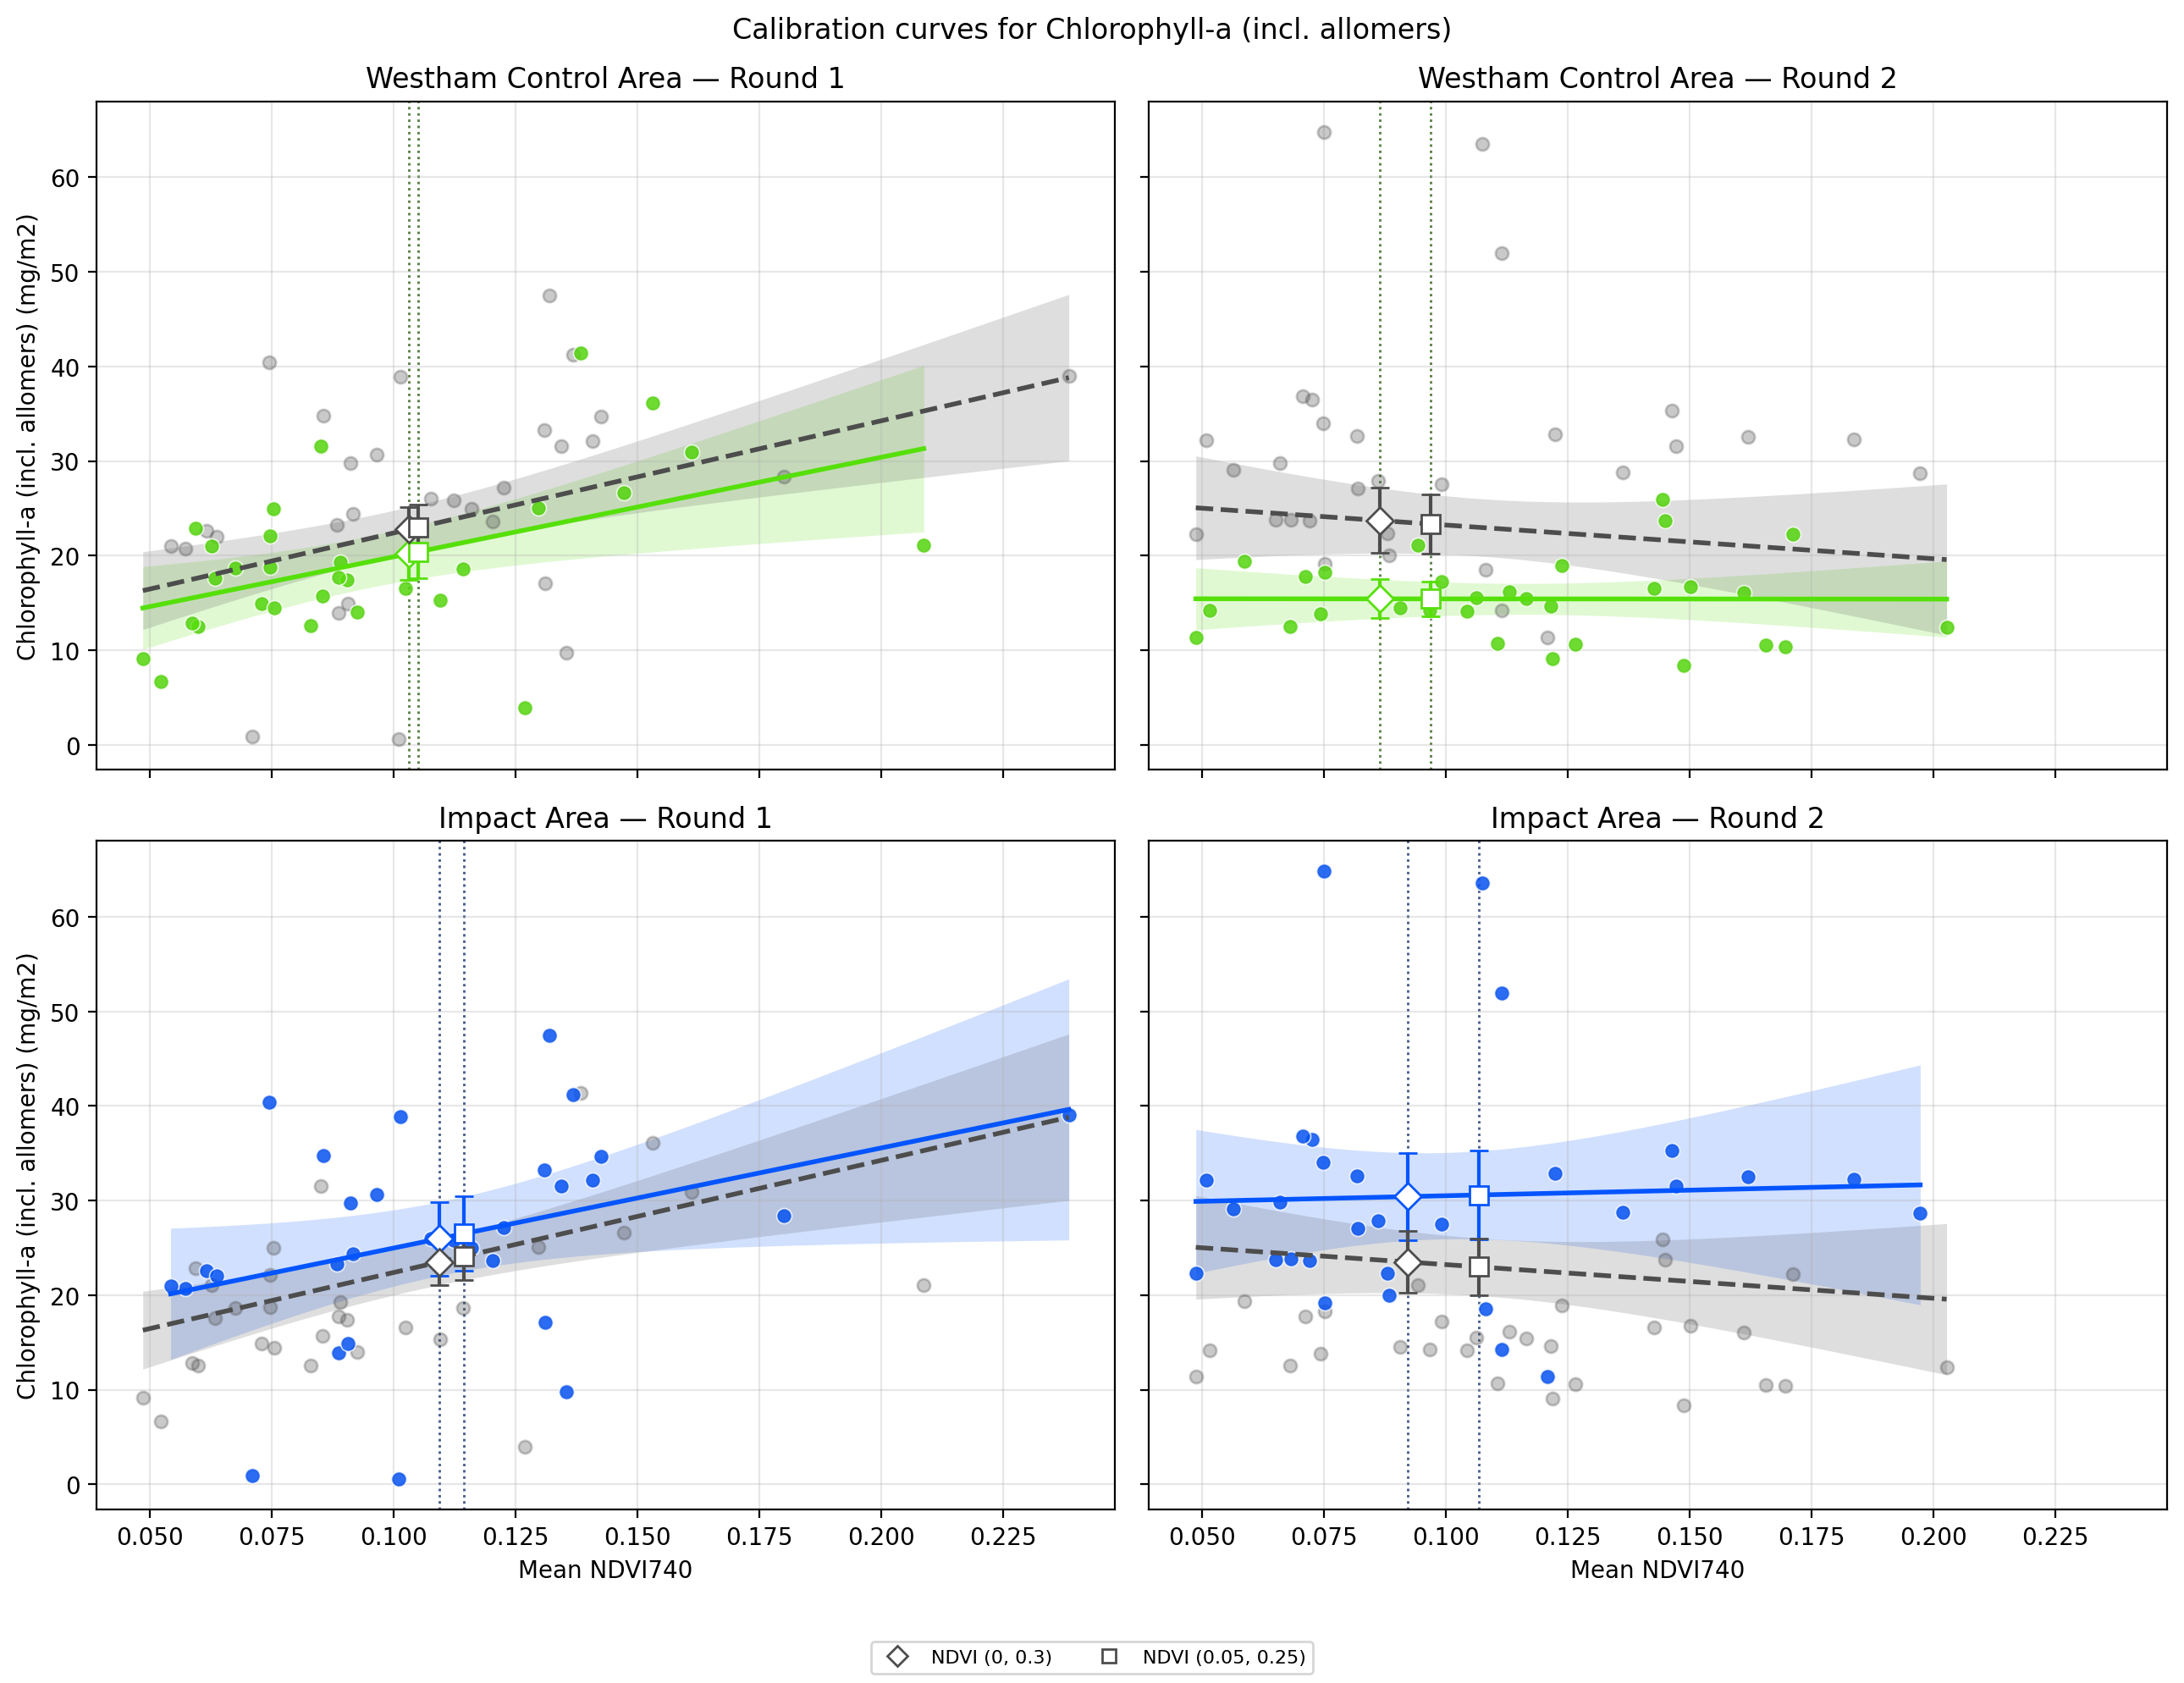

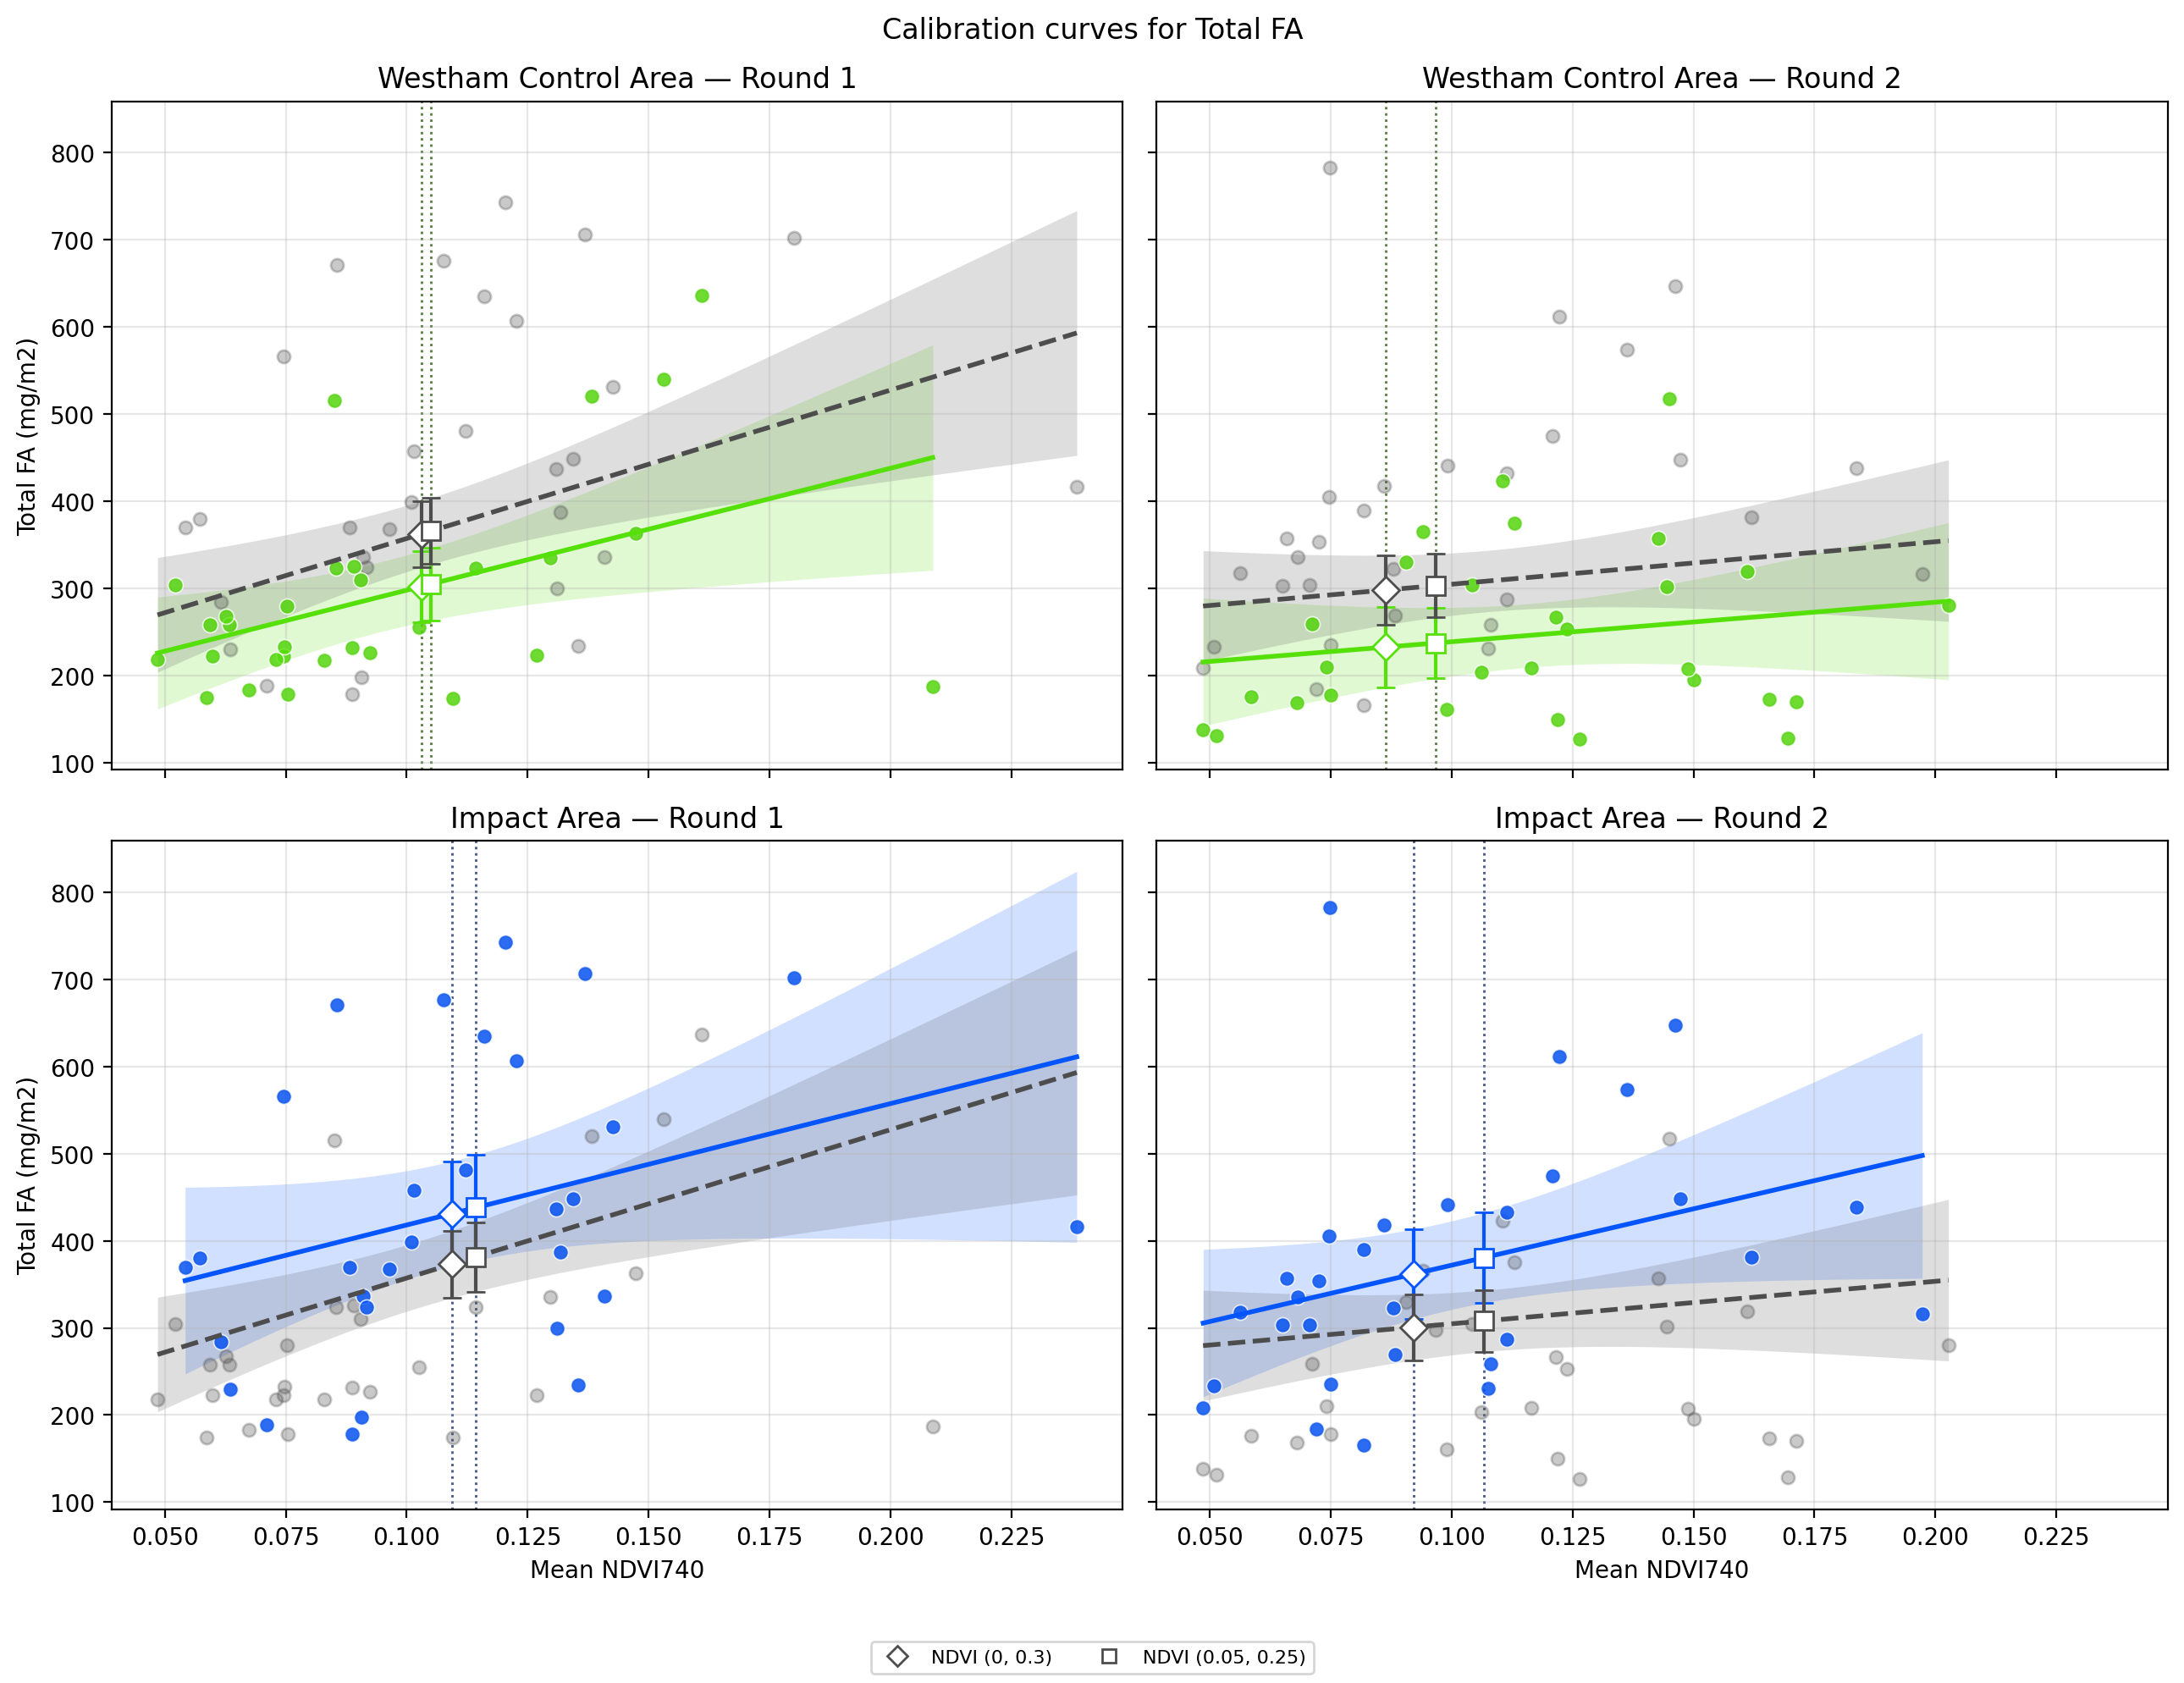

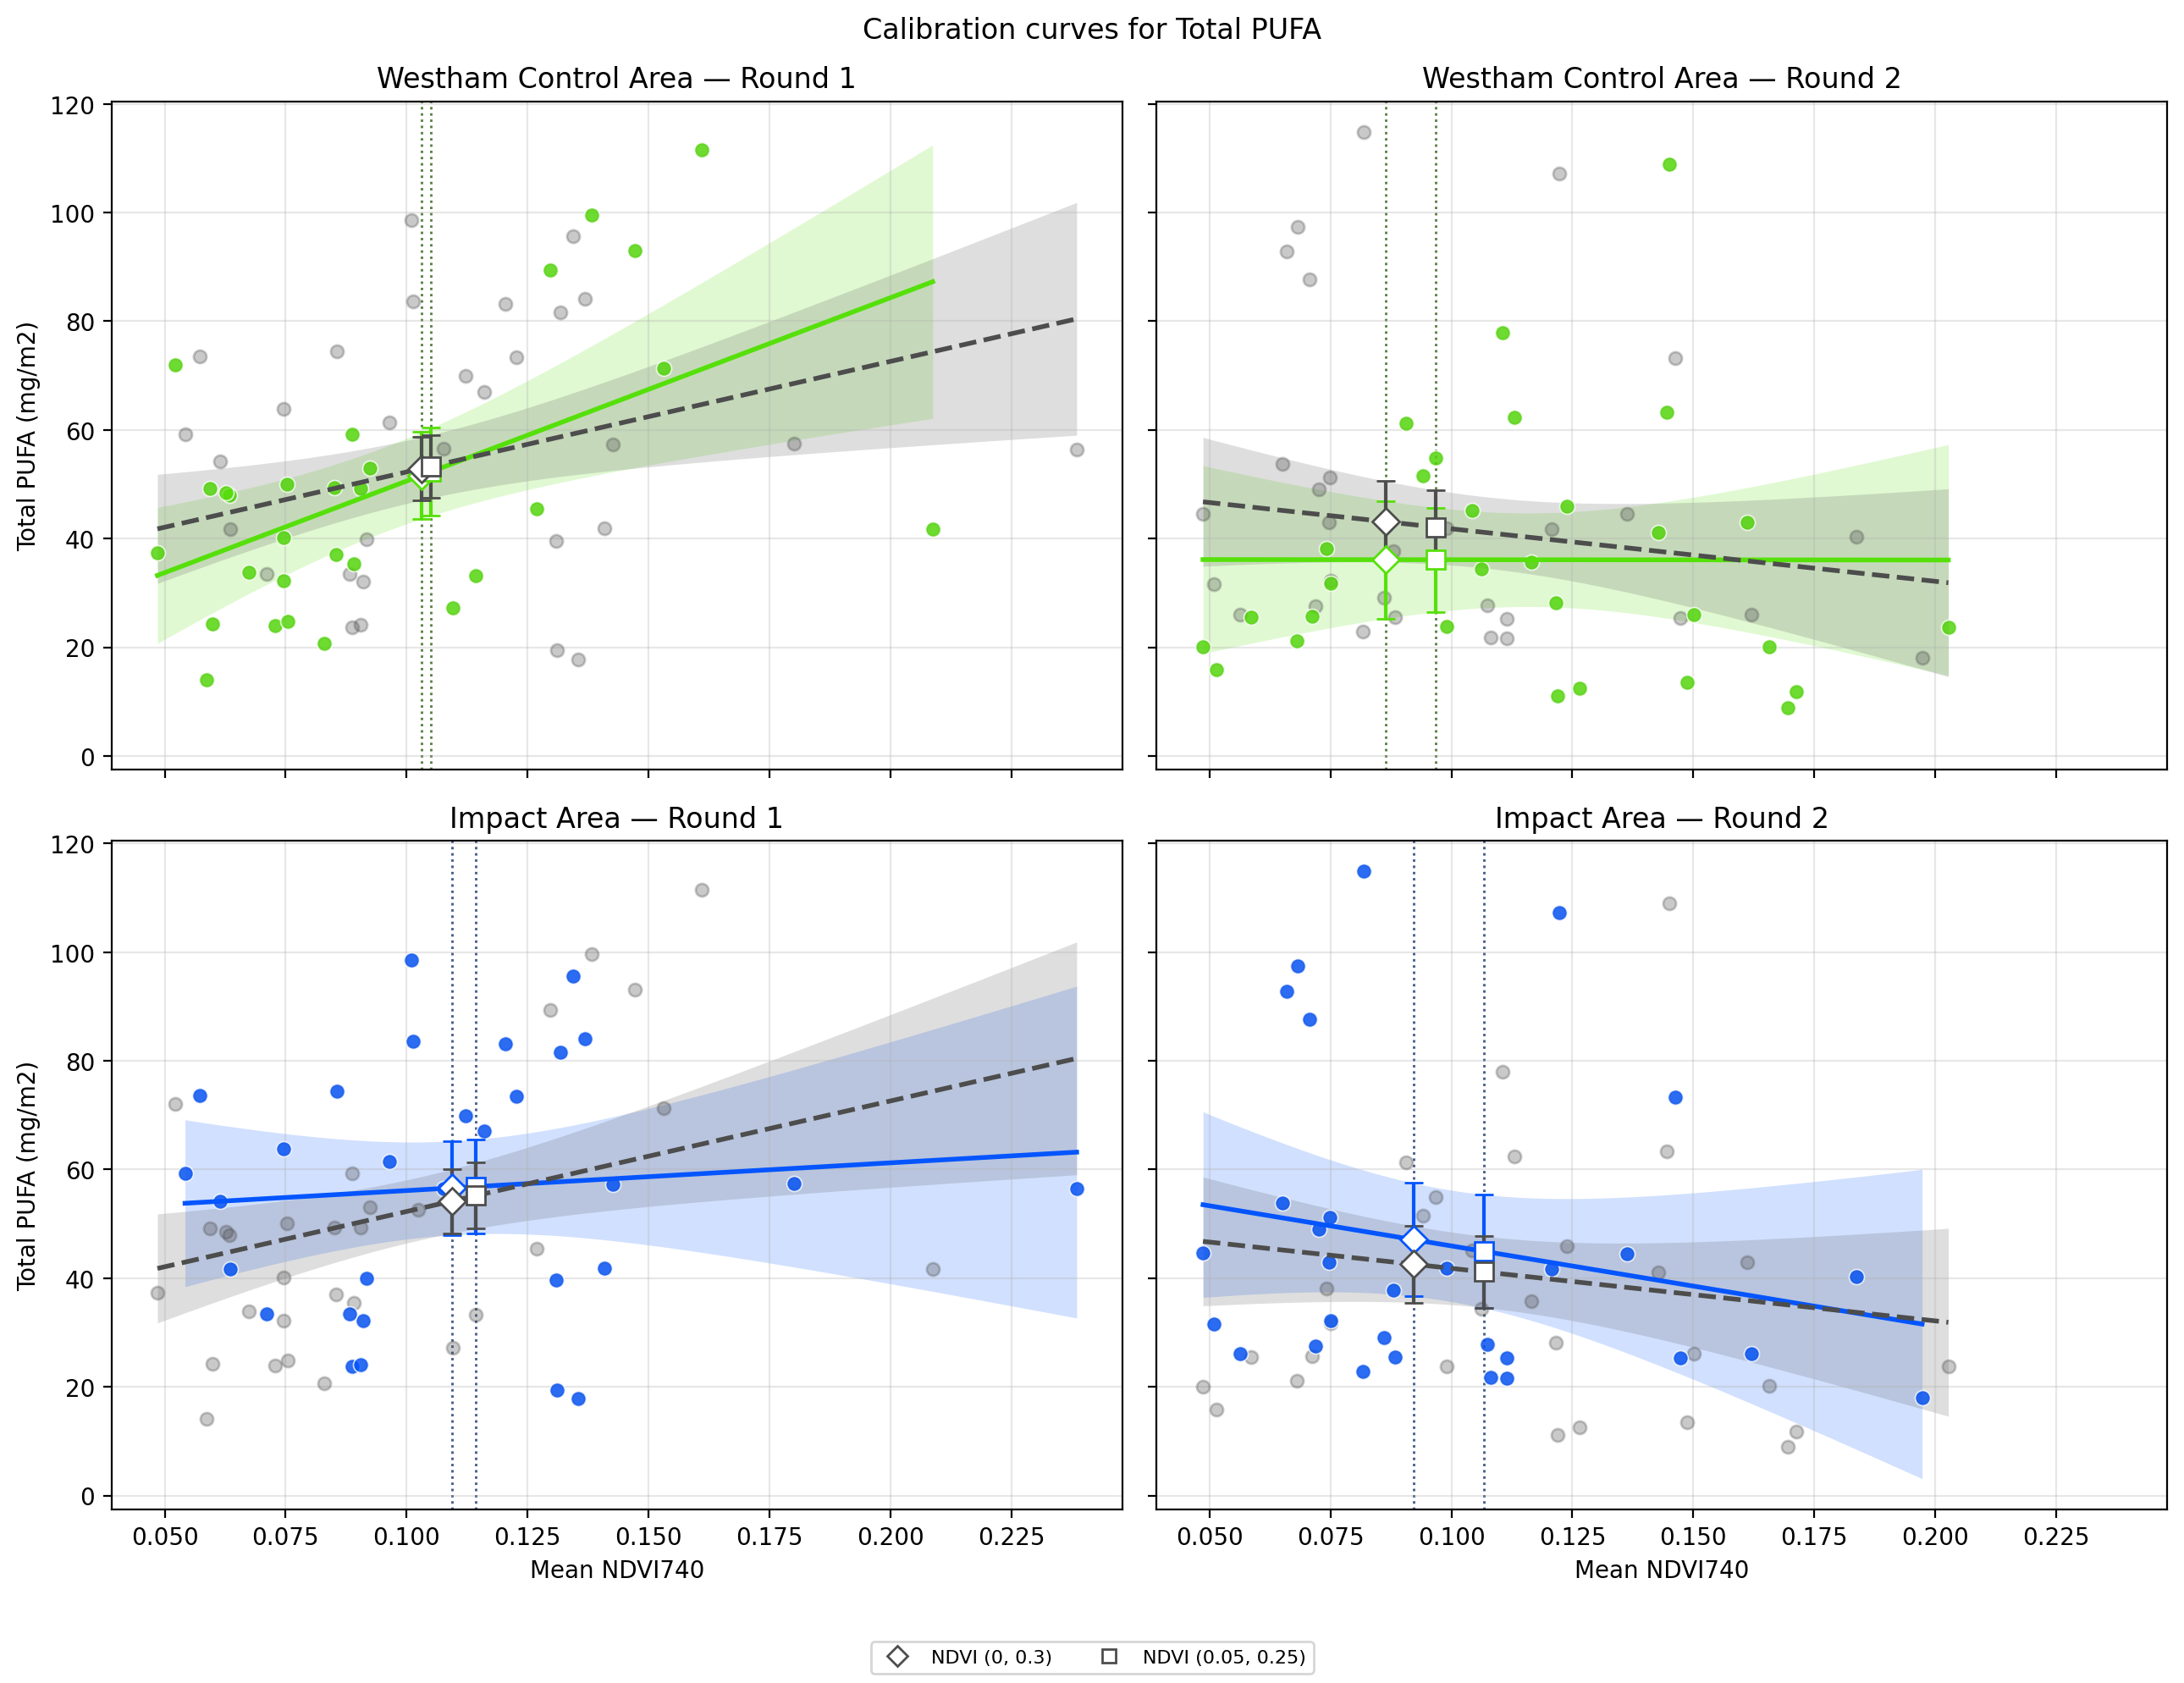

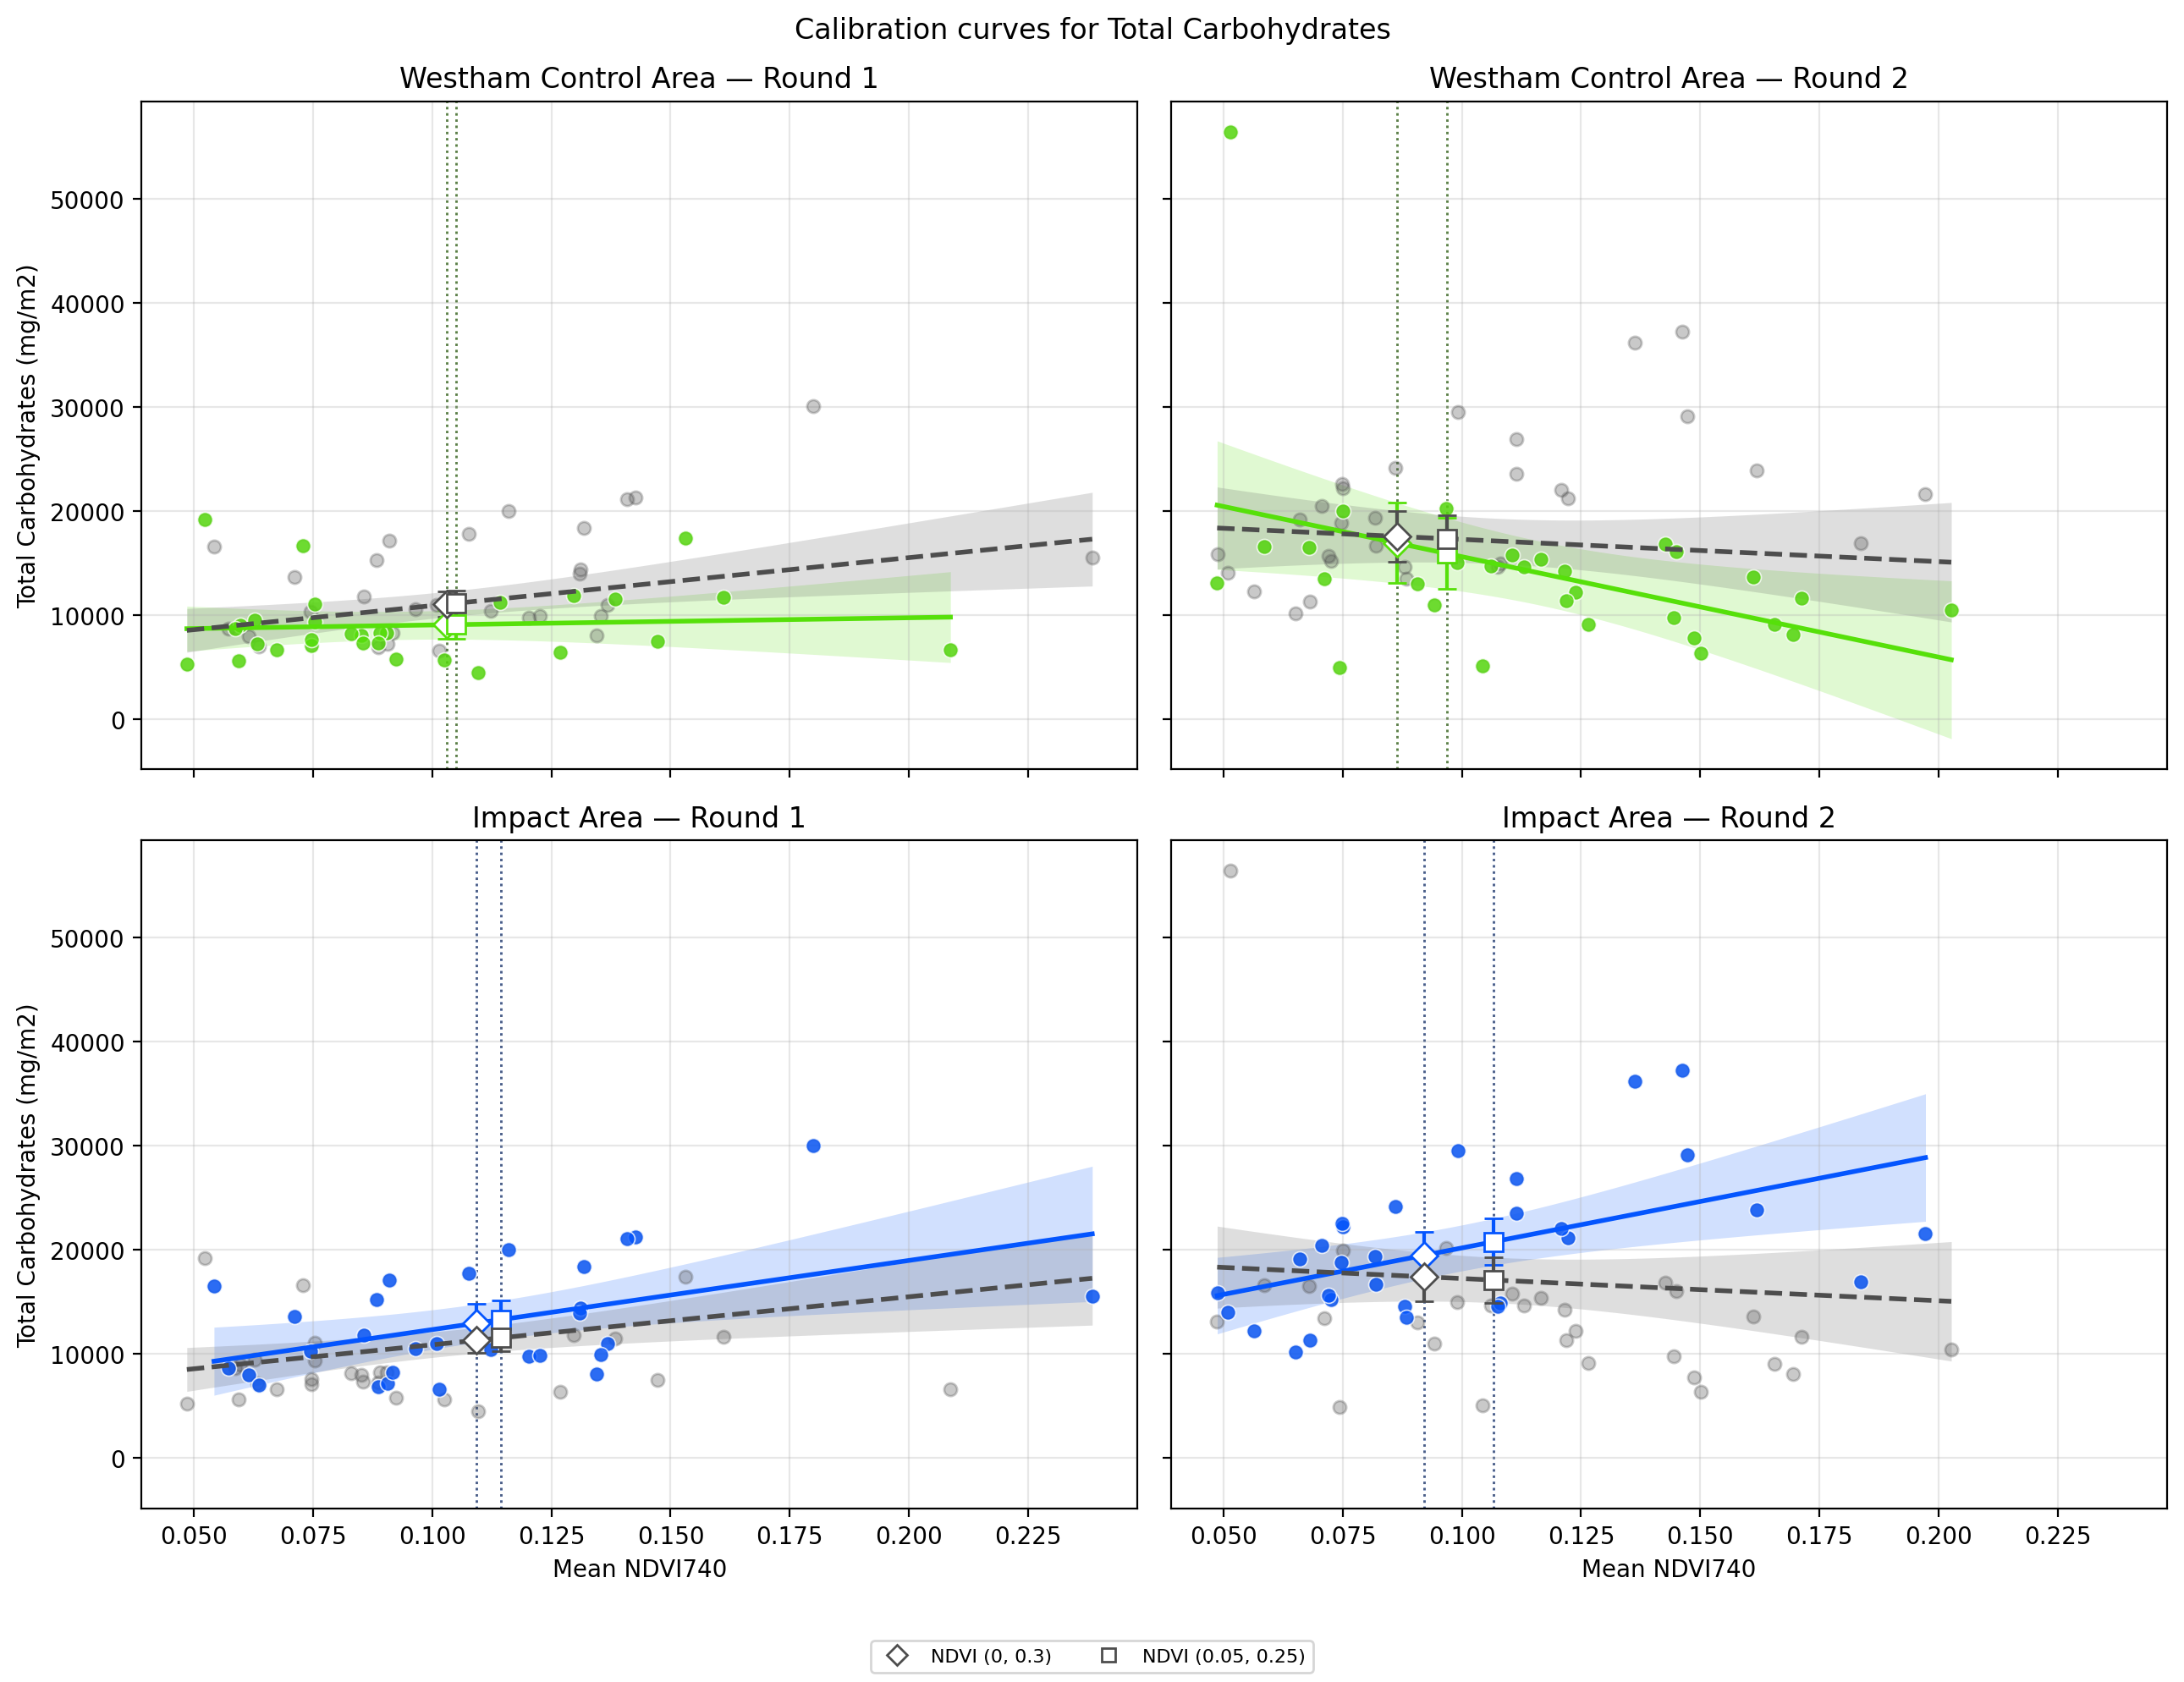

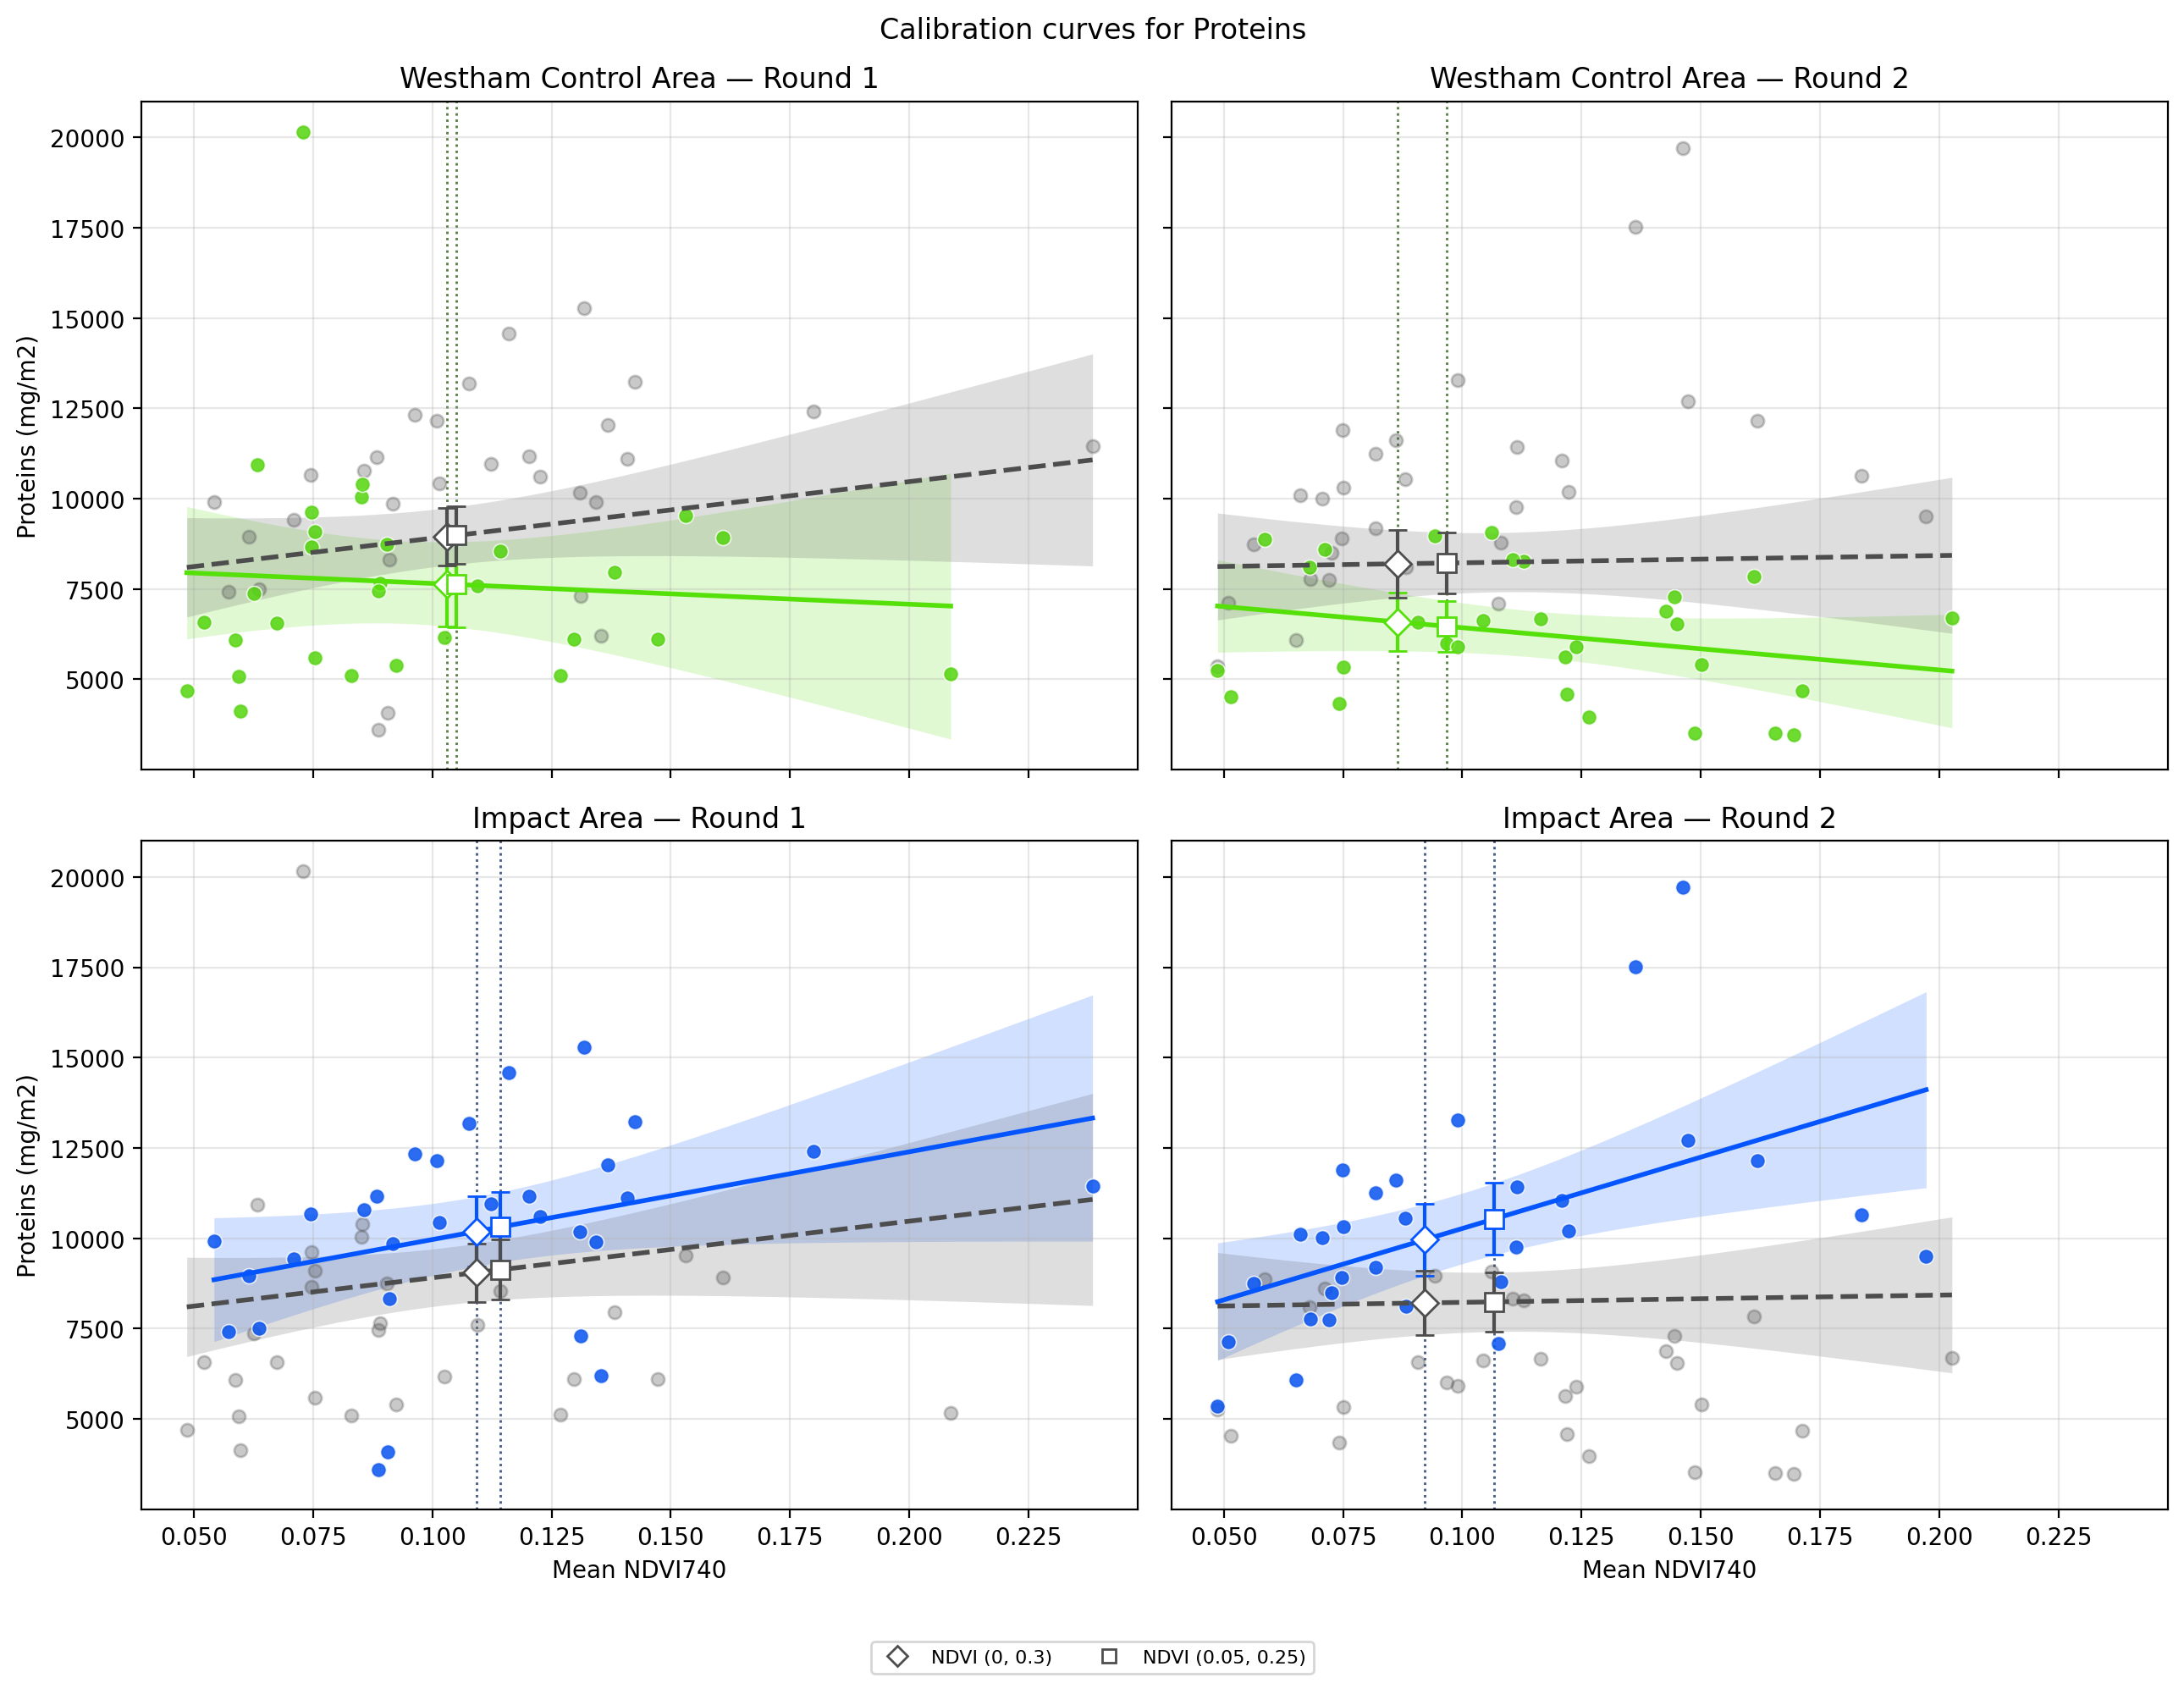

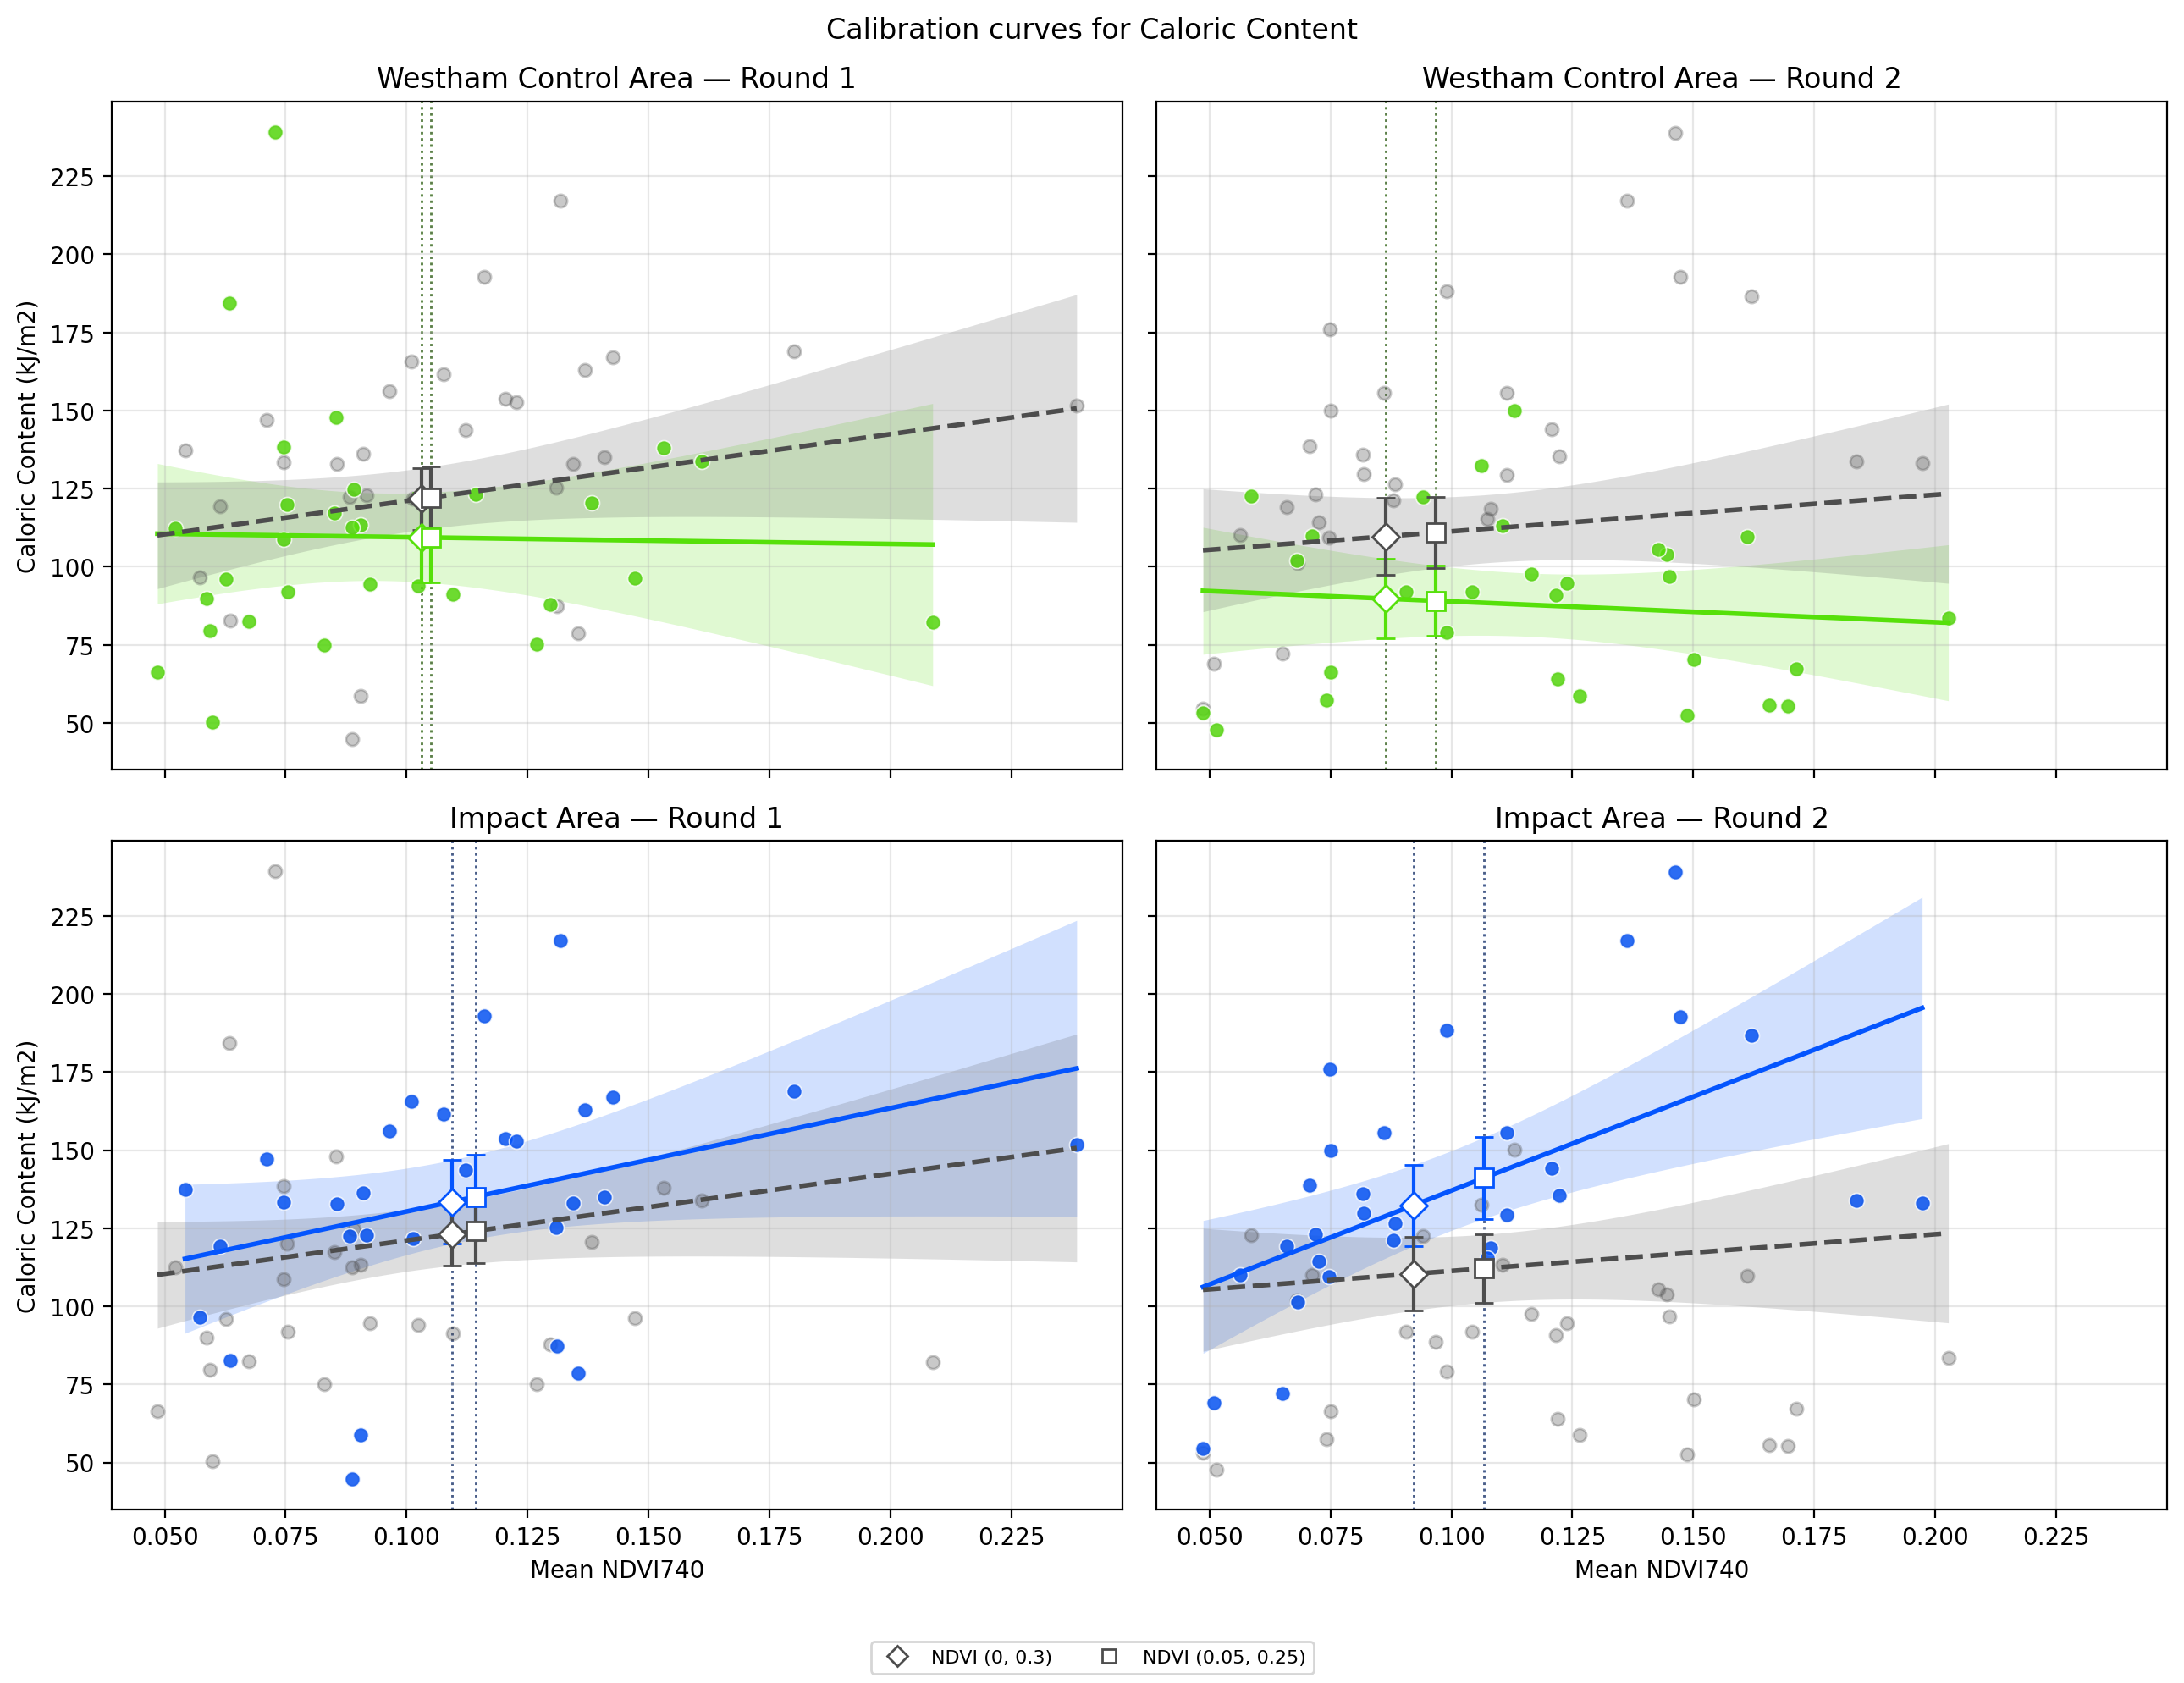

In [46]:
from matplotlib.lines import Line2D

# DLS: filled markers, dotted drop line. NoDLS: hollow markers, dash-dot drop line.
DLS_STYLES = {
    "DLS": {"filled": False, "vline": ":"},
    "NoDLS": {"filled": True, "vline": "-."},
}
NDVI_RANGE_MARKERS = ["D", "s", "^", "v"]


def plot_calibration_cases(variable, *, variable_label=None, variable_unit=None, figsize=(13, 10)):
    """One panel per site-round: calibration fit(s) with mapped-NDVI predictions for PLOT_DLS_MODES."""
    df_cal = df_calibration[variable]
    predictions = df_predictions[
        (df_predictions["variable"] == variable)
        & df_predictions["dls_mode"].isin(PLOT_DLS_MODES)
    ]
    fig, axes = plt.subplots(
        len(PLOT_SITE_ORDER), len(ROUNDS), figsize=figsize, sharex=True, sharey=True, squeeze=False
    )
    pooled_color = "0.3"
    ndvi_ranges = list(dict.fromkeys(predictions["ndvi_range"]))
    scopes = ["site-round"] + (["round"] if INCLUDE_ROUND_CALIBRATION else [])

    for row, site in enumerate(PLOT_SITE_ORDER):
        site_color = SITE_COLORS[site]
        for col, rnd in enumerate(ROUNDS):
            ax = axes[row, col]
            round_data = df_cal[df_cal["round"] == rnd]
            site_data = round_data[round_data["site"] == site]
            if INCLUDE_ROUND_CALIBRATION:
                ax.scatter(
                    round_data[CAL_X], round_data[variable], s=30, color=pooled_color, alpha=0.3,
                    label="Round, all sites", zorder=2,
                )
            ax.scatter(
                site_data[CAL_X], site_data[variable], s=42, color=site_color, alpha=0.8,
                edgecolor="white", linewidth=0.6,
                label=f"{SITE_LABELS[site]}, round {rnd}", zorder=3,
            )

            panel_preds = predictions[(predictions["site"] == site) & (predictions["round"] == rnd)]
            for scope in scopes:
                color, linestyle, fit_key = (
                    (site_color, "-", (variable, "site-round", site, rnd))
                    if scope == "site-round"
                    else (pooled_color, "--", (variable, "round", None, rnd))
                )
                fit = calibration_fits[fit_key]
                if fit is None:
                    continue
                scope_preds = panel_preds[panel_preds["calibration"] == scope]
                x_low = min([fit["x_min"], *scope_preds["mean_ndvi"]])
                x_high = max([fit["x_max"], *scope_preds["mean_ndvi"]])
                x_grid = np.linspace(x_low, x_high, 200)
                y_hat, y_lo, y_hi = predict_mean_with_ci(fit, x_grid)
                ax.fill_between(x_grid, y_lo, y_hi, color=color, alpha=0.18, linewidth=0, zorder=1)
                ax.plot(
                    x_grid, y_hat, color=color, linestyle=linestyle, linewidth=2, zorder=4,
                    label=f"{scope} fit (n={fit['n']}, R²={fit['r_squared']:.2f})",
                )

                for _, pred in scope_preds.iterrows():
                    style = DLS_STYLES[pred["dls_mode"]]
                    ax.errorbar(
                        pred["mean_ndvi"], pred["mean_mg_m2"],
                        yerr=[
                            [pred["mean_mg_m2"] - pred["mean_mg_m2_ci_low"]],
                            [pred["mean_mg_m2_ci_high"] - pred["mean_mg_m2"]],
                        ],
                        fmt=NDVI_RANGE_MARKERS[ndvi_ranges.index(pred["ndvi_range"]) % len(NDVI_RANGE_MARKERS)],
                        color=color, mfc=color if style["filled"] else "white",
                        markersize=8, capsize=4, linewidth=1.5, zorder=6,
                    )
                    ax.axvline(
                        pred["mean_ndvi"], color=color, linestyle=style["vline"],
                        linewidth=1, alpha=0.7, zorder=0,
                    )

            ax.set_title(f"{SITE_LABELS[site]} \u2014 Round {rnd}")
            ax.grid(alpha=0.3)
            # ax.legend(fontsize=7, loc="upper left")
            if row == len(PLOT_SITE_ORDER) - 1:
                ax.set_xlabel("Mean NDVI740")
            if col == 0:
                ax.set_ylabel(f"{variable_label or variable} ({variable_unit})" if variable_unit else (variable_label or variable))

    # Figure-level key; DLS modes are only listed when more than one is shown.
    key_handles = []
    if len(PLOT_DLS_MODES) > 1:
        key_handles += [
            Line2D([0], [0], marker="o", color="0.3", mfc="0.3" if style["filled"] else "white",
                   linestyle=style["vline"], label=f"{mode} prediction")
            for mode, style in DLS_STYLES.items()
            if mode in PLOT_DLS_MODES
        ]
    key_handles += [
        Line2D([0], [0], marker=NDVI_RANGE_MARKERS[i % len(NDVI_RANGE_MARKERS)], color="0.3",
               mfc="white", linestyle="None", label=f"NDVI {rng}")
        for i, rng in enumerate(ndvi_ranges)
    ]
    fig.legend(handles=key_handles, loc="lower center", ncol=len(key_handles), fontsize=8)
    fig.suptitle(f"Calibration curves for {variable_label or variable}")
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    return fig, axes


for _variable in variables_to_predict:
    plot_calibration_cases(
        _variable,
        variable_label=variables_to_predict_labels_without_unit.get(_variable),
        variable_unit=variables_to_predict_unit.get(_variable)
    )
    plt.show()


In [47]:
df_predictions_report = df_predictions.copy().set_index(
    ['variable', 'site', 'round', 'dls_mode', 'ndvi_range', 'calibration']
)
df_predictions_report = df_predictions_report.filter(
    [
        "biofilm_area_ha",
        "mean_ndvi",
        "mean_mg_m2",
        "mean_mg_m2_ci_low",
        "mean_mg_m2_ci_high",
        "total_kg",
        "total_kg_ci_low",
        "total_kg_ci_high",
    ]
)
# Min of low values and max of high values per site, round and DLS mode, regardless of other parameters
df_predictions_report_summary = df_predictions_report.groupby(
    ["variable", "site", "round", "dls_mode"]
)["total_kg_ci_low"].min().to_frame()
df_predictions_report_summary["total_kg_ci_high"] = df_predictions_report.groupby(
    ["variable", "site", "round", "dls_mode"]
)["total_kg_ci_high"].max()
df_predictions_report_summary

total_kg_ci_low  \
variable                site      round dls_mode                    
Caloric (kJ/m2)         brunswick 1     DLS          7.745947e+08   
                                        NoDLS        7.443019e+08   
                                  2     DLS          5.806968e+08   
                                        NoDLS        5.636242e+08   
                        westham   1     DLS          6.301703e+08   
                                        NoDLS        6.193288e+08   
                                  2     DLS          4.435083e+08   
                                        NoDLS        4.258409e+08   
Chla + allomers (mg/m2) brunswick 1     DLS          1.470146e+02   
                                        NoDLS        1.393540e+02   
                                  2     DLS          1.144533e+02   
                                        NoDLS        1.114120e+02   
                        westham   1     DLS          1.167329e+02   
                                        NoDLS        1.139015e+02   
                                  2     DLS          7.749394e+01   
                                        NoDLS        7.438668e+01   
Proteins (mg/m2)        brunswick 1     DLS          5.647375e+04   
                                        NoDLS        5.427587e+04   
                                  2     DLS          4.256448e+04   
                                        NoDLS        4.134985e+04   
                        westham   1     DLS          4.279595e+04   
                                        NoDLS        4.210192e+04   
                                  2     DLS          3.280069e+04   
                                        NoDLS        3.151068e+04   
Total Carbs (mg/m2)     brunswick 1     DLS          6.983986e+04   
                                        NoDLS        6.647612e+04   
                                  2     DLS          8.559562e+04   
                                        NoDLS        8.329220e+04   
                        westham   1     DLS          5.084049e+04   
                                        NoDLS        4.991117e+04   
                                  2     DLS          7.102163e+04   
                                        NoDLS        6.833471e+04   
Total FA (mg/m2)        brunswick 1     DLS          2.326379e+03   
                                        NoDLS        2.209630e+03   
                                  2     DLS          1.565005e+03   
                                        NoDLS        1.518013e+03   
                        westham   1     DLS          1.749864e+03   
                                        NoDLS        1.708721e+03   
                                  2     DLS          1.119902e+03   
                                        NoDLS        1.073749e+03   
Total PUFA (mg/m2)      brunswick 1     DLS          3.276906e+02   
                                        NoDLS        3.155578e+02   
                                  2     DLS          1.978862e+02   
                                        NoDLS        1.933593e+02   
                        westham   1     DLS          2.936915e+02   
                                        NoDLS        2.860632e+02   
                                  2     DLS          1.510828e+02   
                                        NoDLS        1.448958e+02   

                                                  total_kg_ci_high  
variable                site      round dls_mode                    
Caloric (kJ/m2)         brunswick 1     DLS           1.141517e+09  
                                        NoDLS         1.124278e+09  
                                  2     DLS           1.100297e+09  
                                        NoDLS         1.086386e+09  
                        westham   1     DLS           1.038375e+09  
                                        NoDLS         1.034862e+09  
                                  2     DLS    

In [48]:
summary = df_predictions_report_summary.xs("DLS", level="dls_mode").copy()

is_mass = (
    summary.index.get_level_values("variable")
    .map(lambda v: "mg" in variables_to_predict_unit.get(v, ""))
    .to_numpy(dtype=bool)
)
summary.loc[is_mass] /= 1e3  # kg to tonnes; kJ rows are left as they are


def format_sig(value, sig=3):
    """Fixed-point with `sig` significant figures, no scientific notation."""
    if not np.isfinite(value):
        return "n/a"
    digits = max(0, sig - 1 - int(np.floor(np.log10(abs(value))))) if value else 0
    return f"{value:,.{digits}f}"


summary_range = (
    pd.Series(
        [
            f"{format_sig(low)} \u2014 {format_sig(high)}"
            for low, high in zip(summary["total_kg_ci_low"], summary["total_kg_ci_high"])
        ],
        index=summary.index,
        name="range",
    )
    .unstack("site")[SITES]
    .rename(columns=SITE_LABELS)
)

unit_groups = {
    "Total mass (tonnes)": [
        v for v in variables_to_predict if "mg" in variables_to_predict_unit.get(v, "")
    ],
    "Total energy (kJ)": [
        v for v in variables_to_predict if "kJ" in variables_to_predict_unit.get(v, "")
    ],
}

for title, variables in unit_groups.items():
    for _round in ROUNDS:
        display(
            summary_range.xs(_round, level="round")
            .reindex(index=pd.Index(variables, name="variable"))
            .rename(index=variables_to_predict_labels_without_unit)
            .style.set_caption(f"{title}, round {_round}")
        )

site,Impact Area,Westham Control Area
variable,,
Chlorophyll-a (incl. allomers),0.147 — 0.232,0.117 — 0.198
Total FA,2.33 — 3.82,1.75 — 3.16
Total PUFA,0.328 — 0.507,0.294 — 0.470
Total Carbohydrates,69.8 — 115,50.8 — 96.5
Proteins,56.5 — 86.7,42.8 — 76.9


site,Impact Area,Westham Control Area
variable,,
Chlorophyll-a (incl. allomers),0.114 — 0.266,0.0775 — 0.215
Total FA,1.57 — 3.13,1.12 — 2.67
Total PUFA,0.198 — 0.436,0.151 — 0.400
Total Carbohydrates,85.6 — 164,71.0 — 164
Proteins,42.6 — 82.9,32.8 — 72.1


site,Impact Area,Westham Control Area
variable,,
Caloric Content,"774,594,695 — 1,141,516,637","630,170,293 — 1,038,375,215"


site,Impact Area,Westham Control Area
variable,,
Caloric Content,"580,696,773 — 1,100,297,093","443,508,279 — 964,904,880"


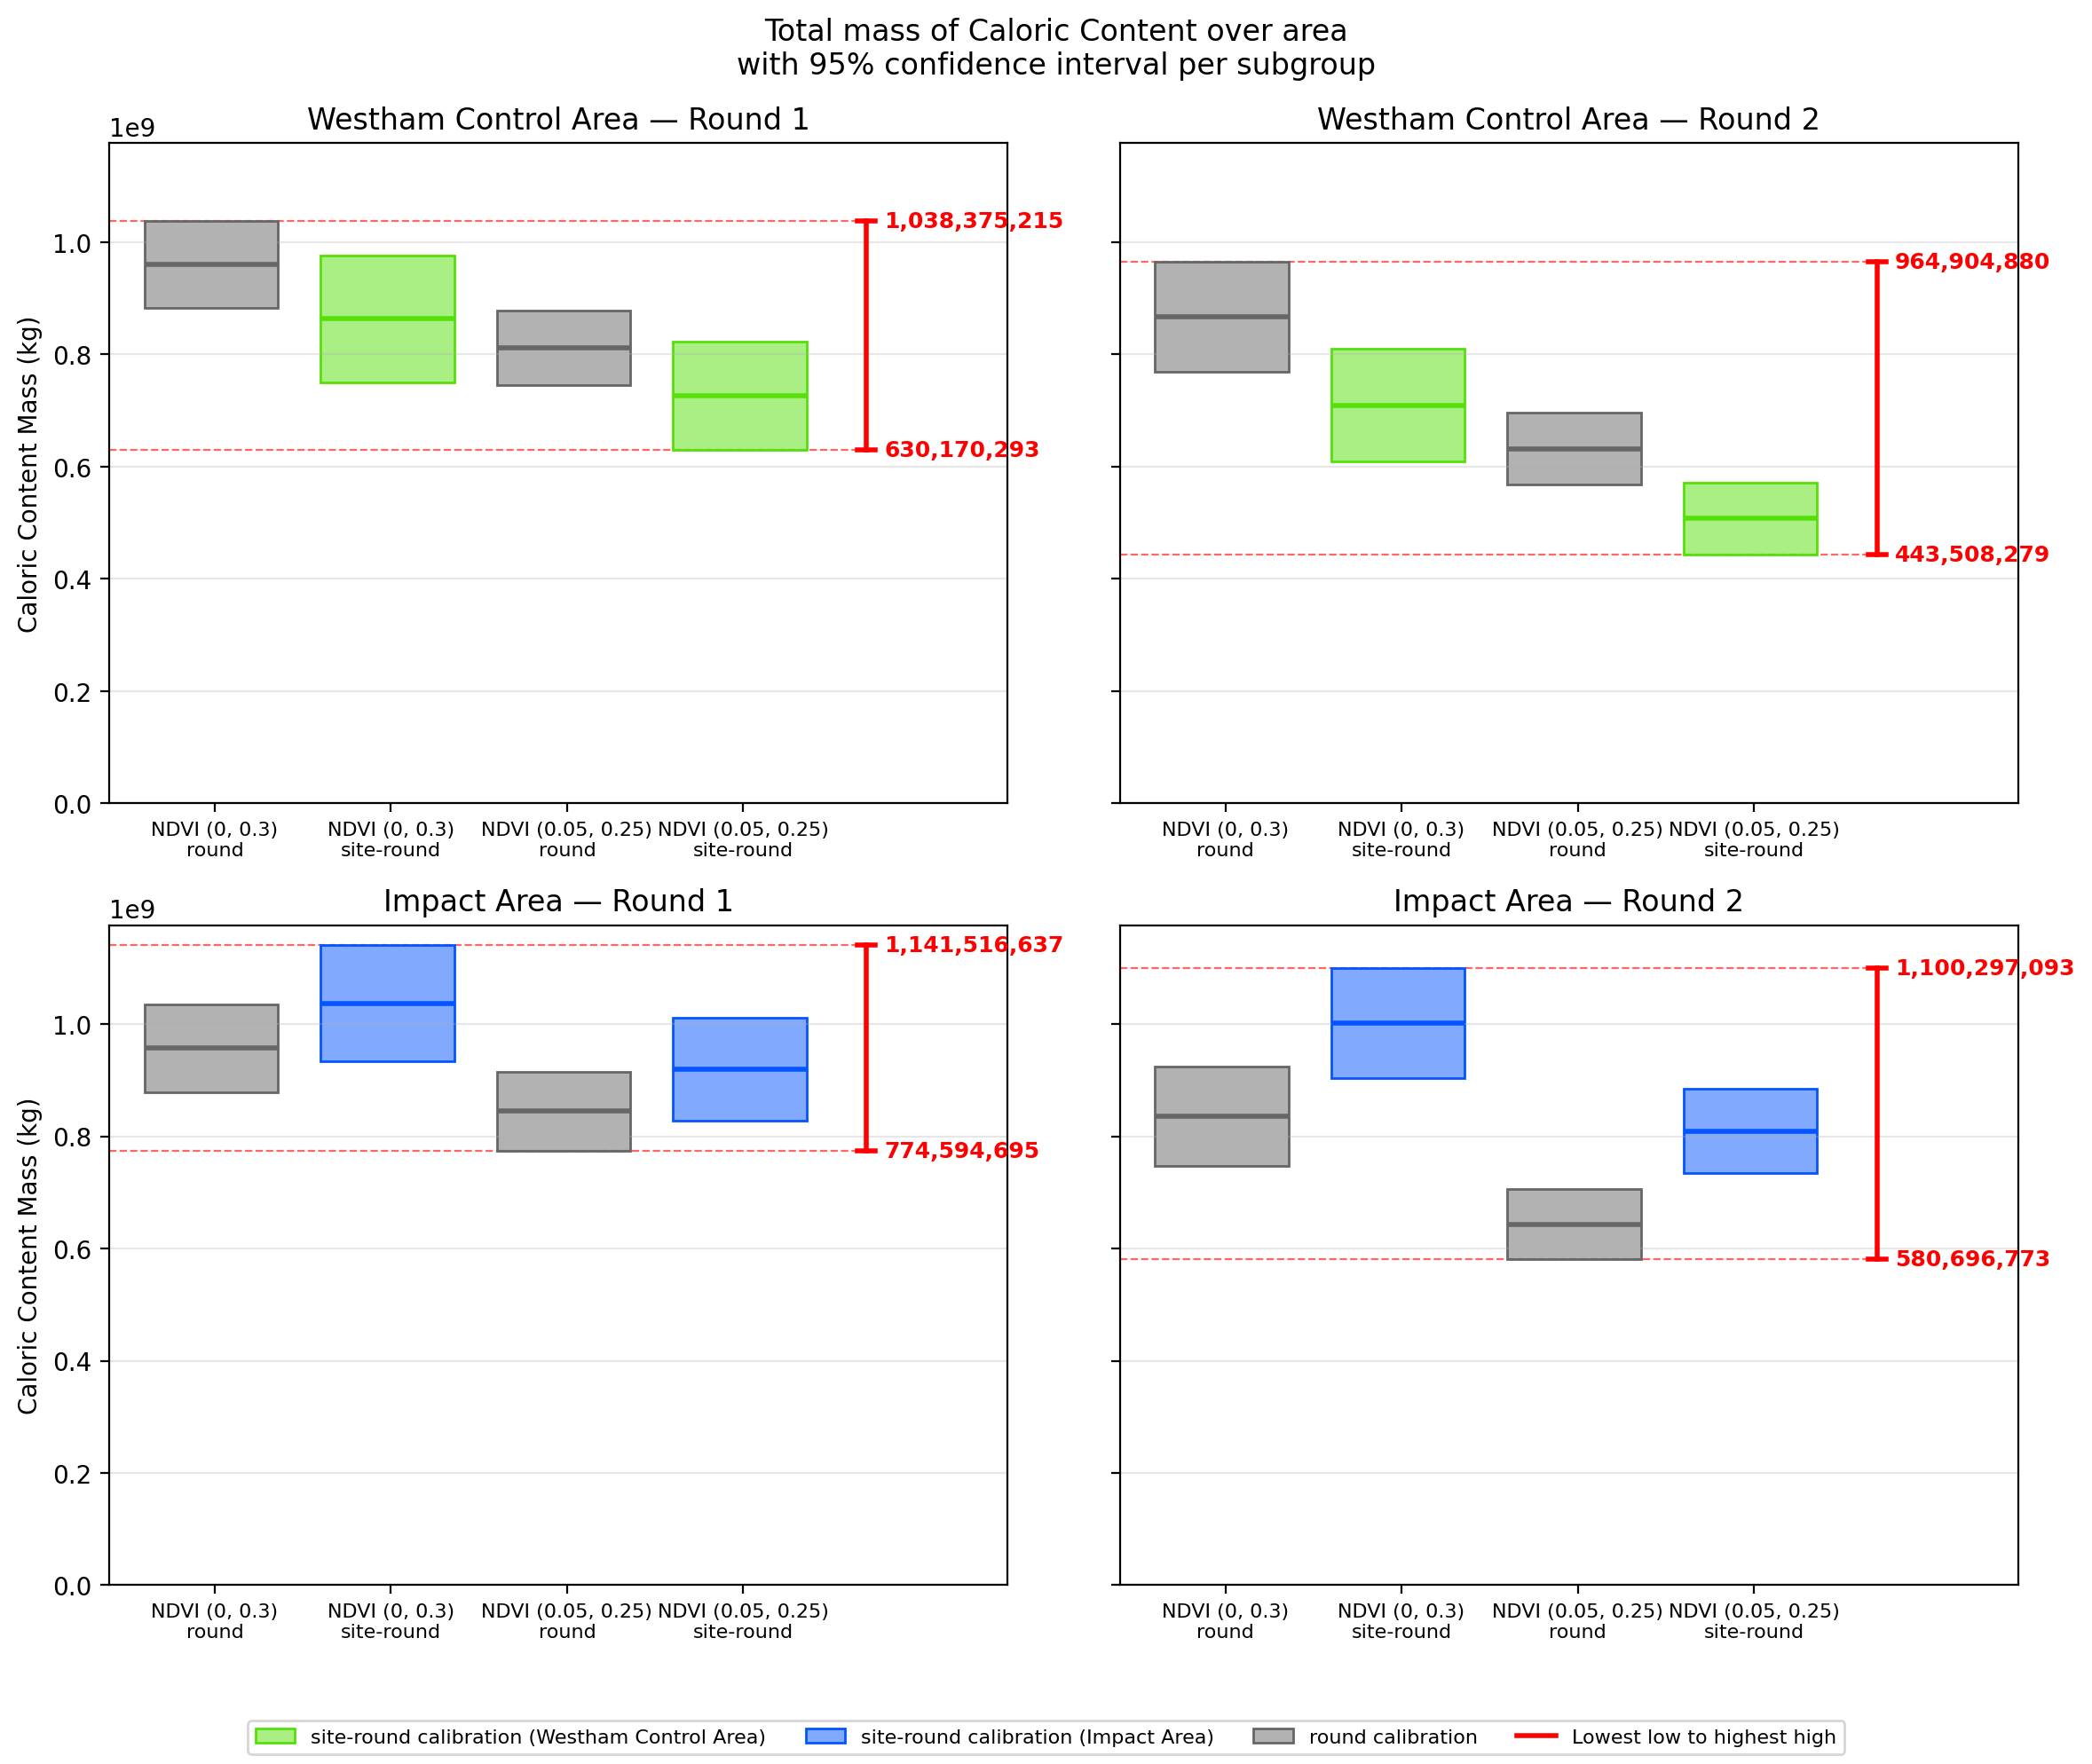

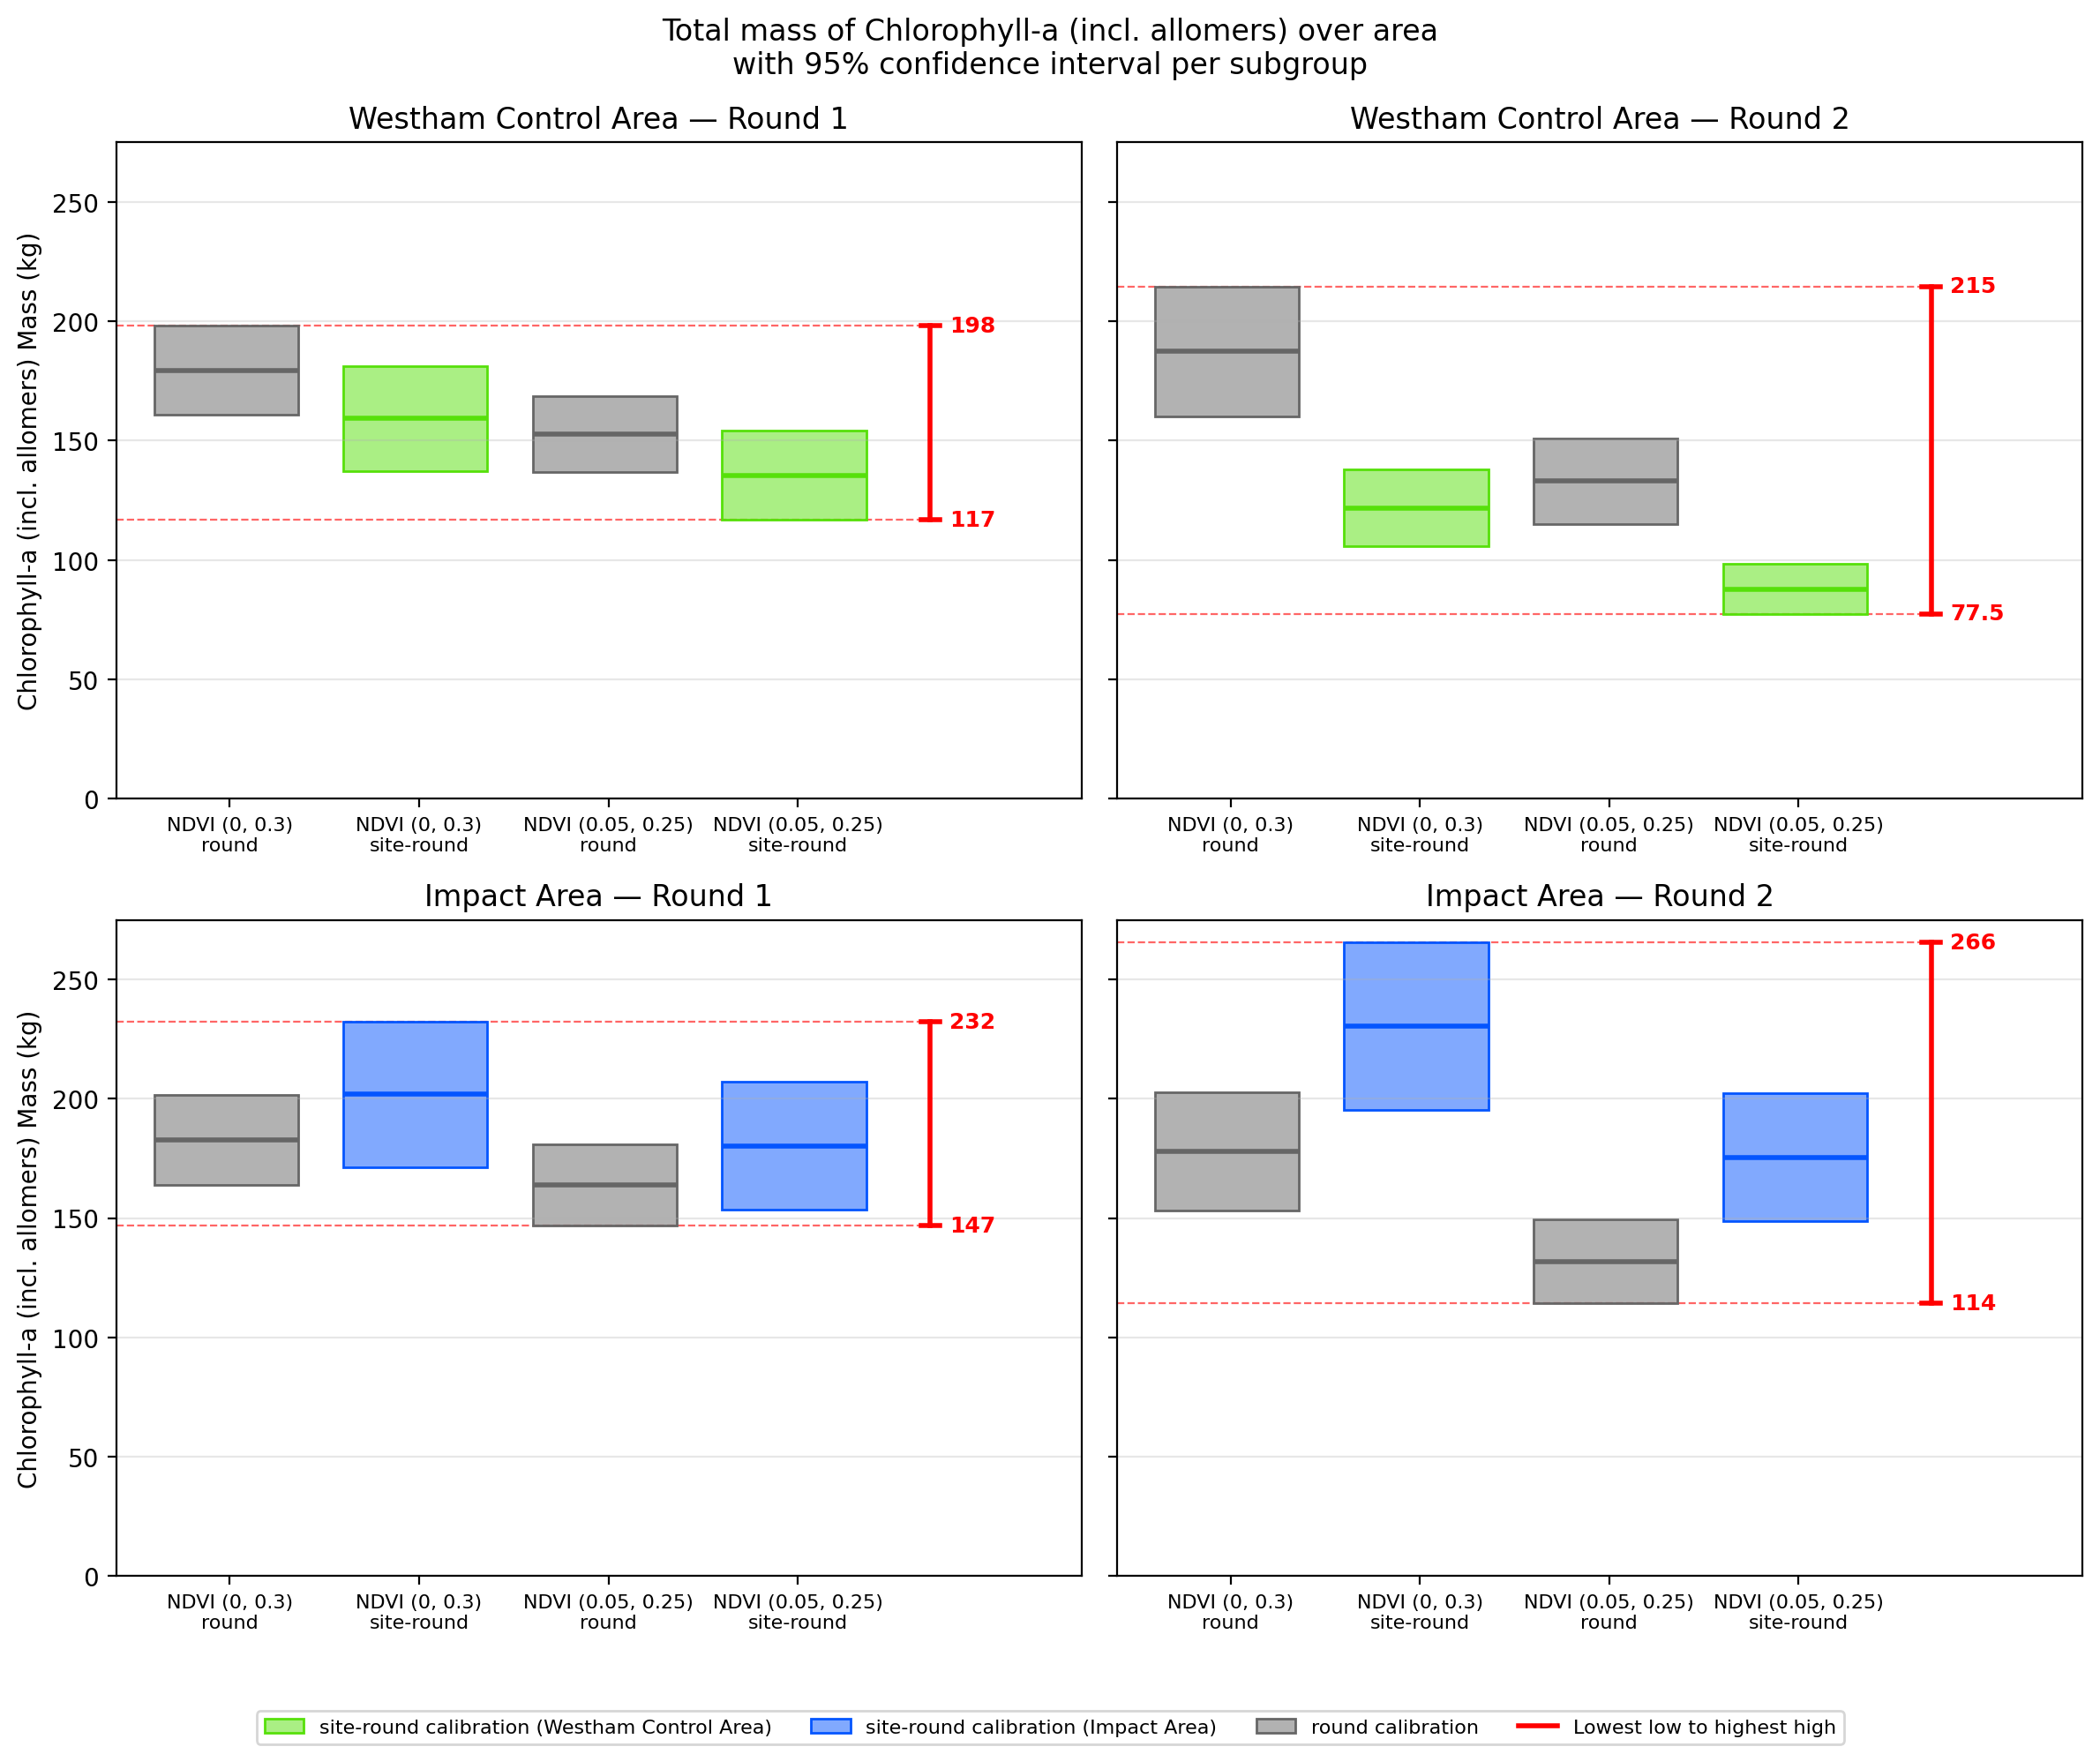

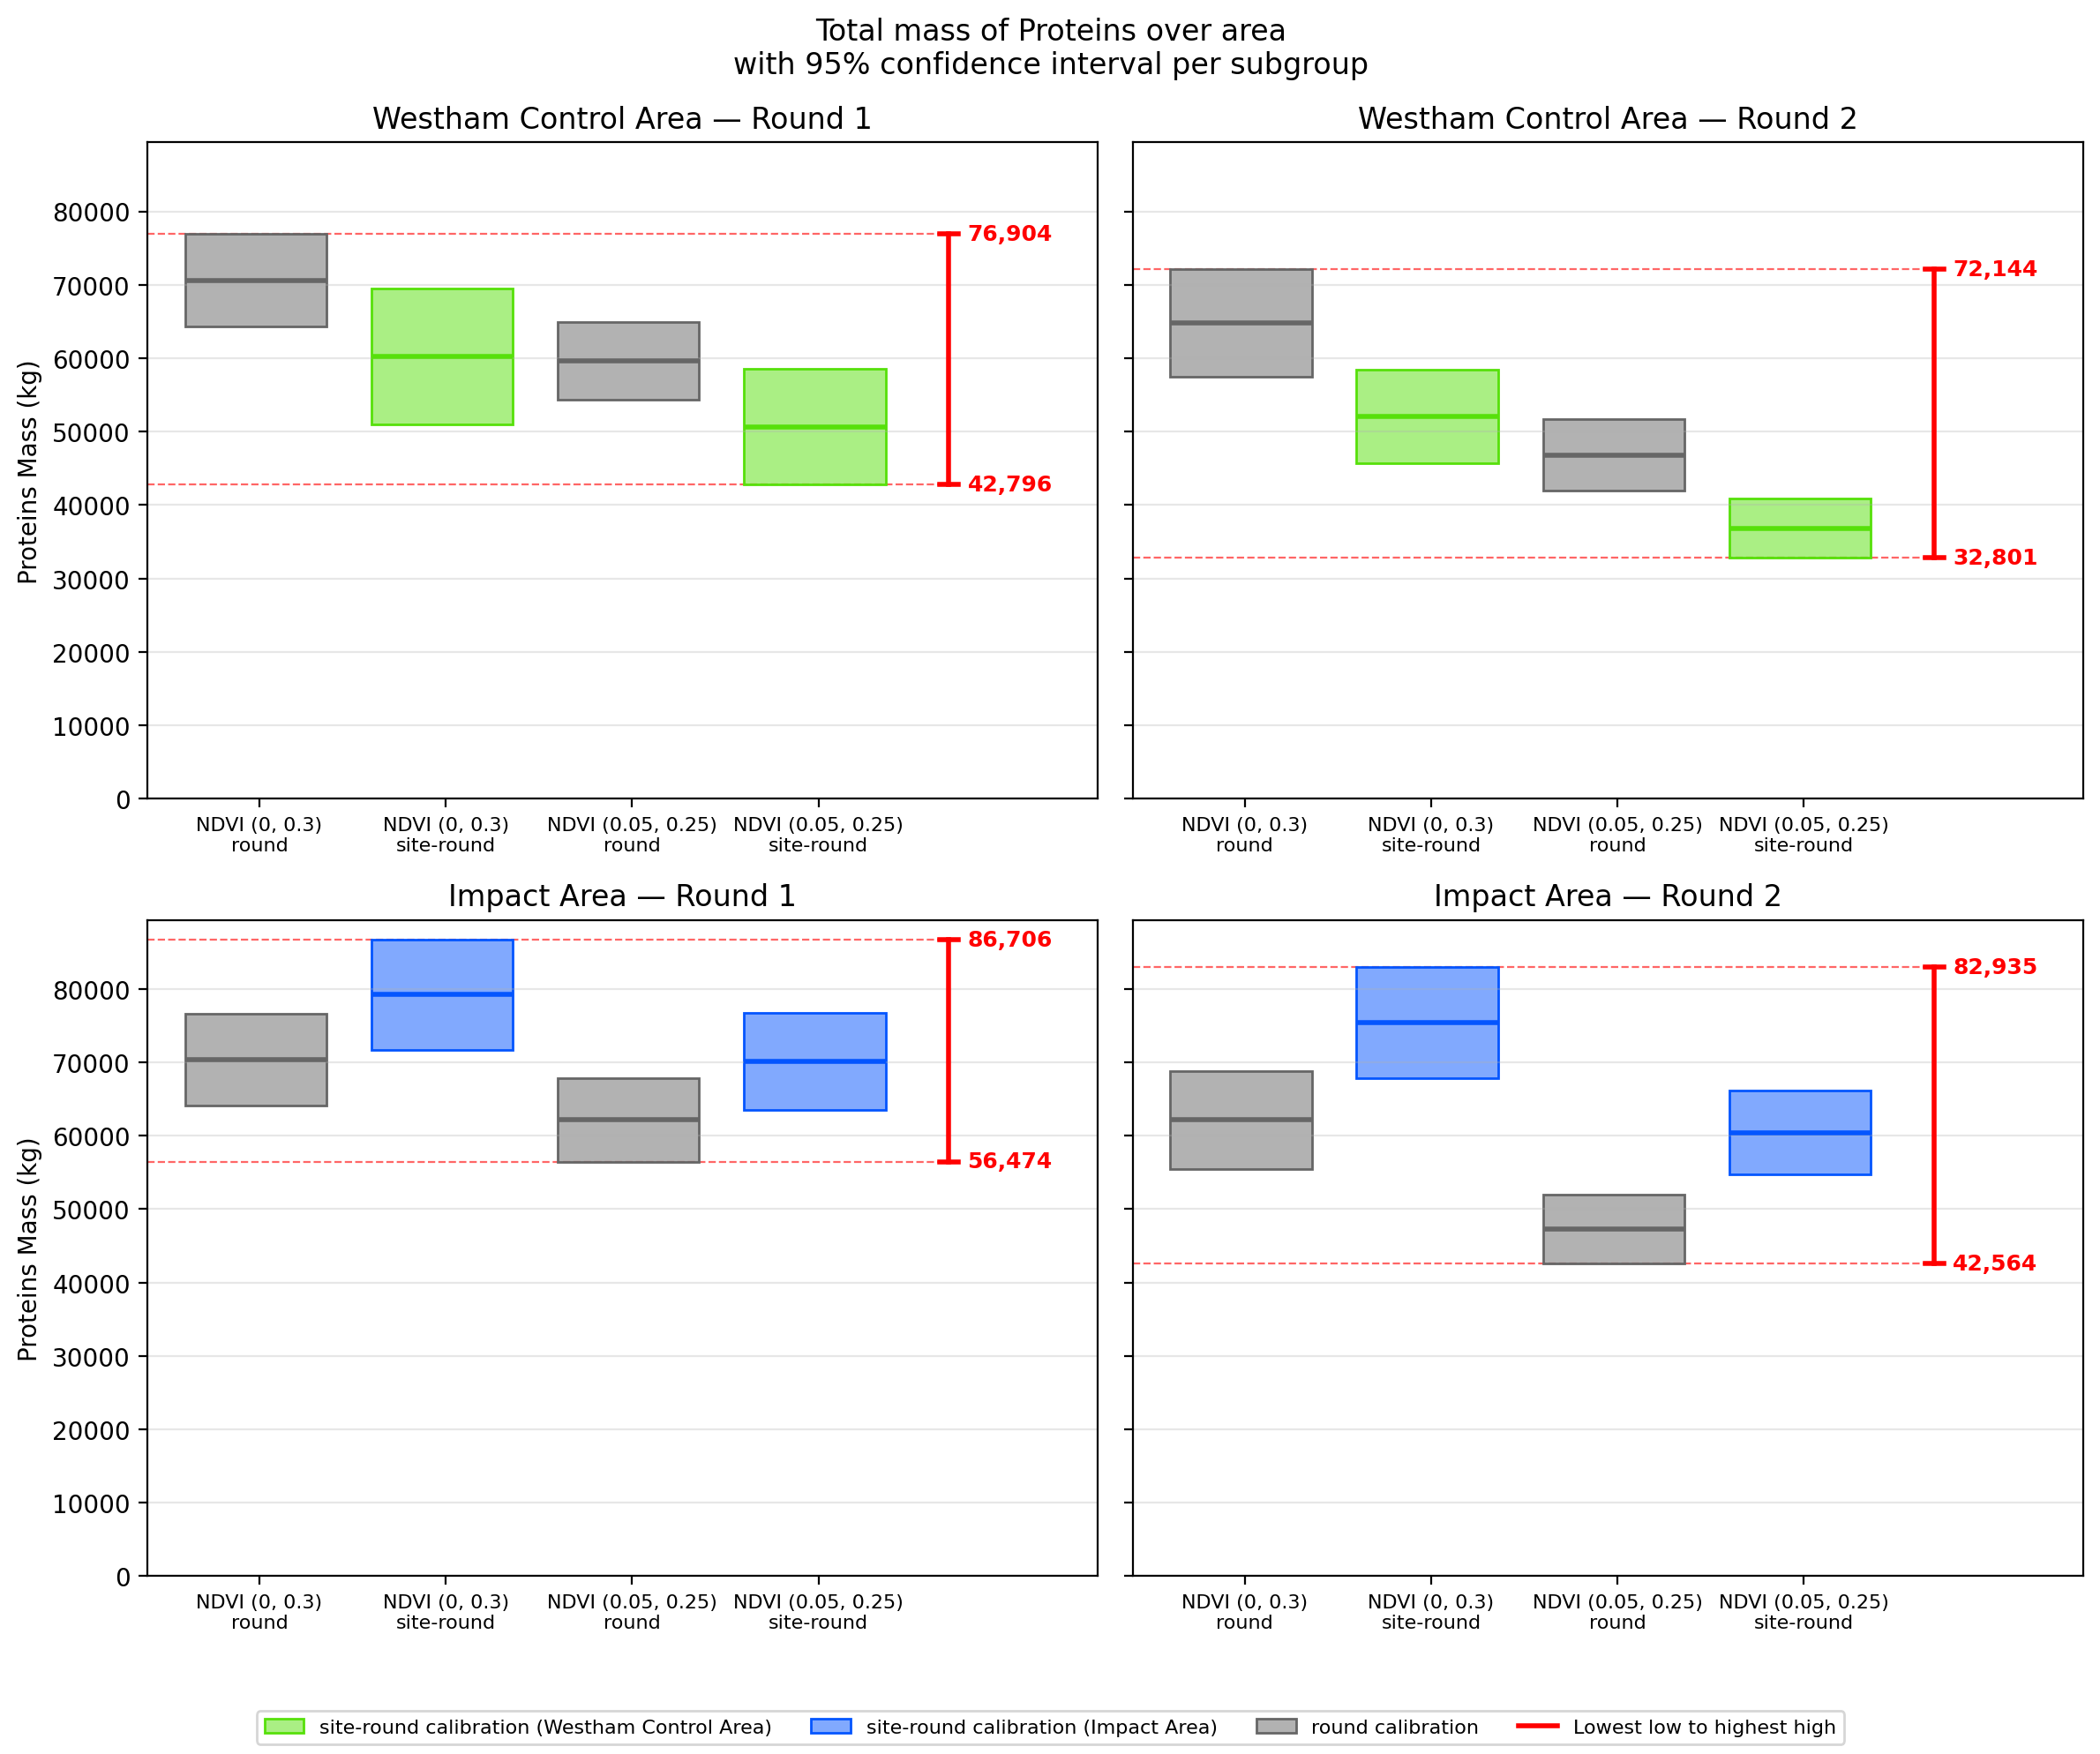

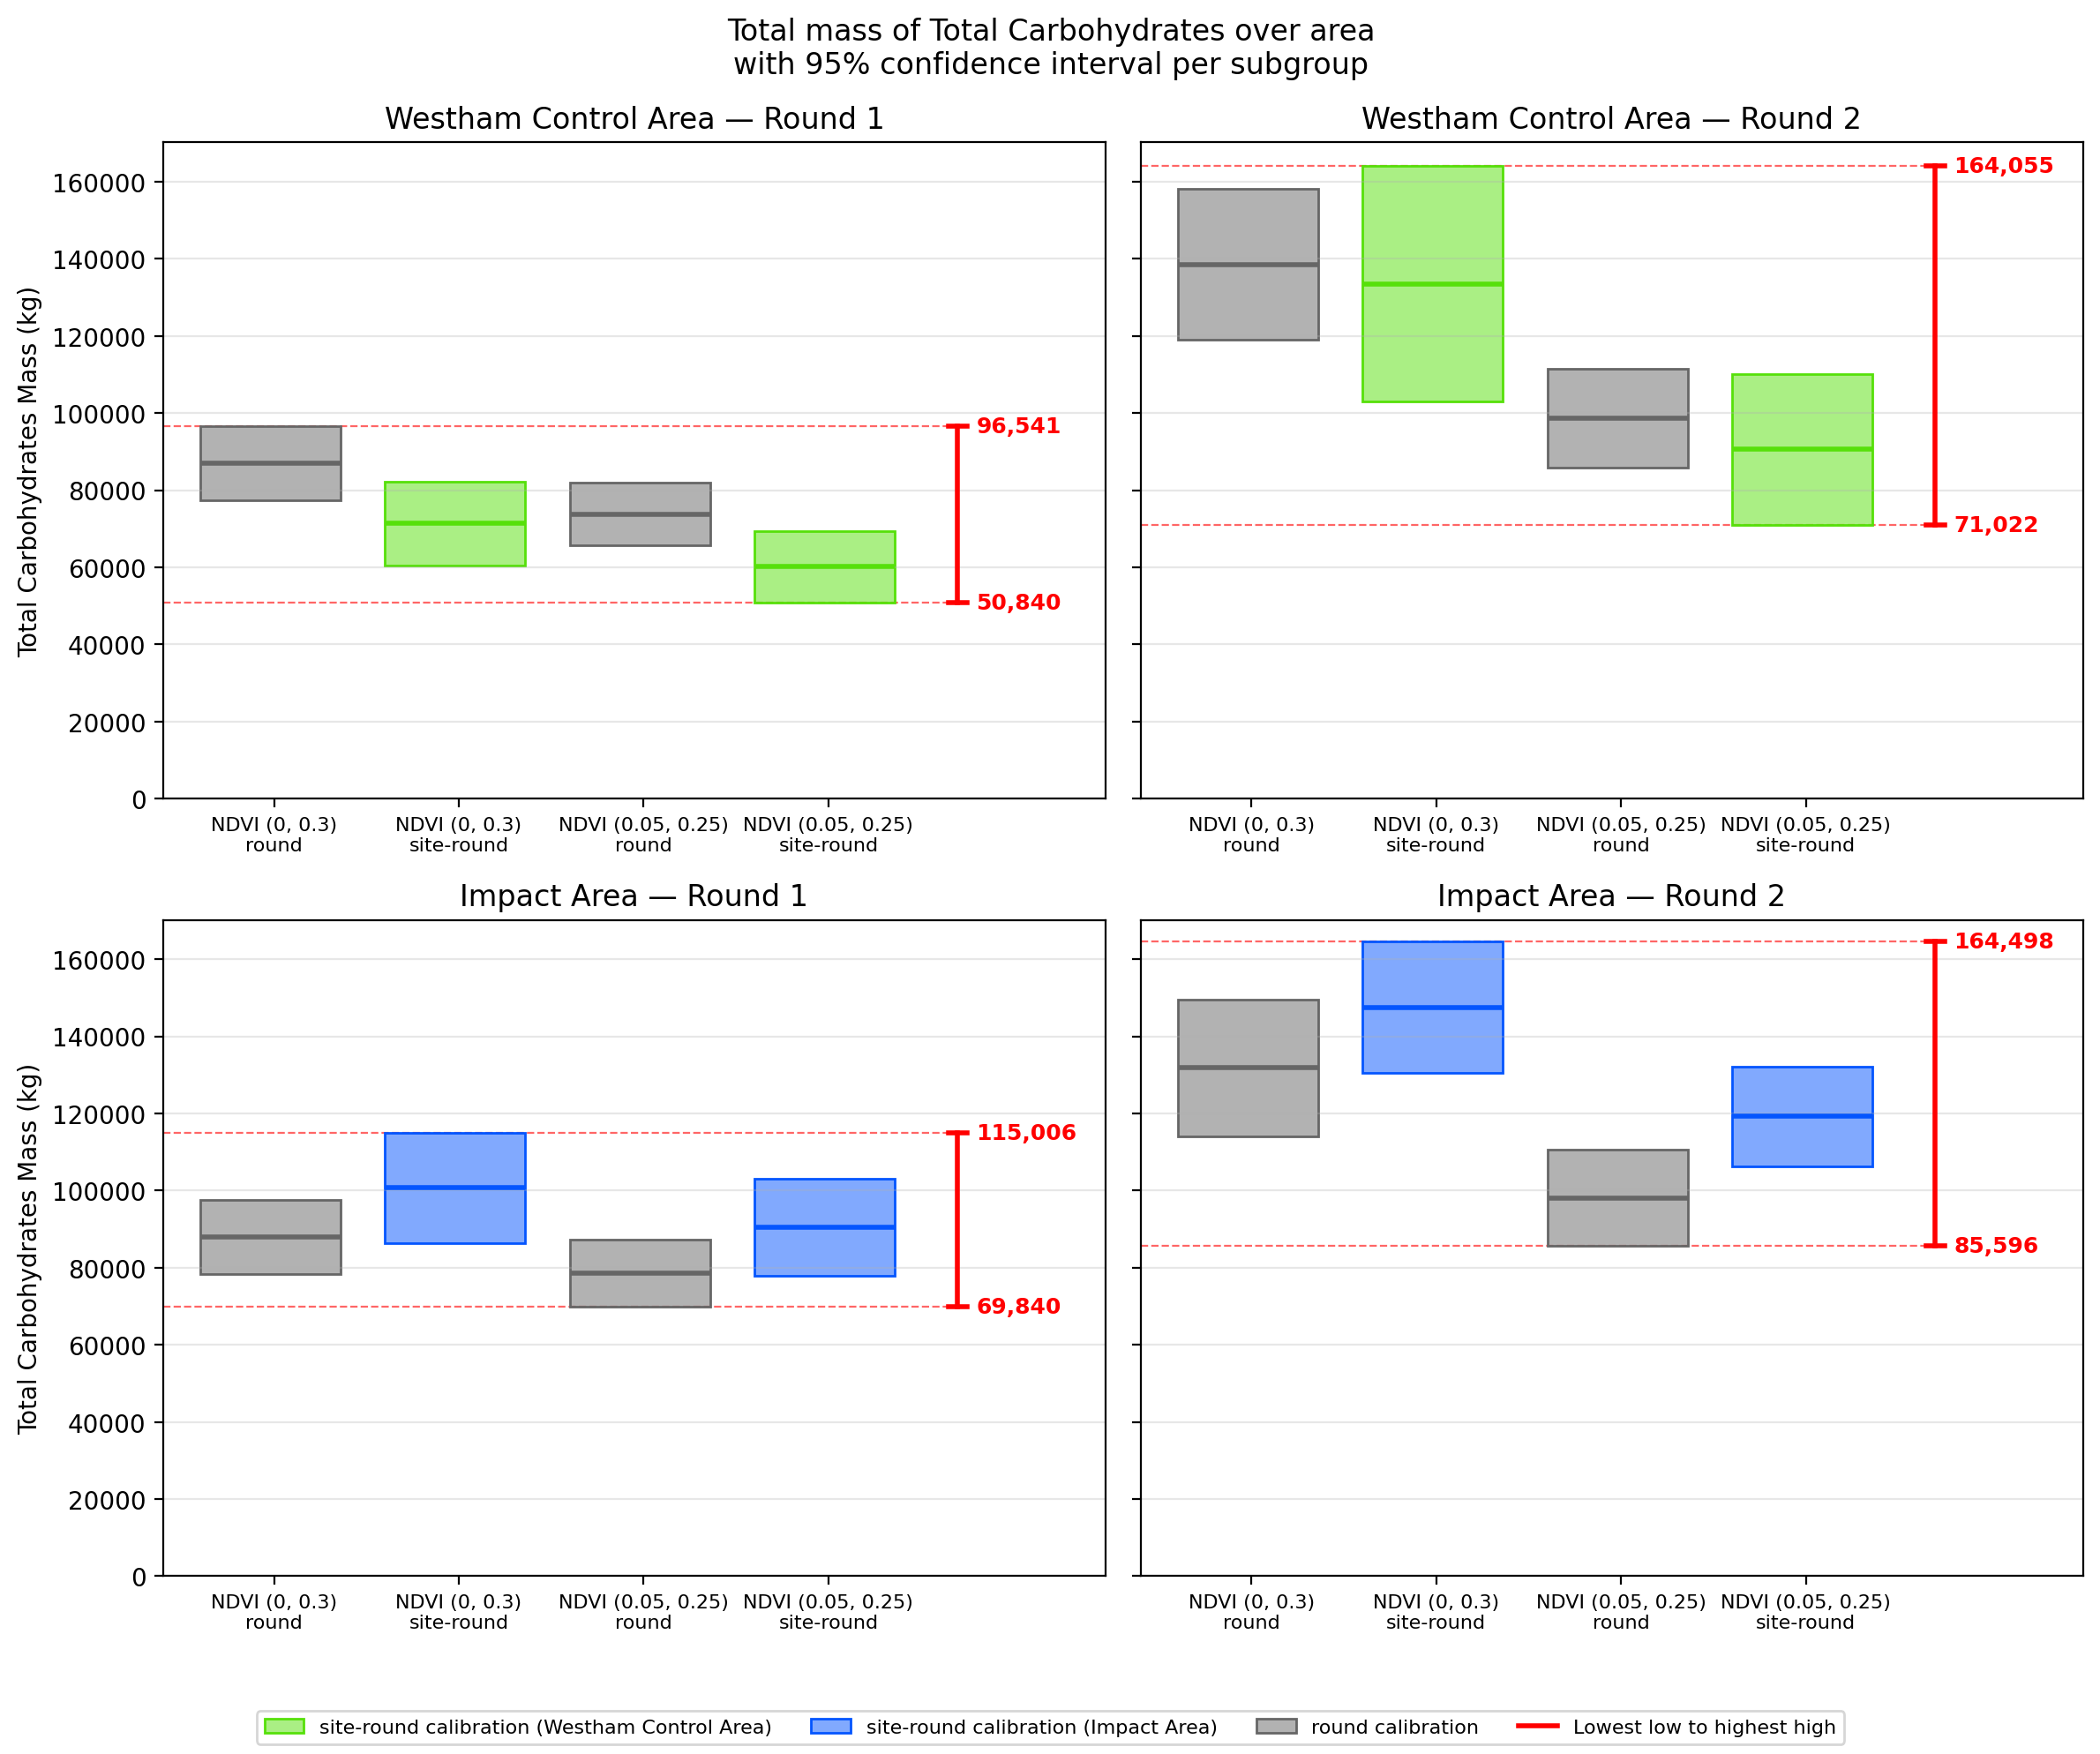

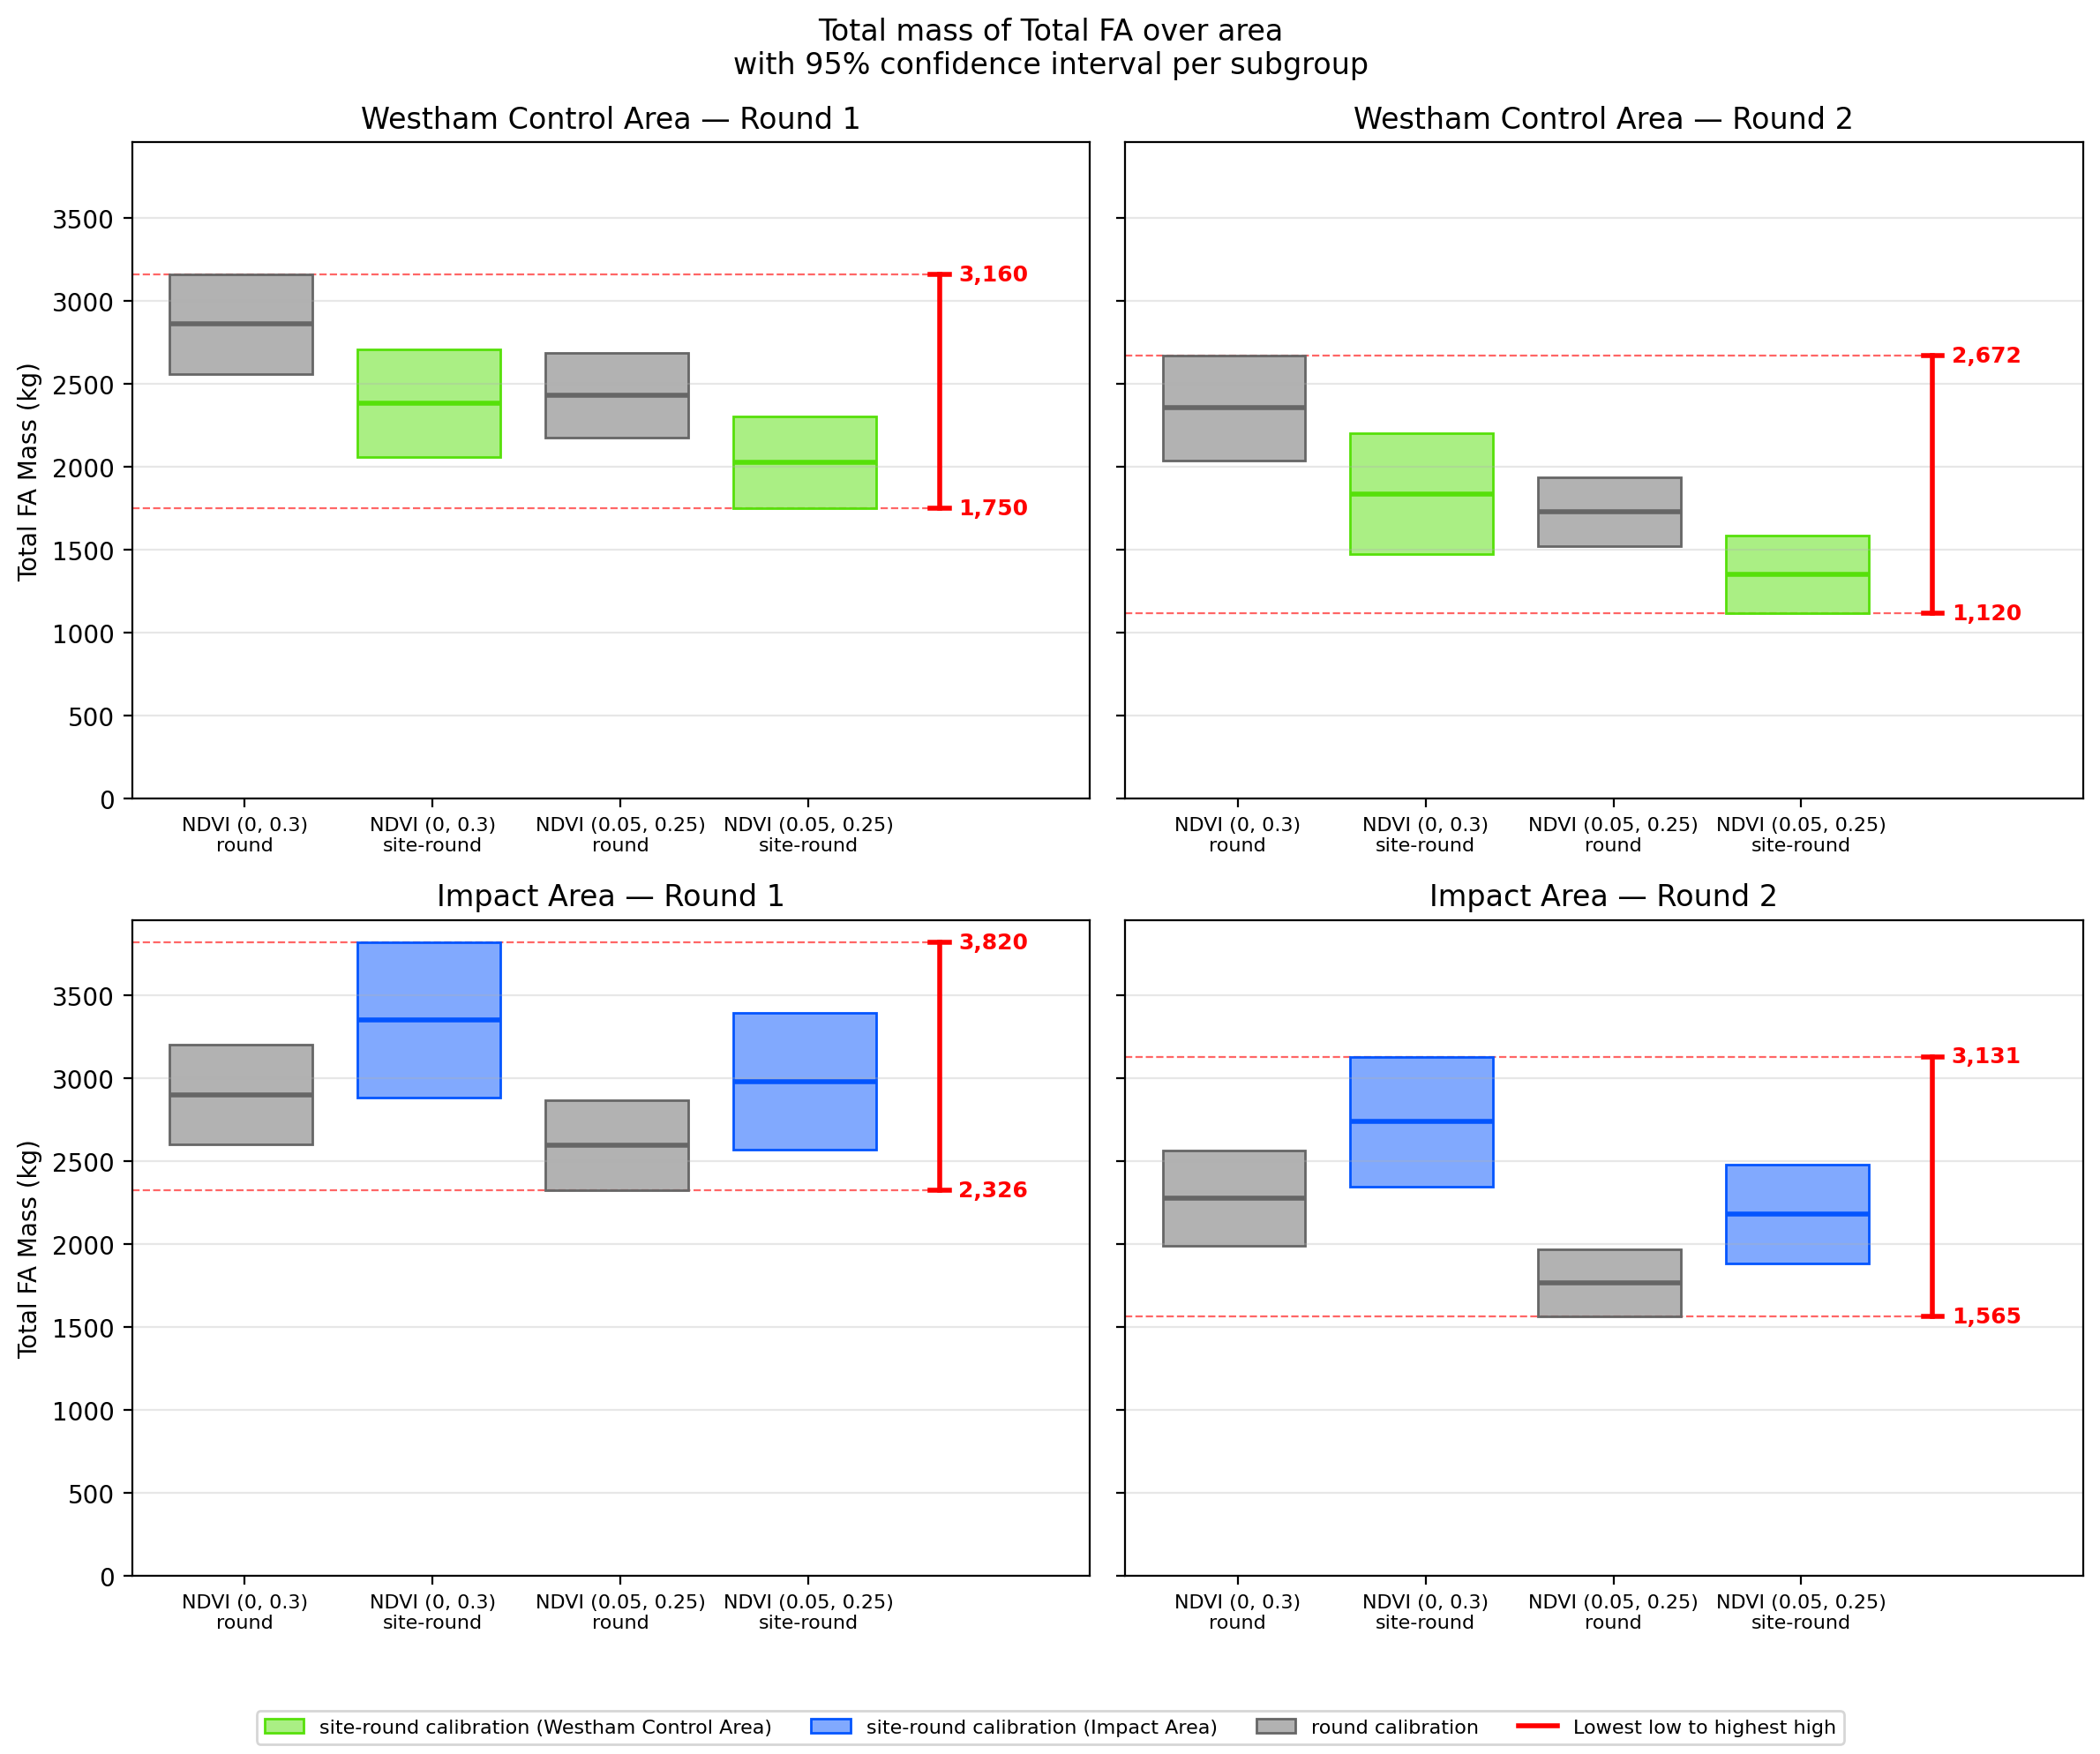

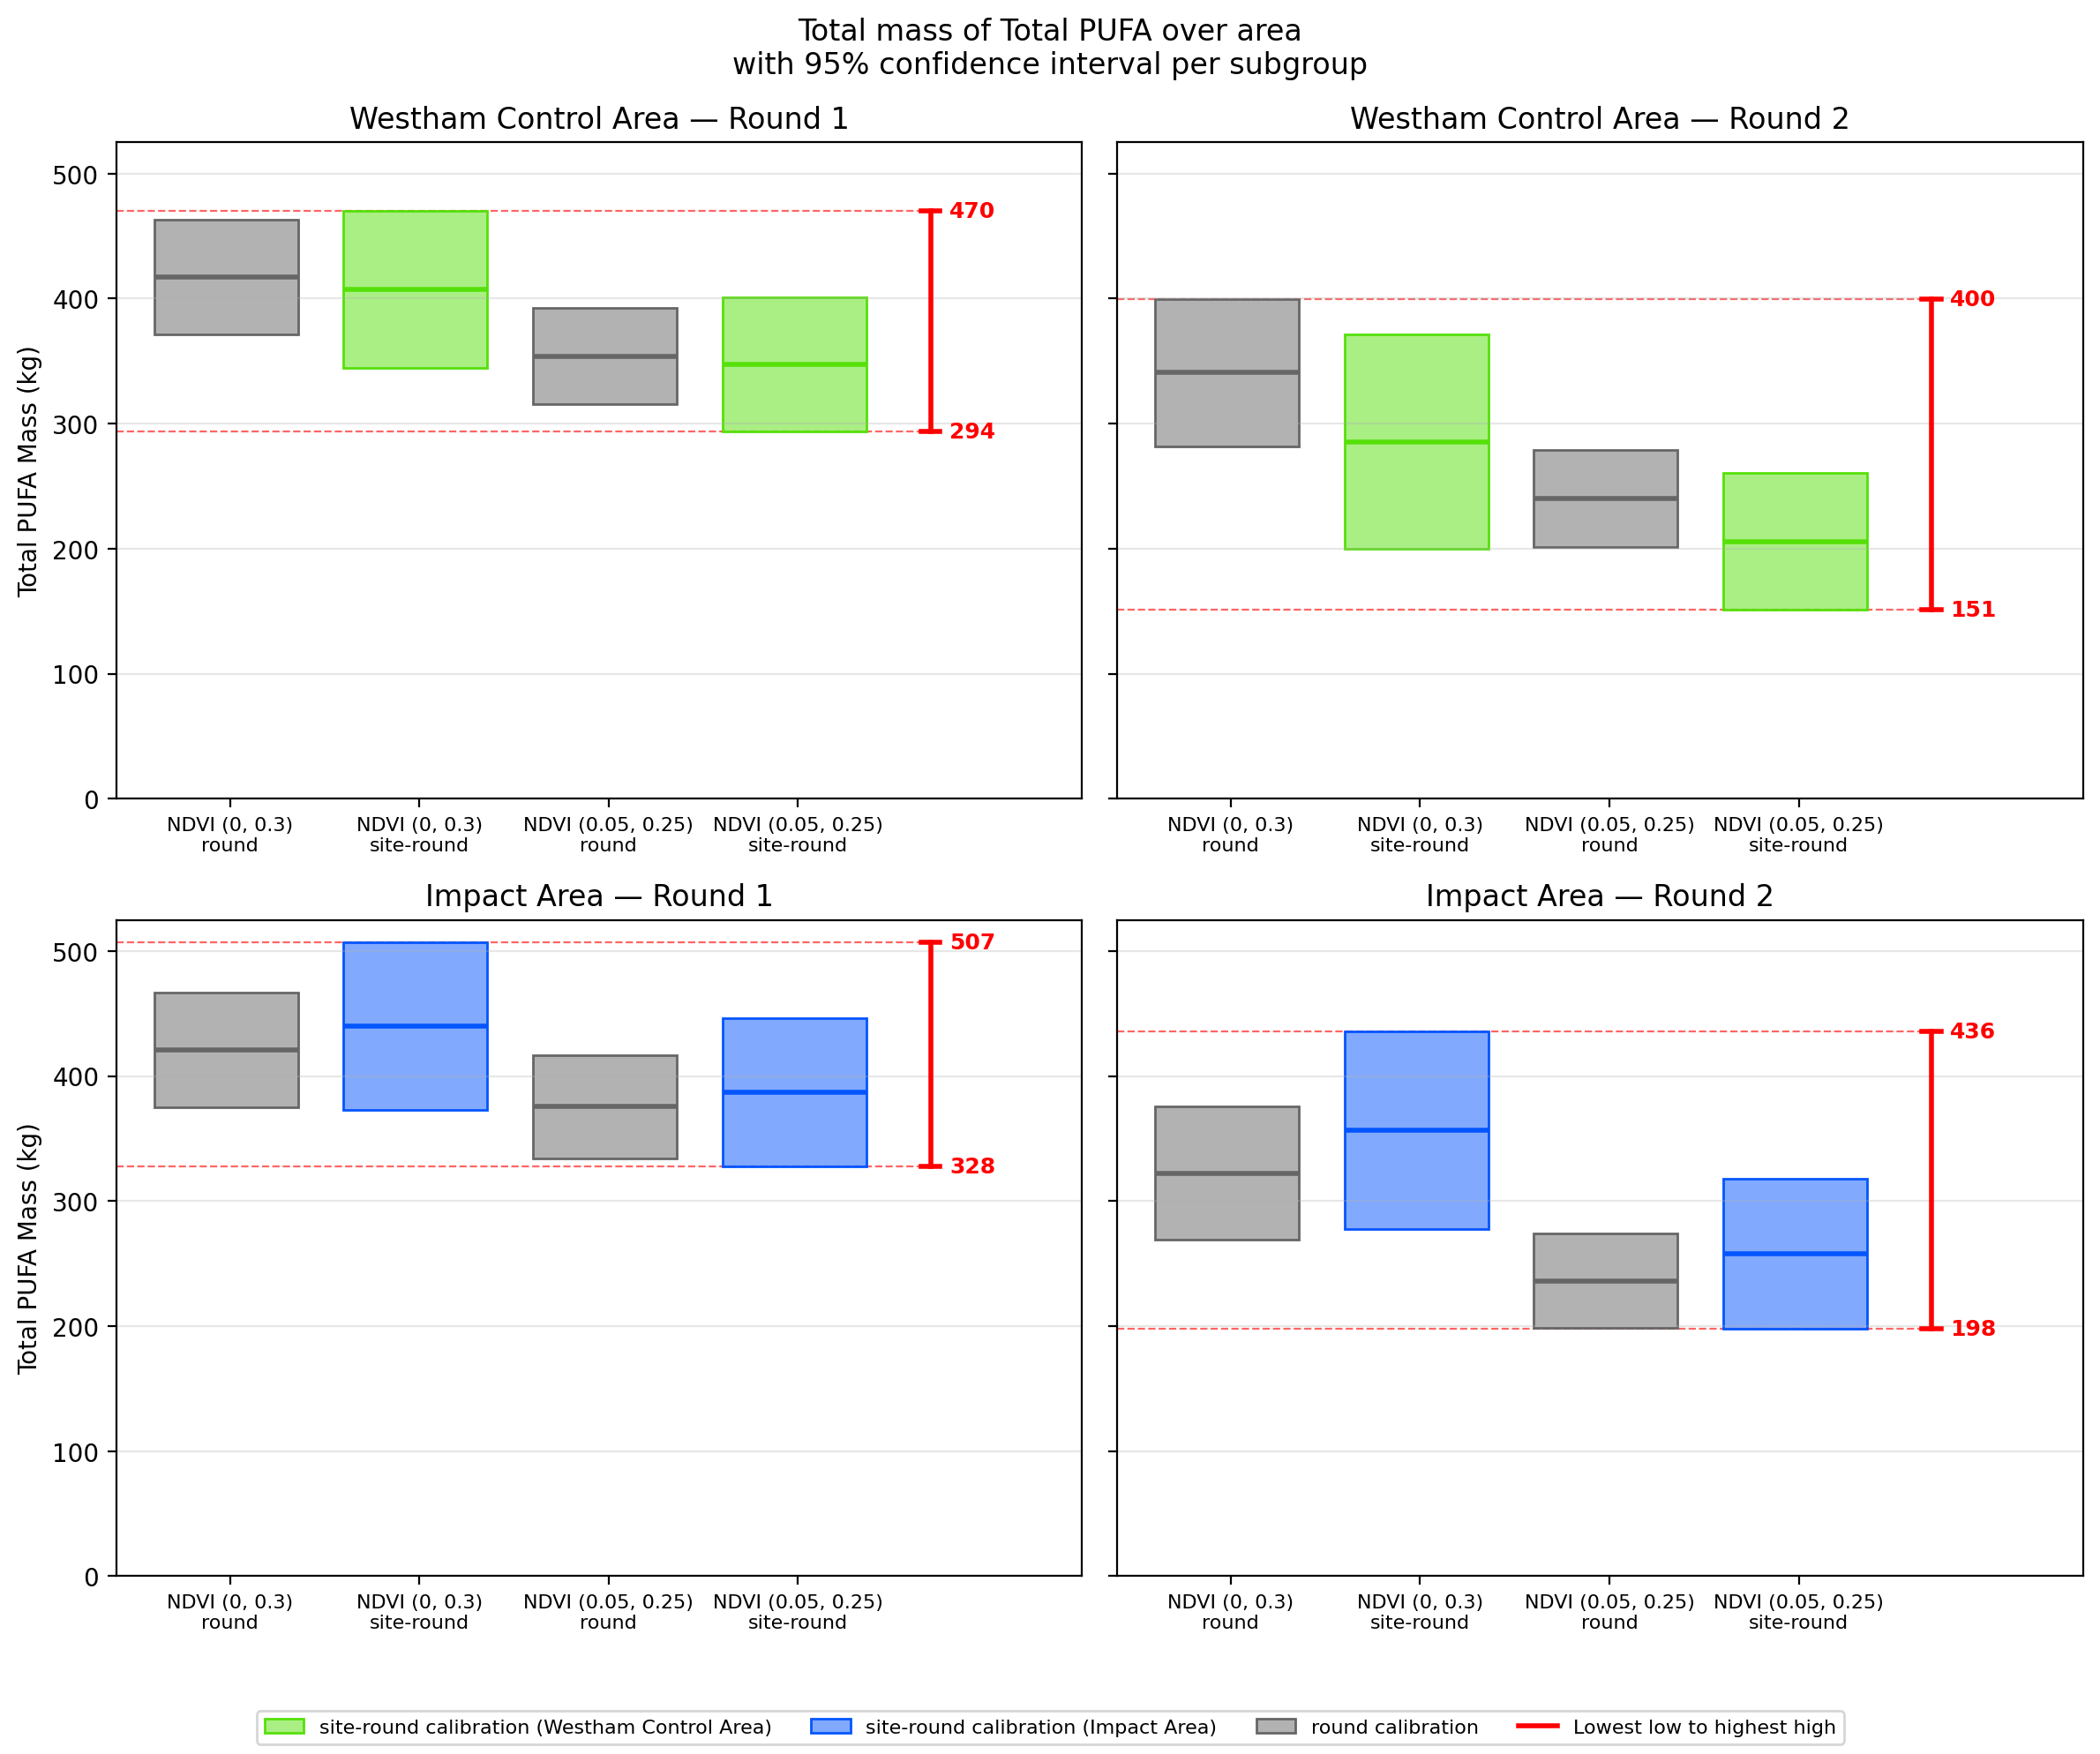

In [49]:
# Total-mass CI per variable and (site, round) panel. Bars of the same (NDVI range, calibration)
# group sit side by side per DLS mode (NoDLS hatched); the line marks the point estimate.
# The red vertical line spans the lowest low to the highest high of each panel.
import matplotlib.patches as patches
from matplotlib.colors import to_rgba

POOLED_COLOR = "0.4"
RANGE_COLOR = "red"
DLS_HATCHES = {"DLS": "", "NoDLS": "//"}
available_dls_modes = set(df_predictions_report.index.get_level_values("dls_mode"))
dls_modes_plotted = [m for m in PLOT_DLS_MODES if m in available_dls_modes]
multiple_dls_modes = len(dls_modes_plotted) > 1
bar_width = 0.8 / len(dls_modes_plotted)
df_plot_report = df_predictions_report[
    df_predictions_report.index.get_level_values("dls_mode").isin(dls_modes_plotted)
]


def format_kg(value):
    """Three significant figures, without scientific notation."""
    digits = max(0, 2 - int(np.floor(np.log10(abs(value))))) if value else 0
    return f"{value:,.{digits}f}"


for variable, df_var in df_plot_report.groupby(level="variable"):
    fig, axes = plt.subplots(
        len(PLOT_SITE_ORDER), len(ROUNDS), figsize=(12, 10), sharey=True, squeeze=False
    )
    y_min, y_max = df_var["total_kg_ci_low"].min(), df_var["total_kg_ci_high"].max()
    pad = 0.05 * (y_max - y_min)

    for row_i, site in enumerate(PLOT_SITE_ORDER):
        for col_i, rnd in enumerate(ROUNDS):
            ax = axes[row_i, col_i]
            ax.set_title(f"{SITE_LABELS[site]} \u2014 Round {rnd}")
            panel = df_var[
                (df_var.index.get_level_values("site") == site)
                & (df_var.index.get_level_values("round") == rnd)
            ]
            if panel.empty:
                ax.text(0.5, 0.5, "No data", ha="center", va="center", transform=ax.transAxes)
                continue

            group_keys = list(
                dict.fromkeys(zip(
                    panel.index.get_level_values("ndvi_range"),
                    panel.index.get_level_values("calibration"),
                ))
            )
            tick_labels = []
            for g, (ndvi_range, calibration) in enumerate(group_keys):
                color = SITE_COLORS[site] if calibration == "site-round" else POOLED_COLOR
                group_rows = panel[
                    (panel.index.get_level_values("ndvi_range") == ndvi_range)
                    & (panel.index.get_level_values("calibration") == calibration)
                ]
                for index, values in group_rows.iterrows():
                    mode = index[panel.index.names.index("dls_mode")]
                    left = g + dls_modes_plotted.index(mode) * bar_width
                    ax.add_patch(
                        patches.Rectangle(
                            (left, values["total_kg_ci_low"]),
                            bar_width * 0.95,
                            values["total_kg_ci_high"] - values["total_kg_ci_low"],
                            facecolor=to_rgba(color, 0.5),
                            edgecolor=color,
                            hatch=DLS_HATCHES[mode] if multiple_dls_modes else "",
                        )
                    )
                    ax.hlines(
                        values["total_kg"], left, left + bar_width * 0.95,
                        color=color, linewidth=2,
                    )
                label = f"NDVI {ndvi_range}"
                if INCLUDE_ROUND_CALIBRATION:
                    label += f"\n{calibration}"
                tick_labels.append(label)

            # Lowest low and highest high of the panel, drawn to the right of the bars.
            panel_low, panel_high = panel["total_kg_ci_low"].min(), panel["total_kg_ci_high"].max()
            x_line = len(group_keys) + 0.1
            ax.plot([x_line, x_line], [panel_low, panel_high], color=RANGE_COLOR, linewidth=2, zorder=7)
            ax.hlines([panel_low, panel_high], -0.2, x_line + 0.05, color=RANGE_COLOR,
                      linestyle="--", linewidth=0.8, alpha=0.6, zorder=0)
            for value in (panel_low, panel_high):
                ax.plot([x_line - 0.05, x_line + 0.05], [value, value], color=RANGE_COLOR, linewidth=2, zorder=7)
                ax.text(x_line + 0.1, value, format_kg(value), color=RANGE_COLOR,
                        va="center", ha="left", fontsize=9, fontweight="bold")

            ax.set_xlim(-0.2, len(group_keys) + 0.9)
            ax.set_xticks([g + 0.4 for g in range(len(group_keys))], tick_labels, fontsize=8)
            ax.grid(axis="y", alpha=0.3)
            if col_i == 0:
                ax.set_ylabel(f"{variables_to_predict_labels_without_unit.get(variable)} Mass (kg)")

    for ax in axes.ravel():
        # ax.set_ylim(y_min - pad, y_max + pad)
        ax.set_ylim(0, y_max + pad)
        # ax.set_ylim(0, 300)

    # DLS modes are only listed when more than one is shown.
    legend_handles = []
    if multiple_dls_modes:
        legend_handles += [
            patches.Patch(facecolor=to_rgba("0.5", 0.5), edgecolor="0.3", hatch=DLS_HATCHES[mode], label=mode)
            for mode in dls_modes_plotted
        ]
    if INCLUDE_ROUND_CALIBRATION:
        legend_handles += [
            patches.Patch(facecolor=to_rgba(SITE_COLORS[s], 0.5), edgecolor=SITE_COLORS[s],
                          label=f"site-round calibration ({SITE_LABELS[s]})")
            for s in PLOT_SITE_ORDER
        ] + [
            patches.Patch(facecolor=to_rgba(POOLED_COLOR, 0.5), edgecolor=POOLED_COLOR,
                          label="round calibration")
        ]
    legend_handles.append(Line2D([0], [0], color=RANGE_COLOR, linewidth=2, label="Lowest low to highest high"))
    fig.legend(handles=legend_handles, loc="lower center", ncol=len(legend_handles), fontsize=8)
    # variable_without_unit, variable_unit = variable.split(" (")
    # variable_unit = variable_unit.rstrip(")")
    fig.suptitle(f"Total mass of {variables_to_predict_labels_without_unit.get(variable)} over area\nwith 95% confidence interval per subgroup")
    fig.tight_layout(rect=(0, 0.05, 1, 1))

    plt.show()


In [325]:
# df_mean_ndvi_by_dls = (
#     df_predictions_report["mean_ndvi"]
#     .droplevel(["variable", "calibration"])
#     .groupby(level=["site", "round", "ndvi_range", "dls_mode"]).first()
#     .unstack("dls_mode")
# )
# if {"DLS", "NoDLS"} <= set(df_mean_ndvi_by_dls.columns):
#     df_mean_ndvi_by_dls["NoDLS / DLS"] = df_mean_ndvi_by_dls["NoDLS"] / df_mean_ndvi_by_dls["DLS"]
# df_mean_ndvi_by_dls


In [326]:
# Compare total areas from with and without DLS


# END